In [2]:
from pathlib import Path
import os
from PIL import Image
import matplotlib.pyplot as plt
import random

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Data directory
DATASET_DIR = Path(
    r"Plant_Diseases_Dataset"
)
# Check the folder
print("Dataset path:", DATASET_DIR)
print("Dataset exists:", DATASET_DIR.exists())

Dataset path: Plant_Diseases_Dataset
Dataset exists: True


In [4]:
# Display the main folders in the dataset directory
if DATASET_DIR.exists():
    print("Folders:", [p.name for p in DATASET_DIR.iterdir() if p.is_dir()])

Folders: ['train', 'valid']


In [5]:
# Supported image formats
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Store image counts for each split
dataset_counts = {}

for split in ["train", "valid"]:
    split_dir = DATASET_DIR / split
    counts = {}

    for class_dir in sorted(split_dir.iterdir()):
        if class_dir.is_dir():
            image_count = sum(
                1
                for file in class_dir.rglob("*")
                if file.is_file()
                and file.suffix.lower() in IMAGE_EXTENSIONS
            )

            counts[class_dir.name] = image_count

    dataset_counts[split] = counts

    print(f"\n{'=' * 45}")
    print(f"{split.upper()} DATASET")
    print("=" * 45)

    for class_name, count in counts.items():
        print(f"{class_name:<45} {count:>6}")

    print(f"\nTotal images: {sum(counts.values())}")
    print(f"Number of classes: {len(counts)}")



TRAIN DATASET
Groundnut_early_leaf_spot                       1322
Groundnut_early_rust                            1064
Groundnut_healthy_leaf                          1462
Groundnut_late_leaf_spot                        1491
Groundnut_nutrition_deficiency                  1255
Groundnut_rust                                  1315
potato_early                                    1998
potato_healthy                                  2008
potato_late                                     1998
Tomato___Bacterial_spot                         1702
Tomato___Early_blight                           1920
Tomato___healthy                                1926
Tomato___Late_blight                            1848
Tomato___Leaf_Mold                              1882
Tomato___Septoria_leaf_spot                     1745
Tomato___Spider_mites_Two-spotted_spider_mite   1741
Tomato___Target_Spot                            1827
Tomato___Tomato_mosaic_virus                    1790
Tomato___Tomato_Yellow_Leaf_Cur

In [6]:

train_classes = set(dataset_counts["train"].keys())
valid_classes = set(dataset_counts["valid"].keys())

print("Classes in train:", len(train_classes))
print("Classes in valid:", len(valid_classes))

print("\nClasses missing from valid:")
print(sorted(train_classes - valid_classes) or "None")

print("\nClasses missing from train:")
print(sorted(valid_classes - train_classes) or "None")

print("\nDo class names match?", train_classes == valid_classes)


Classes in train: 19
Classes in valid: 19

Classes missing from valid:
None

Classes missing from train:
None

Do class names match? True


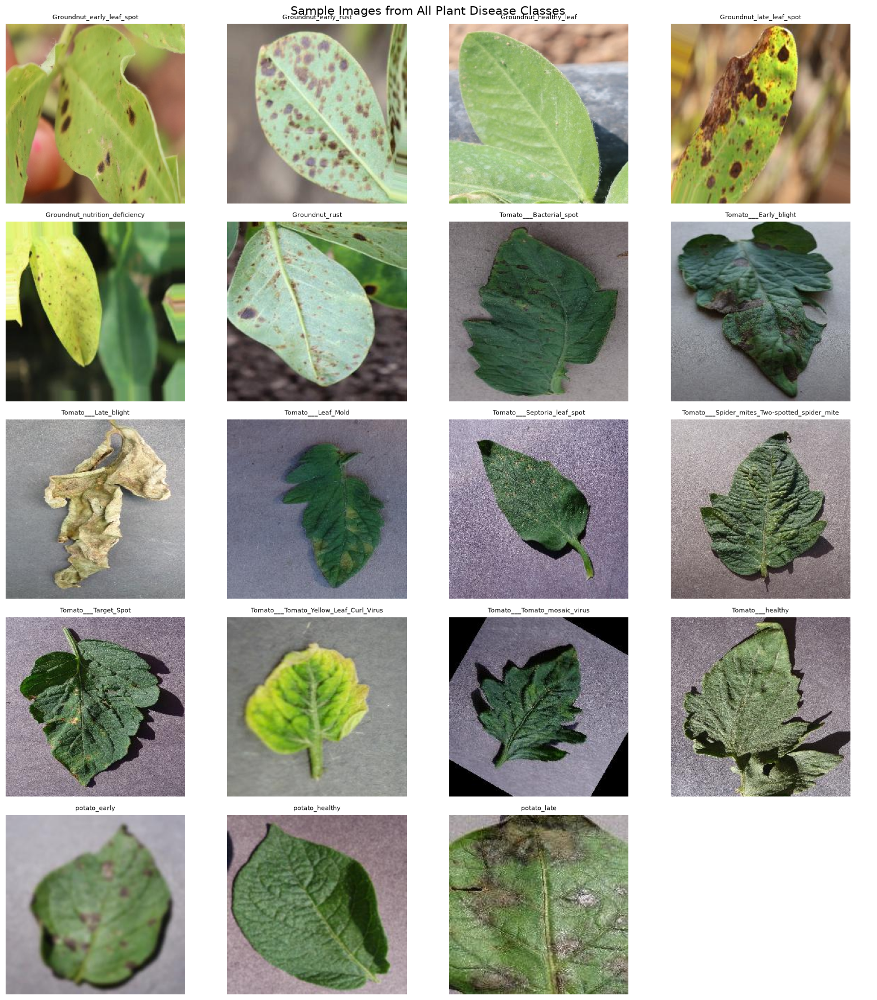

In [7]:
# Reproducible sample selection
random.seed(42)

fig, axes = plt.subplots(5, 4, figsize=(16, 18))
axes = axes.flatten()

train_dir = DATASET_DIR / "train"
class_names = sorted(
    folder.name for folder in train_dir.iterdir()
    if folder.is_dir()
)

for i, class_name in enumerate(class_names):
    class_dir = train_dir / class_name

    image_files = [
        file for file in class_dir.rglob("*")
        if file.is_file()
        and file.suffix.lower() in IMAGE_EXTENSIONS
    ]

    if not image_files:
        axes[i].set_title(f"{class_name}\nNo images")
        axes[i].axis("off")
        continue

    image_path = random.choice(image_files)

    with Image.open(image_path) as img:
        axes[i].imshow(img.convert("RGB"))

    axes[i].set_title(class_name, fontsize=8)
    axes[i].axis("off")

# Hide the unused 20th subplot
for j in range(len(class_names), len(axes)):
    axes[j].axis("off")
    
plt.suptitle("Sample Images from All Plant Disease Classes", fontsize=15)
plt.tight_layout()
plt.show()

In [8]:
## check for corrupted images
from PIL import Image
from collections import defaultdict

corrupted_images = defaultdict(list)
checked_images = defaultdict(int)

for split in ["train", "valid"]:
    split_dir = DATASET_DIR / split

    for class_dir in split_dir.iterdir():
        if not class_dir.is_dir():
            continue

        for image_path in class_dir.rglob("*"):
            if (
                not image_path.is_file()
                or image_path.suffix.lower() not in IMAGE_EXTENSIONS
            ):
                continue

            checked_images[split] += 1

            try:
                # Verify that the image file is readable
                with Image.open(image_path) as img:
                    img.verify()

            except Exception as error:
                corrupted_images[split].append(
                    (str(image_path), str(error))
                )

for split in ["train", "valid"]:
    print(f"\n{split.upper()}")
    print("Images checked:", checked_images[split])
    print("Corrupted images:", len(corrupted_images[split]))

    for path, error in corrupted_images[split][:10]:
        print("Problem:", path)
        print("Error:", error)

print("\nTotal corrupted images:",
      sum(len(items) for items in corrupted_images.values()))



TRAIN
Images checked: 32255
Corrupted images: 0

VALID
Images checked: 8170
Corrupted images: 0

Total corrupted images: 0


In [9]:
## duplicate images across train and valid splits
import hashlib
from collections import defaultdict

def calculate_sha256(image_path):
    sha256 = hashlib.sha256()

    with open(image_path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            sha256.update(chunk)

    return sha256.hexdigest()


hash_locations = defaultdict(list)

for split in ["train", "valid"]:
    split_dir = DATASET_DIR / split

    for class_dir in split_dir.iterdir():
        if not class_dir.is_dir():
            continue

        for image_path in class_dir.rglob("*"):
            if (
                image_path.is_file()
                and image_path.suffix.lower() in IMAGE_EXTENSIONS
            ):
                image_hash = calculate_sha256(image_path)

                hash_locations[image_hash].append({
                    "split": split,
                    "class": class_dir.name,
                    "path": str(image_path)
                })

# Identify identical files appearing in both splits
cross_split_duplicates = []

for locations in hash_locations.values():
    splits = {item["split"] for item in locations}

    if len(splits) > 1:
        cross_split_duplicates.append(locations)

print("Unique file hashes:", len(hash_locations))
print("Exact duplicate groups across train and valid:",
      len(cross_split_duplicates))

for group in cross_split_duplicates[:10]:
    print("\nDuplicate group:")
    for item in group:
        print(item["split"], "|", item["class"], "|", item["path"])


Unique file hashes: 38864
Exact duplicate groups across train and valid: 4

Duplicate group:
train | Tomato___healthy | Plant_Diseases_Dataset\train\Tomato___healthy\37aad83b-7ff8-4b35-b3ed-fb8e0f54910b___GH_HL Leaf 342.1.JPG
valid | Tomato___healthy | Plant_Diseases_Dataset\valid\Tomato___healthy\e786ac89-29fe-47e3-b49e-b9a9ee7edd9d___GH_HL Leaf 342.1.JPG

Duplicate group:
train | Tomato___healthy | Plant_Diseases_Dataset\train\Tomato___healthy\cfd491d6-4af5-4728-8f0e-0d330a07174a___GH_HL Leaf 482.2.JPG
valid | Tomato___healthy | Plant_Diseases_Dataset\valid\Tomato___healthy\1af0bfe1-4bcf-4b8b-be66-5d0953eb647e___GH_HL Leaf 482.2.JPG

Duplicate group:
train | Tomato___Late_blight | Plant_Diseases_Dataset\train\Tomato___Late_blight\5de6da85-f8c4-48c4-b463-3e6bd78884cc___GHLB_PS Leaf 24 Day 16.jpg
valid | Tomato___Late_blight | Plant_Diseases_Dataset\valid\Tomato___Late_blight\3fae9c64-18f0-4a67-9f97-554248bb1bed___GHLB_PS Leaf 24 Day 16.jpg

Duplicate group:
train | Tomato___Late_bligh

In [10]:

# Find exact duplicate groups, including duplicates within a split
within_split_duplicates = []

for image_hash, locations in hash_locations.items():
    splits = [item["split"] for item in locations]

    for split in ["train", "valid"]:
        same_split = [
            item for item in locations
            if item["split"] == split
        ]

        if len(same_split) > 1:
            within_split_duplicates.append({
                "split": split,
                "locations": same_split
            })

print("Duplicate groups within train:",
      sum(1 for g in within_split_duplicates if g["split"] == "train"))

print("Duplicate groups within valid:",
      sum(1 for g in within_split_duplicates if g["split"] == "valid"))

print("\nFirst 10 within-split duplicate groups:")

for group in within_split_duplicates[:10]:
    print(f"\nSplit: {group['split']}")
    for item in group["locations"]:
        print(item["class"], "|", item["path"])


Duplicate groups within train: 821
Duplicate groups within valid: 33

First 10 within-split duplicate groups:

Split: train
Groundnut_healthy_leaf | Plant_Diseases_Dataset\train\Groundnut_healthy_leaf\90.jpg
Groundnut_healthy_leaf | Plant_Diseases_Dataset\train\Groundnut_healthy_leaf\91_3.jpg

Split: train
Groundnut_healthy_leaf | Plant_Diseases_Dataset\train\Groundnut_healthy_leaf\IMG_00686.jpg
Groundnut_nutrition_deficiency | Plant_Diseases_Dataset\train\Groundnut_nutrition_deficiency\IMG_00686.jpg

Split: train
Groundnut_healthy_leaf | Plant_Diseases_Dataset\train\Groundnut_healthy_leaf\IMG_0685.jpg
Groundnut_nutrition_deficiency | Plant_Diseases_Dataset\train\Groundnut_nutrition_deficiency\IMG_0685.jpg

Split: train
Groundnut_healthy_leaf | Plant_Diseases_Dataset\train\Groundnut_healthy_leaf\IMG_0686.jpg
Groundnut_nutrition_deficiency | Plant_Diseases_Dataset\train\Groundnut_nutrition_deficiency\IMG_0686.jpg

Split: train
Groundnut_healthy_leaf | Plant_Diseases_Dataset\train\Ground

In [11]:

same_label_groups = 0
conflicting_label_groups = 0
conflict_examples = []

for image_hash, locations in hash_locations.items():
    if len(locations) < 2:
        continue

    labels = {item["class"] for item in locations}

    if len(labels) == 1:
        same_label_groups += 1
    else:
        conflicting_label_groups += 1
        conflict_examples.append(locations)

print("Duplicate groups with the same class label:",
      same_label_groups)

print("Duplicate groups with conflicting class labels:",
      conflicting_label_groups)

print("\nFirst 15 conflicting groups:")

for group in conflict_examples[:15]:
    print("\nLabels:", sorted({item["class"] for item in group}))
    for item in group:
        print(f"  {item['split']} | {item['path']}")


Duplicate groups with the same class label: 850
Duplicate groups with conflicting class labels: 8

First 15 conflicting groups:

Labels: ['Groundnut_healthy_leaf', 'Groundnut_nutrition_deficiency']
  train | Plant_Diseases_Dataset\train\Groundnut_healthy_leaf\IMG_00686.jpg
  train | Plant_Diseases_Dataset\train\Groundnut_nutrition_deficiency\IMG_00686.jpg

Labels: ['Groundnut_healthy_leaf', 'Groundnut_nutrition_deficiency']
  train | Plant_Diseases_Dataset\train\Groundnut_healthy_leaf\IMG_0685.jpg
  train | Plant_Diseases_Dataset\train\Groundnut_nutrition_deficiency\IMG_0685.jpg

Labels: ['Groundnut_healthy_leaf', 'Groundnut_nutrition_deficiency']
  train | Plant_Diseases_Dataset\train\Groundnut_healthy_leaf\IMG_0686.jpg
  train | Plant_Diseases_Dataset\train\Groundnut_nutrition_deficiency\IMG_0686.jpg

Labels: ['Groundnut_healthy_leaf', 'Groundnut_nutrition_deficiency']
  train | Plant_Diseases_Dataset\train\Groundnut_healthy_leaf\IMG_0688.jpg
  train | Plant_Diseases_Dataset\train\Gr

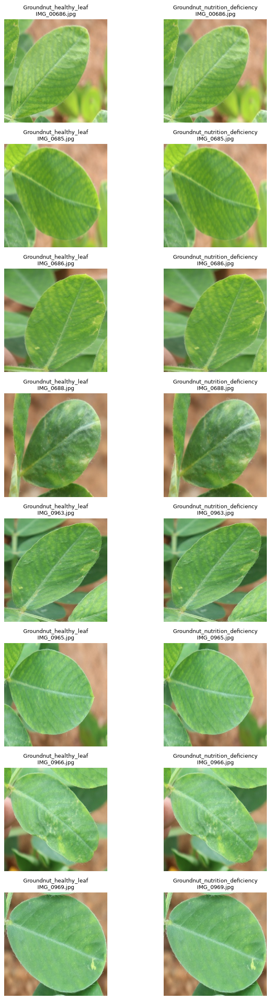

In [12]:

from PIL import Image
import matplotlib.pyplot as plt

conflict_classes = [
    "Groundnut_healthy_leaf",
    "Groundnut_nutrition_deficiency"
]

conflict_files = [
    "IMG_00686.jpg",
    "IMG_0685.jpg",
    "IMG_0686.jpg",
    "IMG_0688.jpg",
    "IMG_0963.jpg",
    "IMG_0965.jpg",
    "IMG_0966.jpg",
    "IMG_0969.jpg"
]

fig, axes = plt.subplots(
    len(conflict_files), 2, figsize=(9, 24)
)

for row, filename in enumerate(conflict_files):
    for col, class_name in enumerate(conflict_classes):
        image_path = DATASET_DIR / "train" / class_name / filename

        with Image.open(image_path) as img:
            axes[row, col].imshow(img.convert("RGB"))

        axes[row, col].set_title(
            f"{class_name}\n{filename}", fontsize=9
        )
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()


In [13]:

# Summarize exact duplicates by number of copies and labels

from collections import Counter

copy_counts = Counter()
duplicate_label_patterns = Counter()

for image_hash, locations in hash_locations.items():
    if len(locations) > 1:
        copy_counts[len(locations)] += 1

        labels = tuple(sorted({
            item["class"] for item in locations
        }))

        duplicate_label_patterns[labels] += 1

print("Duplicate groups by number of copies:")
for copies, groups in sorted(copy_counts.items()):
    print(f"{groups} groups contain {copies} copies")

print("\nMost frequent duplicate label patterns:")
for labels, groups in duplicate_label_patterns.most_common(15):
    print(f"{groups} groups: {' | '.join(labels)}")


Duplicate groups by number of copies:
533 groups contain 2 copies
160 groups contain 3 copies
104 groups contain 4 copies
48 groups contain 5 copies
8 groups contain 6 copies
2 groups contain 33 copies
2 groups contain 34 copies
1 groups contain 35 copies

Most frequent duplicate label patterns:
537 groups: potato_healthy
152 groups: potato_early
144 groups: potato_late
10 groups: Tomato___Late_blight
8 groups: Groundnut_healthy_leaf | Groundnut_nutrition_deficiency
6 groups: Tomato___healthy
1 groups: Groundnut_healthy_leaf


In [14]:

# Display the largest exact-duplicate groups

large_duplicate_groups = sorted(
    [
        (image_hash, locations)
        for image_hash, locations in hash_locations.items()
        if len(locations) >= 10
    ],
    key=lambda item: len(item[1]),
    reverse=True
)

print("Groups containing 10 or more copies:",
      len(large_duplicate_groups))

for image_hash, locations in large_duplicate_groups:
    print(f"\nCopies: {len(locations)}")
    print("Classes:", sorted({
        item["class"] for item in locations
    }))
    print("Splits:", sorted({
        item["split"] for item in locations
    }))

    for item in locations:
        print(" ", item["split"], "|", item["path"])


Groups containing 10 or more copies: 5

Copies: 35
Classes: ['potato_healthy']
Splits: ['valid']
  valid | Plant_Diseases_Dataset\valid\potato_healthy\potato_healthy_39 - Copy (10).JPG
  valid | Plant_Diseases_Dataset\valid\potato_healthy\potato_healthy_39 - Copy (11).JPG
  valid | Plant_Diseases_Dataset\valid\potato_healthy\potato_healthy_39 - Copy (12).JPG
  valid | Plant_Diseases_Dataset\valid\potato_healthy\potato_healthy_39 - Copy (13).JPG
  valid | Plant_Diseases_Dataset\valid\potato_healthy\potato_healthy_39 - Copy (14).JPG
  valid | Plant_Diseases_Dataset\valid\potato_healthy\potato_healthy_39 - Copy (15).JPG
  valid | Plant_Diseases_Dataset\valid\potato_healthy\potato_healthy_39 - Copy (16).JPG
  valid | Plant_Diseases_Dataset\valid\potato_healthy\potato_healthy_39 - Copy (17).JPG
  valid | Plant_Diseases_Dataset\valid\potato_healthy\potato_healthy_39 - Copy (18).JPG
  valid | Plant_Diseases_Dataset\valid\potato_healthy\potato_healthy_39 - Copy (19).JPG
  valid | Plant_Disease

In [15]:

import pandas as pd
from collections import defaultdict
from pathlib import Path
import hashlib

# Scan both original splits and group exact duplicates
hash_groups = defaultdict(list)

for split in ["train", "valid"]:
    split_dir = DATASET_DIR / split

    for class_dir in sorted(split_dir.iterdir()):
        if not class_dir.is_dir():
            continue

        for image_path in class_dir.rglob("*"):
            if (
                image_path.is_file()
                and image_path.suffix.lower() in IMAGE_EXTENSIONS
            ):
                image_hash = calculate_sha256(image_path)

                hash_groups[image_hash].append({
                    "hash": image_hash,
                    "split": split,
                    "class": class_dir.name,
                    "path": image_path
                })

# Build a proposed manifest: one representative per consistent label
manifest_rows = []
conflict_rows = []

for image_hash, items in hash_groups.items():
    labels = sorted({item["class"] for item in items})

    if len(labels) > 1:
        # Do not guess which conflicting label is correct
        for item in items:
            conflict_rows.append({
                "hash": image_hash,
                "class": item["class"],
                "split": item["split"],
                "path": str(item["path"])
            })
        continue

    # Select one representative, preferring train when available
    representative = sorted(
        items,
        key=lambda item: (
            item["split"] != "train",
            str(item["path"]).lower()
        )
    )[0]

    manifest_rows.append({
        "hash": image_hash,
        "class": labels[0],
        "source_split": representative["split"],
        "source_path": str(representative["path"]),
        "copies_found": len(items),
        "duplicate_copies_to_skip": len(items) - 1
    })

manifest_df = pd.DataFrame(manifest_rows)
conflicts_df = pd.DataFrame(conflict_rows)

# Save reports outside the original dataset folders
REPORT_DIR = DATASET_DIR.parent / "dataset_cleaning_reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

manifest_df.to_csv(
    REPORT_DIR / "deduplication_manifest.csv", index=False
)
conflicts_df.to_csv(
    REPORT_DIR / "label_conflicts_for_review.csv", index=False
)

print("Original images scanned:", sum(len(v) for v in hash_groups.values()))
print("Unique hashes:", len(hash_groups))
print("Images retained in proposed manifest:", len(manifest_df))
print("Images isolated for label-conflict review:", len(conflicts_df))
print("Duplicate copies to skip:",
      manifest_df["duplicate_copies_to_skip"].sum())
print("\nProposed unique images by class:")
display(
    manifest_df.groupby("class").size()
    .rename("unique_images")
    .reset_index()
)
print("\nReports saved to:", REPORT_DIR)


Original images scanned: 40425
Unique hashes: 38864
Images retained in proposed manifest: 38856
Images isolated for label-conflict review: 16
Duplicate copies to skip: 1553

Proposed unique images by class:


,class,unique_images
0,Groundnut_early_leaf_spot,1731
1,Groundnut_early_rust,1473
2,Groundnut_healthy_leaf,1862
3,Groundnut_late_leaf_spot,1896
4,Groundnut_nutrition_deficiency,1657
5,Groundnut_rust,1724
6,Tomato___Bacterial_spot,2127
7,Tomato___Early_blight,2400
8,Tomato___Late_blight,2300
9,Tomato___Leaf_Mold,2352



Reports saved to: dataset_cleaning_reports


In [16]:

# Check the arithmetic and report consistency

original_count = sum(len(v) for v in hash_groups.values())
unique_hash_count = len(hash_groups)
conflict_file_count = len(conflicts_df)
manifest_count = len(manifest_df)

print("Original image files:", original_count)
print("Unique hashes:", unique_hash_count)
print("Conflicting-label file occurrences:", conflict_file_count)
print("Manifest images:", manifest_count)

print("\nExpected manifest count if all conflict groups are excluded:",
      unique_hash_count - len({
          row["hash"] for row in conflict_rows
      }))

print("\nManifest hash duplicates:",
      manifest_df["hash"].duplicated().sum())


Original image files: 40425
Unique hashes: 38864
Conflicting-label file occurrences: 16
Manifest images: 38856

Expected manifest count if all conflict groups are excluded: 38856

Manifest hash duplicates: 0


In [17]:

import shutil

CLEAN_DIR = DATASET_DIR.parent / "Plant_Diseases_Cleaned"
CONFLICT_DIR = DATASET_DIR.parent / "Plant_Disease_Label_Conflicts"

# Safety check: don't overwrite an existing cleaned dataset
if CLEAN_DIR.exists() or CONFLICT_DIR.exists():
    raise FileExistsError(
        "A cleaned or conflict-review folder already exists. "
        "Choose a new output folder name before proceeding."
    )

# Create cleaned class folders and copy retained images
for _, row in manifest_df.iterrows():
    source = Path(row["source_path"])
    split = row["source_split"]
    class_name = row["class"]

    destination = CLEAN_DIR / split / class_name / source.name
    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(source, destination)

# Copy conflicting-label images to a review folder
for _, row in conflicts_df.iterrows():
    source = Path(row["path"])
    class_name = row["class"]

    destination = CONFLICT_DIR / class_name / source.name
    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(source, destination)

print("Cleaned dataset created:", CLEAN_DIR)
print("Conflict-review images copied:", CONFLICT_DIR)
print("Original dataset remains unchanged.")
print("Images copied to cleaned dataset:", len(manifest_df))
print("Conflict file occurrences copied:", len(conflicts_df))


Cleaned dataset created: Plant_Diseases_Cleaned
Conflict-review images copied: Plant_Disease_Label_Conflicts
Original dataset remains unchanged.
Images copied to cleaned dataset: 38856
Conflict file occurrences copied: 16


In [18]:
## verify the cleaned dataset

from pathlib import Path
from collections import Counter

CLEAN_DIR = DATASET_DIR.parent / "Plant_Diseases_Cleaned"

clean_counts = {}
clean_hashes = {}

for split in ["train", "valid"]:
    split_dir = CLEAN_DIR / split
    counts = Counter()
    hashes = []

    for class_dir in sorted(split_dir.iterdir()):
        if not class_dir.is_dir():
            continue

        for image_path in class_dir.rglob("*"):
            if (
                image_path.is_file()
                and image_path.suffix.lower() in IMAGE_EXTENSIONS
            ):
                counts[class_dir.name] += 1
                hashes.append(calculate_sha256(image_path))

    clean_counts[split] = counts
    clean_hashes[split] = hashes

    print(f"\n{split.upper()}")
    print("Images:", sum(counts.values()))
    print("Classes:", len(counts))

print("\nTotal cleaned images:",
      sum(sum(c.values()) for c in clean_counts.values()))

print("Duplicate hashes within cleaned train:",
      len(clean_hashes["train"]) - len(set(clean_hashes["train"])))

print("Duplicate hashes within cleaned valid:",
      len(clean_hashes["valid"]) - len(set(clean_hashes["valid"])))

print("Duplicate hashes across cleaned splits:",
      len(set(clean_hashes["train"]) & set(clean_hashes["valid"])))



TRAIN
Images: 30882
Classes: 19

VALID
Images: 7974
Classes: 19

Total cleaned images: 38856
Duplicate hashes within cleaned train: 0
Duplicate hashes within cleaned valid: 0
Duplicate hashes across cleaned splits: 0


In [19]:

import imagehash
from PIL import Image
from pathlib import Path
import pandas as pd

CLEAN_DIR = DATASET_DIR.parent / "Plant_Diseases_Cleaned"

def get_image_records(split):
    records = []

    for class_dir in sorted((CLEAN_DIR / split).iterdir()):
        if not class_dir.is_dir():
            continue

        for path in class_dir.rglob("*"):
            if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
                try:
                    with Image.open(path) as img:
                        phash = imagehash.phash(img.convert("RGB"))

                    records.append({
                        "split": split,
                        "class": class_dir.name,
                        "path": str(path),
                        "phash": phash
                    })
                except Exception as error:
                    print("Could not process:", path, error)

    return records

train_records = get_image_records("train")
valid_records = get_image_records("valid")

print("Train images processed:", len(train_records))
print("Validation images processed:", len(valid_records))


Train images processed: 30882
Validation images processed: 7974


In [20]:

# Compare each validation image against training images.
# Hamming distance <= 4 is a candidate threshold, not proof of duplication.

near_duplicate_candidates = []

for valid_item in valid_records:
    for train_item in train_records:
        distance = valid_item["phash"] - train_item["phash"]

        if distance <= 4:
            near_duplicate_candidates.append({
                "distance": distance,
                "train_class": train_item["class"],
                "valid_class": valid_item["class"],
                "train_path": train_item["path"],
                "valid_path": valid_item["path"]
            })

near_df = pd.DataFrame(near_duplicate_candidates)

report_path = DATASET_DIR.parent / "near_duplicate_candidates.csv"
near_df.to_csv(report_path, index=False)

print("Potential cross-split near-duplicate pairs:", len(near_df))
print("Report saved to:", report_path)

display(near_df.head(20))


Potential cross-split near-duplicate pairs: 86
Report saved to: near_duplicate_candidates.csv


,distance,train_class,valid_class,train_path,valid_path
0,2,potato_early,potato_early,Plant_Diseases_Cleaned\train\potato_early\pota...,Plant_Diseases_Cleaned\valid\potato_early\pota...
1,4,Tomato___Bacterial_spot,Tomato___Bacterial_spot,Plant_Diseases_Cleaned\train\Tomato___Bacteria...,Plant_Diseases_Cleaned\valid\Tomato___Bacteria...
2,4,Tomato___healthy,Tomato___healthy,Plant_Diseases_Cleaned\train\Tomato___healthy\...,Plant_Diseases_Cleaned\valid\Tomato___healthy\...
3,4,Tomato___healthy,Tomato___healthy,Plant_Diseases_Cleaned\train\Tomato___healthy\...,Plant_Diseases_Cleaned\valid\Tomato___healthy\...
4,4,Tomato___healthy,Tomato___healthy,Plant_Diseases_Cleaned\train\Tomato___healthy\...,Plant_Diseases_Cleaned\valid\Tomato___healthy\...
5,4,Tomato___healthy,Tomato___healthy,Plant_Diseases_Cleaned\train\Tomato___healthy\...,Plant_Diseases_Cleaned\valid\Tomato___healthy\...
6,4,Tomato___Tomato_mosaic_virus,Tomato___healthy,Plant_Diseases_Cleaned\train\Tomato___Tomato_m...,Plant_Diseases_Cleaned\valid\Tomato___healthy\...
7,4,Tomato___healthy,Tomato___healthy,Plant_Diseases_Cleaned\train\Tomato___healthy\...,Plant_Diseases_Cleaned\valid\Tomato___healthy\...
8,4,Tomato___healthy,Tomato___healthy,Plant_Diseases_Cleaned\train\Tomato___healthy\...,Plant_Diseases_Cleaned\valid\Tomato___healthy\...
9,2,Tomato___healthy,Tomato___healthy,Plant_Diseases_Cleaned\train\Tomato___healthy\...,Plant_Diseases_Cleaned\valid\Tomato___healthy\...


In [21]:

# Rank potentially suspicious pairs for manual review

near_df["different_labels"] = (
    near_df["train_class"] != near_df["valid_class"]
)

review_df = near_df.sort_values(
    ["different_labels", "distance"],
    ascending=[False, True]
).reset_index(drop=True)

print("Total candidate pairs:", len(review_df))
print("Pairs with different labels:",
      review_df["different_labels"].sum())

display(
    review_df[
        [
            "distance",
            "different_labels",
            "train_class",
            "valid_class",
            "train_path",
            "valid_path"
        ]
    ].head(25)
)


Total candidate pairs: 86
Pairs with different labels: 3


,distance,different_labels,train_class,valid_class,train_path,valid_path
0,4,True,Tomato___Tomato_mosaic_virus,Tomato___healthy,Plant_Diseases_Cleaned\train\Tomato___Tomato_m...,Plant_Diseases_Cleaned\valid\Tomato___healthy\...
1,4,True,Tomato___Leaf_Mold,Tomato___Late_blight,Plant_Diseases_Cleaned\train\Tomato___Leaf_Mol...,Plant_Diseases_Cleaned\valid\Tomato___Late_bli...
2,4,True,Tomato___Septoria_leaf_spot,Tomato___Spider_mites_Two-spotted_spider_mite,Plant_Diseases_Cleaned\train\Tomato___Septoria...,Plant_Diseases_Cleaned\valid\Tomato___Spider_m...
3,0,False,Tomato___healthy,Tomato___healthy,Plant_Diseases_Cleaned\train\Tomato___healthy\...,Plant_Diseases_Cleaned\valid\Tomato___healthy\...
4,0,False,Tomato___Target_Spot,Tomato___Target_Spot,Plant_Diseases_Cleaned\train\Tomato___Target_S...,Plant_Diseases_Cleaned\valid\Tomato___Target_S...
5,0,False,Tomato___Tomato_mosaic_virus,Tomato___Tomato_mosaic_virus,Plant_Diseases_Cleaned\train\Tomato___Tomato_m...,Plant_Diseases_Cleaned\valid\Tomato___Tomato_m...
6,2,False,potato_early,potato_early,Plant_Diseases_Cleaned\train\potato_early\pota...,Plant_Diseases_Cleaned\valid\potato_early\pota...
7,2,False,Tomato___healthy,Tomato___healthy,Plant_Diseases_Cleaned\train\Tomato___healthy\...,Plant_Diseases_Cleaned\valid\Tomato___healthy\...
8,2,False,Tomato___healthy,Tomato___healthy,Plant_Diseases_Cleaned\train\Tomato___healthy\...,Plant_Diseases_Cleaned\valid\Tomato___healthy\...
9,2,False,Tomato___healthy,Tomato___healthy,Plant_Diseases_Cleaned\train\Tomato___healthy\...,Plant_Diseases_Cleaned\valid\Tomato___healthy\...


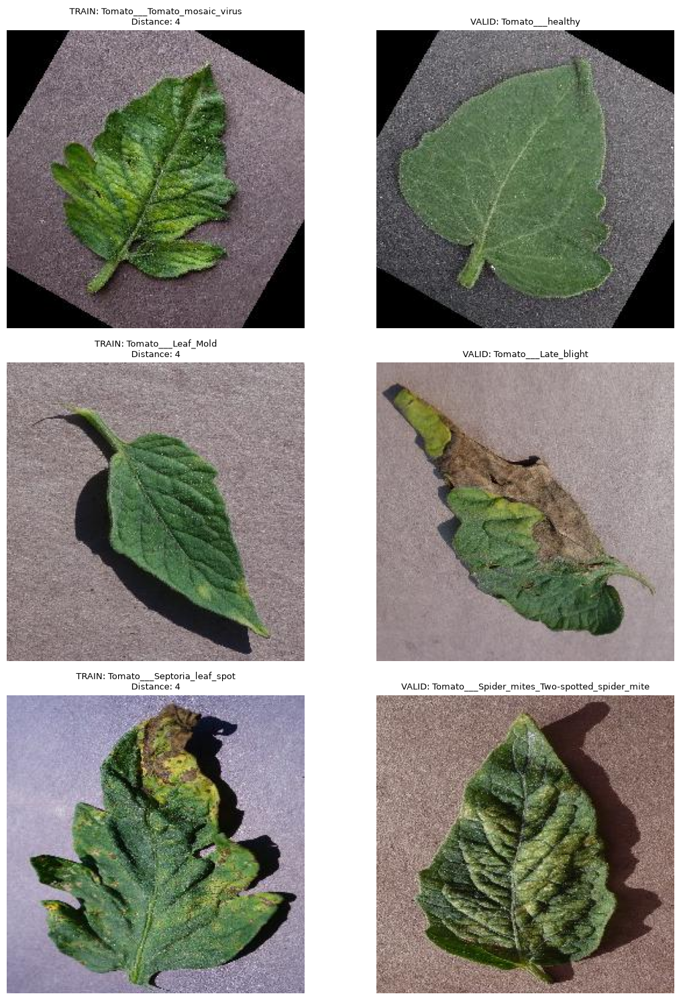

In [22]:
# A distance of 4 does not prove the images are duplicates. Let's compare them visually. Tomato_healthy and Tomato_healthy images with a distance of 4 are likely the same image, but one is rotated. Let's visualize them.

import matplotlib.pyplot as plt
from PIL import Image

# Show the three cross-label candidates side by side
different_label_pairs = (
    review_df[review_df["different_labels"]]
    .reset_index(drop=True)
)

fig, axes = plt.subplots(3, 2, figsize=(12, 15))

for i, row in different_label_pairs.iterrows():
    with Image.open(row["train_path"]) as img:
        axes[i, 0].imshow(img.convert("RGB"))

    axes[i, 0].set_title(
        f"TRAIN: {row['train_class']}\n"
        f"Distance: {row['distance']}",
        fontsize=9
    )
    axes[i, 0].axis("off")

    with Image.open(row["valid_path"]) as img:
        axes[i, 1].imshow(img.convert("RGB"))

    axes[i, 1].set_title(
        f"VALID: {row['valid_class']}",
        fontsize=9
    )
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()



In [23]:
# remaining candidates with the same label but a distance of 4 or less may also be duplicates. Let's visualize a few of them.

print("Candidate pairs by perceptual-hash distance:")
display(
    near_df["distance"]
    .value_counts()
    .sort_index()
    .rename_axis("Hamming distance")
    .reset_index(name="Number of pairs")
)

print("\nSame-label candidates with distance 0:")
display(
    near_df[
        (near_df["distance"] == 0)
        & (~near_df["different_labels"])
    ][
        ["train_class", "valid_class", "train_path", "valid_path"]
    ]
)


Candidate pairs by perceptual-hash distance:


,Hamming distance,Number of pairs
0,0,3
1,2,14
2,4,69



Same-label candidates with distance 0:


,train_class,valid_class,train_path,valid_path
19,Tomato___healthy,Tomato___healthy,Plant_Diseases_Cleaned\train\Tomato___healthy\...,Plant_Diseases_Cleaned\valid\Tomato___healthy\...
40,Tomato___Target_Spot,Tomato___Target_Spot,Plant_Diseases_Cleaned\train\Tomato___Target_S...,Plant_Diseases_Cleaned\valid\Tomato___Target_S...
67,Tomato___Tomato_mosaic_virus,Tomato___Tomato_mosaic_virus,Plant_Diseases_Cleaned\train\Tomato___Tomato_m...,Plant_Diseases_Cleaned\valid\Tomato___Tomato_m...


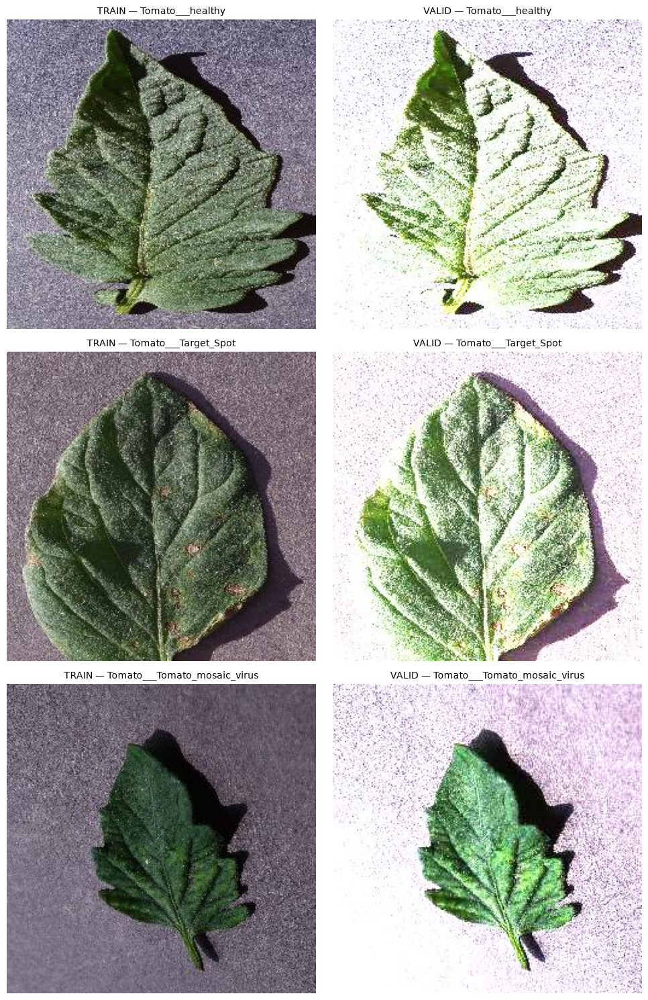

In [24]:

# Display the three same-label candidates with distance 0

exact_phash_pairs = near_df[
    (near_df["distance"] == 0)
    & (near_df["train_class"] == near_df["valid_class"])
].reset_index(drop=True)

fig, axes = plt.subplots(
    len(exact_phash_pairs), 2,
    figsize=(10, 5 * len(exact_phash_pairs))
)

if len(exact_phash_pairs) == 1:
    axes = [axes]

for i, row in exact_phash_pairs.iterrows():
    with Image.open(row["train_path"]) as img:
        axes[i, 0].imshow(img.convert("RGB"))
    axes[i, 0].set_title(
        f"TRAIN — {row['train_class']}", fontsize=10
    )
    axes[i, 0].axis("off")

    with Image.open(row["valid_path"]) as img:
        axes[i, 1].imshow(img.convert("RGB"))
    axes[i, 1].set_title(
        f"VALID — {row['valid_class']}", fontsize=10
    )
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()


In [25]:

from pathlib import Path
import shutil

CLEAN_DIR = DATASET_DIR.parent / "Plant_Diseases_Cleaned"
REVIEW_DIR = DATASET_DIR.parent / "Near_Duplicate_Review"

# The three pairs reviewed visually
pairs_to_review = exact_phash_pairs

# Safety: verify the expected number of pairs
assert len(pairs_to_review) == 3, (
    f"Expected 3 pairs, found {len(pairs_to_review)}"
)

# Create a review folder without overwriting existing files
if REVIEW_DIR.exists():
    raise FileExistsError(
        f"{REVIEW_DIR} already exists. Choose a new folder name."
    )

REVIEW_DIR.mkdir(parents=True)

moved_records = []

for _, row in pairs_to_review.iterrows():
    train_path = Path(row["train_path"])
    valid_path = Path(row["valid_path"])

    # Verify that both files exist and labels match
    if not train_path.exists() or not valid_path.exists():
        raise FileNotFoundError(
            f"Missing file in pair:\n{train_path}\n{valid_path}"
        )

    if row["train_class"] != row["valid_class"]:
        raise ValueError("Class labels differ; refusing to move this pair.")

    # Keep the training image; preserve the validation copy for review
    destination = (
        REVIEW_DIR / row["valid_class"] / valid_path.name
    )
    destination.parent.mkdir(parents=True, exist_ok=True)

    shutil.move(str(valid_path), str(destination))

    moved_records.append({
        "class": row["valid_class"],
        "kept_training_image": str(train_path),
        "review_copy": str(destination),
        "distance": int(row["distance"])
    })

# Save a record of the operation
import pandas as pd

step29_log = pd.DataFrame(moved_records)
log_path = DATASET_DIR.parent / "step29_near_duplicate_log.csv"
step29_log.to_csv(log_path, index=False)

print("Validation copies moved to review:", len(moved_records))
print("Training copies retained:", len(moved_records))
print("Review folder:", REVIEW_DIR)
print("Log saved:", log_path)
print("Original dataset remains unchanged.")


Validation copies moved to review: 3
Training copies retained: 3
Review folder: Near_Duplicate_Review
Log saved: step29_near_duplicate_log.csv
Original dataset remains unchanged.


In [26]:

from pathlib import Path

CLEAN_DIR = DATASET_DIR.parent / "Plant_Diseases_Cleaned"

def collect_hashes(split):
    records = []

    for class_dir in (CLEAN_DIR / split).iterdir():
        if not class_dir.is_dir():
            continue

        for path in class_dir.rglob("*"):
            if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
                records.append({
                    "class": class_dir.name,
                    "path": path,
                    "hash": calculate_sha256(path)
                })

    return records

train_clean = collect_hashes("train")
valid_clean = collect_hashes("valid")

train_hashes = {item["hash"] for item in train_clean}
valid_hashes = {item["hash"] for item in valid_clean}

print("Train images:", len(train_clean))
print("Validation images:", len(valid_clean))
print("Total cleaned images:", len(train_clean) + len(valid_clean))
print("Exact duplicate hashes across splits:",
      len(train_hashes & valid_hashes))
print("Review copies preserved:", len(step29_log))


Train images: 30882
Validation images: 7971
Total cleaned images: 38853
Exact duplicate hashes across splits: 0
Review copies preserved: 3


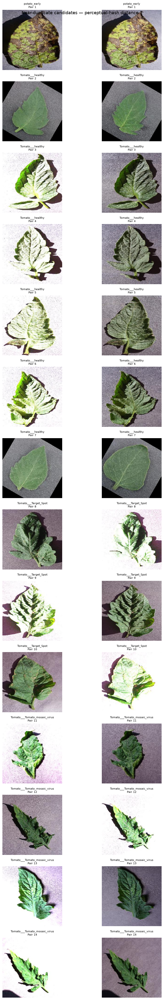

In [27]:

# Display all remaining candidate pairs with distance 2
import matplotlib.pyplot as plt
from PIL import Image

distance2_df = (
    near_df[near_df["distance"] == 2]
    .reset_index(drop=True)
)

fig, axes = plt.subplots(
    len(distance2_df), 2,
    figsize=(10, max(12, 3 * len(distance2_df)))
)

for i, row in distance2_df.iterrows():
    for col, path_col, label_col in [
        (0, "train_path", "train_class"),
        (1, "valid_path", "valid_class")
    ]:
        with Image.open(row[path_col]) as img:
            axes[i, col].imshow(img.convert("RGB"))

        axes[i, col].set_title(
            f"{row[label_col]}\nPair {i + 1}",
            fontsize=8
        )
        axes[i, col].axis("off")

plt.suptitle(
    "Near-duplicate candidates — perceptual-hash distance 2",
    fontsize=13
)
plt.tight_layout()
plt.show()


In [28]:

# Detailed report for the 14 distance-2 candidates

display(
    distance2_df[
        [
            "distance",
            "train_class",
            "valid_class",
            "train_path",
            "valid_path"
        ]
    ].to_string(index=False)
)


' distance                  train_class                  valid_class                                                                                                                  train_path                                                                                                                  valid_path\n        2                 potato_early                 potato_early                                                              Plant_Diseases_Cleaned\\train\\potato_early\\potato_early_715.JPG                                                              Plant_Diseases_Cleaned\\valid\\potato_early\\potato_early_344.JPG\n        2             Tomato___healthy             Tomato___healthy    Plant_Diseases_Cleaned\\train\\Tomato___healthy\\3e204d0d-cfdb-41a2-a68b-c3168305d099___GH_HL Leaf 441.1_new30degFlipLR.JPG      Plant_Diseases_Cleaned\\valid\\Tomato___healthy\\0de16216-510d-48c1-9ef0-78ce39328ff2___GH_HL Leaf 240_new30degFlipLR.JPG\n        2             Tomato___healt

In [29]:

from skimage.metrics import structural_similarity
from PIL import Image
import numpy as np
import pandas as pd

def compare_images(path1, path2):
    with Image.open(path1) as img1:
        a = np.asarray(img1.convert("RGB").resize((256, 256)))

    with Image.open(path2) as img2:
        b = np.asarray(img2.convert("RGB").resize((256, 256)))

    score = structural_similarity(
        a, b, channel_axis=2, data_range=255
    )
    return score

similarity_results = []

for _, row in distance2_df.iterrows():
    score = compare_images(row["train_path"], row["valid_path"])

    similarity_results.append({
        "distance": row["distance"],
        "class": row["train_class"],
        "similarity_score": round(score, 4),
        "train_path": row["train_path"],
        "valid_path": row["valid_path"]
    })

similarity_df = pd.DataFrame(similarity_results)

display(
    similarity_df.sort_values(
        "similarity_score", ascending=False
    )
)


,distance,class,similarity_score,train_path,valid_path
12,2,Tomato___Tomato_mosaic_virus,0.5599,Plant_Diseases_Cleaned\train\Tomato___Tomato_m...,Plant_Diseases_Cleaned\valid\Tomato___Tomato_m...
13,2,Tomato___Tomato_mosaic_virus,0.5208,Plant_Diseases_Cleaned\train\Tomato___Tomato_m...,Plant_Diseases_Cleaned\valid\Tomato___Tomato_m...
10,2,Tomato___Tomato_mosaic_virus,0.4653,Plant_Diseases_Cleaned\train\Tomato___Tomato_m...,Plant_Diseases_Cleaned\valid\Tomato___Tomato_m...
5,2,Tomato___healthy,0.4641,Plant_Diseases_Cleaned\train\Tomato___healthy\...,Plant_Diseases_Cleaned\valid\Tomato___healthy\...
3,2,Tomato___healthy,0.4615,Plant_Diseases_Cleaned\train\Tomato___healthy\...,Plant_Diseases_Cleaned\valid\Tomato___healthy\...
2,2,Tomato___healthy,0.4604,Plant_Diseases_Cleaned\train\Tomato___healthy\...,Plant_Diseases_Cleaned\valid\Tomato___healthy\...
4,2,Tomato___healthy,0.4459,Plant_Diseases_Cleaned\train\Tomato___healthy\...,Plant_Diseases_Cleaned\valid\Tomato___healthy\...
8,2,Tomato___Target_Spot,0.4353,Plant_Diseases_Cleaned\train\Tomato___Target_S...,Plant_Diseases_Cleaned\valid\Tomato___Target_S...
9,2,Tomato___Target_Spot,0.4195,Plant_Diseases_Cleaned\train\Tomato___Target_S...,Plant_Diseases_Cleaned\valid\Tomato___Target_S...
7,2,Tomato___Target_Spot,0.4054,Plant_Diseases_Cleaned\train\Tomato___Target_S...,Plant_Diseases_Cleaned\valid\Tomato___Target_S...


In [30]:

# Display filename pairs to identify likely transformed copies

for _, row in distance2_df.iterrows():
    train_name = Path(row["train_path"]).name
    valid_name = Path(row["valid_path"]).name

    print(f"\nClass: {row['train_class']}")
    print("TRAIN:", train_name)
    print("VALID:", valid_name)
    print("Same filename:", train_name == valid_name)
    print("Matching base identifier:",
          train_name.split("_newPixel25")[0]
          == valid_name.split("_newPixel25")[0])



Class: potato_early
TRAIN: potato_early_715.JPG
VALID: potato_early_344.JPG
Same filename: False
Matching base identifier: False

Class: Tomato___healthy
TRAIN: 3e204d0d-cfdb-41a2-a68b-c3168305d099___GH_HL Leaf 441.1_new30degFlipLR.JPG
VALID: 0de16216-510d-48c1-9ef0-78ce39328ff2___GH_HL Leaf 240_new30degFlipLR.JPG
Same filename: False
Matching base identifier: False

Class: Tomato___healthy
TRAIN: 0de569a8-21c5-4d22-b9c9-ba0ef0f2b614___RS_HL 0314_newPixel25.JPG
VALID: 0de569a8-21c5-4d22-b9c9-ba0ef0f2b614___RS_HL 0314.JPG
Same filename: False
Matching base identifier: False

Class: Tomato___healthy
TRAIN: 1a02fa87-a194-482e-b4ac-8dec2064d793___RS_HL 0022_newPixel25.JPG
VALID: 1a02fa87-a194-482e-b4ac-8dec2064d793___RS_HL 0022.JPG
Same filename: False
Matching base identifier: False

Class: Tomato___healthy
TRAIN: 2a11ceb9-41c9-4f2e-bed9-ef1c1c7d479b___RS_HL 0371_newPixel25.JPG
VALID: 2a11ceb9-41c9-4f2e-bed9-ef1c1c7d479b___RS_HL 0371.JPG
Same filename: False
Matching base identifier: Fal

In [31]:

import re
from pathlib import Path

def base_identifier(filename):
    # Remove known image-transformation suffixes before the extension
    stem = Path(filename).stem
    stem = re.sub(r"_newPixel25$", "", stem)
    stem = re.sub(r"_new30degFlipLR$", "", stem)
    return stem

for _, row in distance2_df.iterrows():
    train_name = Path(row["train_path"]).name
    valid_name = Path(row["valid_path"]).name

    train_id = base_identifier(train_name)
    valid_id = base_identifier(valid_name)

    print(f"\nClass: {row['train_class']}")
    print("TRAIN:", train_name)
    print("VALID:", valid_name)
    print("Matching base identifier:", train_id == valid_id)



Class: potato_early
TRAIN: potato_early_715.JPG
VALID: potato_early_344.JPG
Matching base identifier: False

Class: Tomato___healthy
TRAIN: 3e204d0d-cfdb-41a2-a68b-c3168305d099___GH_HL Leaf 441.1_new30degFlipLR.JPG
VALID: 0de16216-510d-48c1-9ef0-78ce39328ff2___GH_HL Leaf 240_new30degFlipLR.JPG
Matching base identifier: False

Class: Tomato___healthy
TRAIN: 0de569a8-21c5-4d22-b9c9-ba0ef0f2b614___RS_HL 0314_newPixel25.JPG
VALID: 0de569a8-21c5-4d22-b9c9-ba0ef0f2b614___RS_HL 0314.JPG
Matching base identifier: True

Class: Tomato___healthy
TRAIN: 1a02fa87-a194-482e-b4ac-8dec2064d793___RS_HL 0022_newPixel25.JPG
VALID: 1a02fa87-a194-482e-b4ac-8dec2064d793___RS_HL 0022.JPG
Matching base identifier: True

Class: Tomato___healthy
TRAIN: 2a11ceb9-41c9-4f2e-bed9-ef1c1c7d479b___RS_HL 0371_newPixel25.JPG
VALID: 2a11ceb9-41c9-4f2e-bed9-ef1c1c7d479b___RS_HL 0371.JPG
Matching base identifier: True

Class: Tomato___healthy
TRAIN: 2a8f7c7a-fbd4-4669-90eb-61ee118db2a7___RS_HL 0126_newPixel25.JPG
VALID: 2

In [32]:

from pathlib import Path
import shutil
import pandas as pd

CLEAN_DIR = DATASET_DIR.parent / "Plant_Diseases_Cleaned"
REVIEW_DIR = DATASET_DIR.parent / "Near_Duplicate_Review"

# Select candidates with matching base identifiers
matching_pairs = []

for _, row in distance2_df.iterrows():
    train_name = Path(row["train_path"]).name
    valid_name = Path(row["valid_path"]).name

    if base_identifier(train_name) == base_identifier(valid_name):
        matching_pairs.append(row)

print("Pairs selected for duplicate review:", len(matching_pairs))

# Move validation copies, retaining the training copies
moved = []

for row in matching_pairs:
    train_path = Path(row["train_path"])
    valid_path = Path(row["valid_path"])

    if not train_path.exists() or not valid_path.exists():
        raise FileNotFoundError(
            f"Missing file:\n{train_path}\n{valid_path}"
        )

    destination = (
        REVIEW_DIR / row["valid_class"] / valid_path.name
    )

    if destination.exists():
        raise FileExistsError(
            f"Review file already exists: {destination}"
        )

    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.move(str(valid_path), str(destination))

    moved.append({
        "class": row["valid_class"],
        "train_path_kept": str(train_path),
        "validation_copy_moved": str(destination),
        "distance": int(row["distance"]),
        "reason": "Matching base identifier; likely transformed duplicate"
    })

# Append to the existing log
log_path = DATASET_DIR.parent / "step29_near_duplicate_log.csv"
new_log = pd.DataFrame(moved)

if log_path.exists():
    old_log = pd.read_csv(log_path)
    combined_log = pd.concat([old_log, new_log], ignore_index=True)
else:
    combined_log = new_log

combined_log.to_csv(log_path, index=False)

print("Validation copies moved:", len(moved))
print("Training copies retained:", len(moved))
print("Updated log:", log_path)
print("Original dataset remains unchanged.")


Pairs selected for duplicate review: 11
Validation copies moved: 11
Training copies retained: 11
Updated log: step29_near_duplicate_log.csv
Original dataset remains unchanged.


In [33]:
train_clean = collect_hashes("train")
valid_clean = collect_hashes("valid")

train_hashes = {item["hash"] for item in train_clean}
valid_hashes = {item["hash"] for item in valid_clean}

print("Training images:", len(train_clean))
print("Validation images:", len(valid_clean))
print("Total cleaned images:", len(train_clean) + len(valid_clean))

print("Exact duplicate hashes within train:",
      len(train_hashes) - len(set(item["hash"] for item in train_clean)))

print("Exact duplicate hashes within valid:",
      len(valid_hashes) - len(set(item["hash"] for item in valid_clean)))

print("Exact duplicates across splits:",
      len(train_hashes & valid_hashes))

print("Near-duplicate review log entries:",
      len(pd.read_csv(DATASET_DIR.parent / "step29_near_duplicate_log.csv")))


Training images: 30882
Validation images: 7960
Total cleaned images: 38842
Exact duplicate hashes within train: 0
Exact duplicate hashes within valid: 0
Exact duplicates across splits: 0
Near-duplicate review log entries: 14


In [34]:

import pandas as pd
from pathlib import Path

CANDIDATE_FILE = Path(
    r"C:\Intro_TO_AI_Project\near_duplicate_candidates.csv"
)

candidates = pd.read_csv(CANDIDATE_FILE)

print("Total candidate pairs:", len(candidates))
print("\nColumn names:")
print(candidates.columns.tolist())

print("\nFirst 5 rows:")
display(candidates.head())


Total candidate pairs: 86

Column names:
['distance', 'train_class', 'valid_class', 'train_path', 'valid_path']

First 5 rows:


,distance,train_class,valid_class,train_path,valid_path
0,2,potato_early,potato_early,Plant_Diseases_Cleaned\train\potato_early\pota...,Plant_Diseases_Cleaned\valid\potato_early\pota...
1,4,Tomato___Bacterial_spot,Tomato___Bacterial_spot,Plant_Diseases_Cleaned\train\Tomato___Bacteria...,Plant_Diseases_Cleaned\valid\Tomato___Bacteria...
2,4,Tomato___healthy,Tomato___healthy,Plant_Diseases_Cleaned\train\Tomato___healthy\...,Plant_Diseases_Cleaned\valid\Tomato___healthy\...
3,4,Tomato___healthy,Tomato___healthy,Plant_Diseases_Cleaned\train\Tomato___healthy\...,Plant_Diseases_Cleaned\valid\Tomato___healthy\...
4,4,Tomato___healthy,Tomato___healthy,Plant_Diseases_Cleaned\train\Tomato___healthy\...,Plant_Diseases_Cleaned\valid\Tomato___healthy\...


In [35]:

print("Candidate pairs by distance:")
display(
    candidates["distance"]
    .value_counts()
    .sort_index()
    .rename_axis("pHash distance")
    .to_frame("Number of pairs")
)

print("\nPairs with distance 4:")
display(
    candidates[candidates["distance"] == 4][
        ["distance", "train_class", "valid_class",
         "train_path", "valid_path"]
    ].head(10)
)


Candidate pairs by distance:


,Number of pairs
pHash distance,
0,3
2,14
4,69



Pairs with distance 4:


,distance,train_class,valid_class,train_path,valid_path
1,4,Tomato___Bacterial_spot,Tomato___Bacterial_spot,Plant_Diseases_Cleaned\train\Tomato___Bacteria...,Plant_Diseases_Cleaned\valid\Tomato___Bacteria...
2,4,Tomato___healthy,Tomato___healthy,Plant_Diseases_Cleaned\train\Tomato___healthy\...,Plant_Diseases_Cleaned\valid\Tomato___healthy\...
3,4,Tomato___healthy,Tomato___healthy,Plant_Diseases_Cleaned\train\Tomato___healthy\...,Plant_Diseases_Cleaned\valid\Tomato___healthy\...
4,4,Tomato___healthy,Tomato___healthy,Plant_Diseases_Cleaned\train\Tomato___healthy\...,Plant_Diseases_Cleaned\valid\Tomato___healthy\...
5,4,Tomato___healthy,Tomato___healthy,Plant_Diseases_Cleaned\train\Tomato___healthy\...,Plant_Diseases_Cleaned\valid\Tomato___healthy\...
6,4,Tomato___Tomato_mosaic_virus,Tomato___healthy,Plant_Diseases_Cleaned\train\Tomato___Tomato_m...,Plant_Diseases_Cleaned\valid\Tomato___healthy\...
7,4,Tomato___healthy,Tomato___healthy,Plant_Diseases_Cleaned\train\Tomato___healthy\...,Plant_Diseases_Cleaned\valid\Tomato___healthy\...
8,4,Tomato___healthy,Tomato___healthy,Plant_Diseases_Cleaned\train\Tomato___healthy\...,Plant_Diseases_Cleaned\valid\Tomato___healthy\...
11,4,Tomato___healthy,Tomato___healthy,Plant_Diseases_Cleaned\train\Tomato___healthy\...,Plant_Diseases_Cleaned\valid\Tomato___healthy\...
13,4,Tomato___healthy,Tomato___healthy,Plant_Diseases_Cleaned\train\Tomato___healthy\...,Plant_Diseases_Cleaned\valid\Tomato___healthy\...


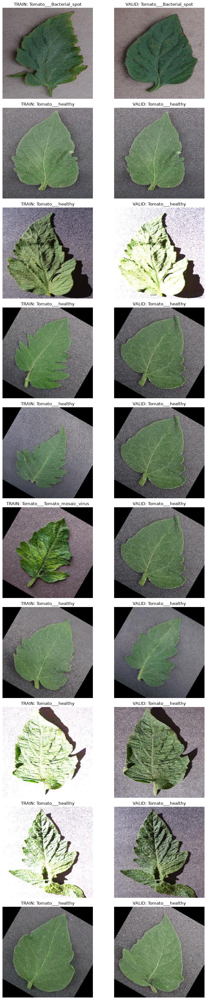

In [36]:

from PIL import Image, ImageOps, ImageDraw
from pathlib import Path
import matplotlib.pyplot as plt
import math

# Select a manageable first batch of 10 pairs
batch = candidates[candidates["distance"] == 4].head(10)

fig, axes = plt.subplots(len(batch), 2, figsize=(10, 4 * len(batch)))

if len(batch) == 1:
    axes = [axes]

for row_idx, (_, row) in enumerate(batch.iterrows()):
    for col_idx, path_col in enumerate(["train_path", "valid_path"]):
        image_path = Path(row[path_col])

        if not image_path.is_absolute():
            image_path = DATASET_DIR.parent / image_path

        ax = axes[row_idx][col_idx]
        try:
            with Image.open(image_path) as im:
                ax.imshow(im.convert("RGB"))
            ax.set_title(
                f"{'TRAIN' if col_idx == 0 else 'VALID'}: "
                f"{row['train_class'] if col_idx == 0 else row['valid_class']}"
            )
        except Exception as e:
            ax.text(0.5, 0.5, f"Could not load image\n{e}",
                    ha="center", va="center")

        ax.axis("off")

plt.tight_layout()
plt.show()


In [37]:

import pandas as pd
from pathlib import Path

CANDIDATE_FILE = Path(
    r"C:\Intro_TO_AI_Project\near_duplicate_candidates.csv"
)

REVIEW_FILE = Path(
    r"C:\Intro_TO_AI_Project\near_duplicate_distance4_review.csv"
)

candidates = pd.read_csv(CANDIDATE_FILE)

distance4 = candidates[candidates["distance"] == 4].copy()
distance4["decision"] = "REVIEW"
distance4["reason"] = ""

distance4.to_csv(REVIEW_FILE, index=False)

print("Distance-4 pairs:", len(distance4))
print("Review report saved to:", REVIEW_FILE)
print("No images were moved or deleted.")


Distance-4 pairs: 69
Review report saved to: C:\Intro_TO_AI_Project\near_duplicate_distance4_review.csv
No images were moved or deleted.


In [38]:

import re
from pathlib import Path
import pandas as pd

REVIEW_FILE = Path(
    r"C:\Intro_TO_AI_Project\near_duplicate_distance4_review.csv"
)

distance4 = pd.read_csv(REVIEW_FILE)

def base_identifier(filename):
    stem = Path(str(filename)).stem
    stem = re.sub(r"_newPixel25$", "", stem)
    stem = re.sub(r"_new30degFlipLR$", "", stem)
    return stem

distance4["train_filename"] = distance4["train_path"].apply(
    lambda p: Path(str(p)).name
)
distance4["valid_filename"] = distance4["valid_path"].apply(
    lambda p: Path(str(p)).name
)

distance4["matching_base_identifier"] = [
    base_identifier(a) == base_identifier(b)
    for a, b in zip(
        distance4["train_filename"],
        distance4["valid_filename"]
    )
]

print("Distance-4 candidate pairs:", len(distance4))
print(
    "Pairs with matching base identifiers:",
    int(distance4["matching_base_identifier"].sum())
)

display(
    distance4.loc[
        distance4["matching_base_identifier"],
        [
            "train_class", "valid_class", "distance",
            "train_filename", "valid_filename"
        ]
    ]
)


Distance-4 candidate pairs: 69
Pairs with matching base identifiers: 48


,train_class,valid_class,distance,train_filename,valid_filename
2,Tomato___healthy,Tomato___healthy,4,0c3eaf2d-8203-441d-9248-1c64e00b5b8b___RS_HL 0...,0c3eaf2d-8203-441d-9248-1c64e00b5b8b___RS_HL 0...
7,Tomato___healthy,Tomato___healthy,4,0caff918-5807-40f2-b9e4-7dd34a7bab5d___RS_HL 0...,0caff918-5807-40f2-b9e4-7dd34a7bab5d___RS_HL 0...
8,Tomato___healthy,Tomato___healthy,4,0e3feb72-86e5-41c2-a7ca-3295800e5777___RS_HL 0...,0e3feb72-86e5-41c2-a7ca-3295800e5777___RS_HL 0...
10,Tomato___healthy,Tomato___healthy,4,1d1017be-8cd6-4967-894b-1b9fb89d7d6e___RS_HL 0...,1d1017be-8cd6-4967-894b-1b9fb89d7d6e___RS_HL 0...
11,Tomato___healthy,Tomato___healthy,4,1e1aa3d8-d12f-47e1-b316-b8656ab3f2b6___RS_HL 0...,1e1aa3d8-d12f-47e1-b316-b8656ab3f2b6___RS_HL 0...
12,Tomato___healthy,Tomato___healthy,4,2d6ecece-b67e-42f1-924b-3a5dbd95d5ef___RS_HL 0...,2d6ecece-b67e-42f1-924b-3a5dbd95d5ef___RS_HL 0...
13,Tomato___healthy,Tomato___healthy,4,2e875abf-377c-4663-a406-e02984215fa6___RS_HL 0...,2e875abf-377c-4663-a406-e02984215fa6___RS_HL 0...
15,Tomato___healthy,Tomato___healthy,4,2e97e18f-8ae2-4d5d-b7fb-64baeead1ed4___GH_HL L...,2e97e18f-8ae2-4d5d-b7fb-64baeead1ed4___GH_HL L...
17,Tomato___healthy,Tomato___healthy,4,2fb5c266-b7ec-4b31-91b4-3f2dc9b0cdcb___RS_HL 0...,2fb5c266-b7ec-4b31-91b4-3f2dc9b0cdcb___RS_HL 0...
18,Tomato___healthy,Tomato___healthy,4,3a211a87-cac9-4393-84ca-51e240e1b043___RS_HL 0...,3a211a87-cac9-4393-84ca-51e240e1b043___RS_HL 0...


In [39]:

matching_pairs = distance4[
    distance4["matching_base_identifier"]
].copy()

for idx, (_, row) in enumerate(matching_pairs.head(10).iterrows(), 1):
    print(f"\nPair {idx} | Distance: {row['distance']}")
    print("Class:", row["train_class"])
    print("TRAIN:", row["train_filename"])
    print("VALID:", row["valid_filename"])



Pair 1 | Distance: 4
Class: Tomato___healthy
TRAIN: 0c3eaf2d-8203-441d-9248-1c64e00b5b8b___RS_HL 0018.JPG
VALID: 0c3eaf2d-8203-441d-9248-1c64e00b5b8b___RS_HL 0018_newPixel25.JPG

Pair 2 | Distance: 4
Class: Tomato___healthy
TRAIN: 0caff918-5807-40f2-b9e4-7dd34a7bab5d___RS_HL 0345_newPixel25.JPG
VALID: 0caff918-5807-40f2-b9e4-7dd34a7bab5d___RS_HL 0345.JPG

Pair 3 | Distance: 4
Class: Tomato___healthy
TRAIN: 0e3feb72-86e5-41c2-a7ca-3295800e5777___RS_HL 0158_newPixel25.JPG
VALID: 0e3feb72-86e5-41c2-a7ca-3295800e5777___RS_HL 0158.JPG

Pair 4 | Distance: 4
Class: Tomato___healthy
TRAIN: 1d1017be-8cd6-4967-894b-1b9fb89d7d6e___RS_HL 0270.JPG
VALID: 1d1017be-8cd6-4967-894b-1b9fb89d7d6e___RS_HL 0270_newPixel25.JPG

Pair 5 | Distance: 4
Class: Tomato___healthy
TRAIN: 1e1aa3d8-d12f-47e1-b316-b8656ab3f2b6___RS_HL 0075.JPG
VALID: 1e1aa3d8-d12f-47e1-b316-b8656ab3f2b6___RS_HL 0075_newPixel25.JPG

Pair 6 | Distance: 4
Class: Tomato___healthy
TRAIN: 2d6ecece-b67e-42f1-924b-3a5dbd95d5ef___RS_HL 0282_ne

In [40]:

from pathlib import Path

MATCHING_REVIEW_FILE = Path(
    r"C:\Intro_TO_AI_Project\near_duplicate_matching_ids_review.csv"
)

matching_pairs.to_csv(MATCHING_REVIEW_FILE, index=False)

print("Matching-identifier pairs:", len(matching_pairs))
print("Saved review report:", MATCHING_REVIEW_FILE)
print("No images were moved or deleted.")


Matching-identifier pairs: 48
Saved review report: C:\Intro_TO_AI_Project\near_duplicate_matching_ids_review.csv
No images were moved or deleted.


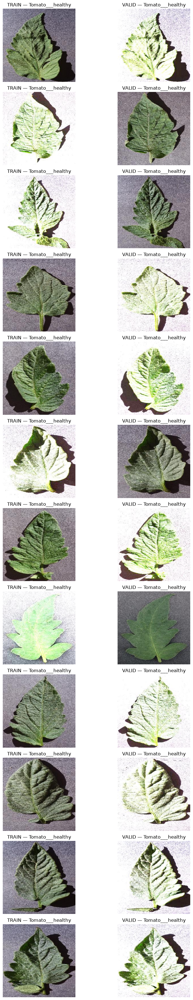

In [42]:

import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

batch = matching_pairs.head(12)

fig, axes = plt.subplots(len(batch), 2, figsize=(10, 3 * len(batch)))

for row_idx, (_, row) in enumerate(batch.iterrows()):
    for col_idx, path_col in enumerate(["train_path", "valid_path"]):
        p = Path(row[path_col])

        if not p.is_absolute():
            p = Path(r"C:\Intro_TO_AI_Project") / p

        with Image.open(p) as im:
            axes[row_idx, col_idx].imshow(im.convert("RGB"))

        axes[row_idx, col_idx].set_title(
            f"{'TRAIN' if col_idx == 0 else 'VALID'} — "
            f"{row['train_class'] if col_idx == 0 else row['valid_class']}"
        )
        axes[row_idx, col_idx].axis("off")

plt.tight_layout()
plt.show()


In [43]:

safe_candidates = matching_pairs[
    (matching_pairs["matching_base_identifier"]) &
    (matching_pairs["train_class"] == matching_pairs["valid_class"])
].copy()

SAFE_CANDIDATES_FILE = Path(
    r"C:\Intro_TO_AI_Project\near_duplicate_same_label_candidates.csv"
)

safe_candidates.to_csv(SAFE_CANDIDATES_FILE, index=False)

print("Matching identifiers and labels:", len(safe_candidates))
print("Saved to:", SAFE_CANDIDATES_FILE)
print("No images were moved or deleted.")


Matching identifiers and labels: 48
Saved to: C:\Intro_TO_AI_Project\near_duplicate_same_label_candidates.csv
No images were moved or deleted.


In [44]:

import shutil
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(r"C:\Intro_TO_AI_Project")
CLEANED_DIR = PROJECT_DIR / "Plant_Diseases_Cleaned"
REVIEW_DIR = PROJECT_DIR / "Near_Duplicate_Review"

# Use the candidates already identified in the previous step.
candidates_to_move = safe_candidates.copy()

REVIEW_DIR.mkdir(parents=True, exist_ok=True)
move_log = []

for _, row in candidates_to_move.iterrows():
    train_path = Path(row["train_path"])
    valid_path = Path(row["valid_path"])

    if not train_path.is_absolute():
        train_path = PROJECT_DIR / train_path
    if not valid_path.is_absolute():
        valid_path = PROJECT_DIR / valid_path

    # Safety checks: correct source folders and matching labels.
    if row["train_class"] != row["valid_class"]:
        continue
    if not train_path.exists() or not valid_path.exists():
        print("Skipped missing file:", valid_path)
        continue
    if "train" not in train_path.parts or "valid" not in valid_path.parts:
        print("Skipped unexpected path:", valid_path)
        continue

    # Preserve class folder structure inside the review folder.
    destination = REVIEW_DIR / row["valid_class"] / valid_path.name
    destination.parent.mkdir(parents=True, exist_ok=True)

    if destination.exists():
        print("Skipped existing review file:", destination)
        continue

    shutil.move(str(valid_path), str(destination))

    move_log.append({
        "train_path": str(train_path),
        "original_valid_path": str(valid_path),
        "review_path": str(destination),
        "class": row["valid_class"],
        "reason": "Matching base identifier and same class"
    })

log_file = PROJECT_DIR / "step40_duplicate_review_moves.csv"
pd.DataFrame(move_log).to_csv(log_file, index=False)

print("Validation images moved:", len(move_log))
print("Review folder:", REVIEW_DIR)
print("Move log:", log_file)
print("Original dataset unchanged.")


Validation images moved: 48
Review folder: C:\Intro_TO_AI_Project\Near_Duplicate_Review
Move log: C:\Intro_TO_AI_Project\step40_duplicate_review_moves.csv
Original dataset unchanged.


In [45]:

from pathlib import Path
from collections import Counter
import hashlib

CLEANED_DIR = Path(r"C:\Intro_TO_AI_Project\Plant_Diseases_Cleaned")

def inspect_split(split_name):
    split_dir = CLEANED_DIR / split_name
    records = []

    for class_dir in sorted(split_dir.iterdir()):
        if not class_dir.is_dir():
            continue

        for path in class_dir.iterdir():
            if path.is_file():
                digest = hashlib.sha256(path.read_bytes()).hexdigest()
                records.append({
                    "path": path,
                    "class": class_dir.name,
                    "hash": digest
                })

    return records

train_records = inspect_split("train")
valid_records = inspect_split("valid")

train_hashes = [r["hash"] for r in train_records]
valid_hashes = [r["hash"] for r in valid_records]

print("TRAIN images:", len(train_records))
print("TRAIN classes:", len(set(r["class"] for r in train_records)))
print("VALID images:", len(valid_records))
print("VALID classes:", len(set(r["class"] for r in valid_records)))
print("Total remaining images:", len(train_records) + len(valid_records))

print("\nExact duplicate pairs within TRAIN:",
      sum(n * (n - 1) // 2 for n in Counter(train_hashes).values()))
print("Exact duplicate pairs within VALID:",
      sum(n * (n - 1) // 2 for n in Counter(valid_hashes).values()))
print("Exact duplicate hashes across splits:",
      len(set(train_hashes) & set(valid_hashes)))

print("\nValidation images per class:")
print(Counter(r["class"] for r in valid_records))


TRAIN images: 30882
TRAIN classes: 19
VALID images: 7912
VALID classes: 19
Total remaining images: 38794

Exact duplicate pairs within TRAIN: 0
Exact duplicate pairs within VALID: 0
Exact duplicate hashes across splits: 0

Validation images per class:
Counter({'Tomato___Tomato_Yellow_Leaf_Curl_Virus': 490, 'Tomato___Early_blight': 480, 'Tomato___Leaf_Mold': 470, 'Tomato___healthy': 460, 'Tomato___Late_blight': 459, 'potato_early': 442, 'potato_late': 442, 'Tomato___Target_Spot': 442, 'Tomato___Septoria_leaf_spot': 436, 'Tomato___Spider_mites_Two-spotted_spider_mite': 435, 'Tomato___Bacterial_spot': 425, 'Tomato___Tomato_mosaic_virus': 419, 'Groundnut_nutrition_deficiency': 410, 'Groundnut_early_leaf_spot': 409, 'Groundnut_early_rust': 409, 'Groundnut_healthy_leaf': 409, 'Groundnut_rust': 409, 'Groundnut_late_leaf_spot': 405, 'potato_healthy': 61})


In [46]:
#Check the training and validation counts for every class
import pandas as pd
from pathlib import Path

CLEANED_DIR = Path(r"C:\Intro_TO_AI_Project\Plant_Diseases_Cleaned")

rows = []

for class_dir in sorted((CLEANED_DIR / "train").iterdir()):
    if not class_dir.is_dir():
        continue

    class_name = class_dir.name
    train_count = sum(1 for p in class_dir.iterdir() if p.is_file())

    valid_dir = CLEANED_DIR / "valid" / class_name
    valid_count = (
        sum(1 for p in valid_dir.iterdir() if p.is_file())
        if valid_dir.exists() else 0
    )

    rows.append({
        "class": class_name,
        "train_images": train_count,
        "validation_images": valid_count,
        "total_images": train_count + valid_count
    })

class_counts = pd.DataFrame(rows)

display(class_counts)
print("\nTotal training:", class_counts["train_images"].sum())
print("Total validation:", class_counts["validation_images"].sum())
print("Total:", class_counts["total_images"].sum())


,class,train_images,validation_images,total_images
0,Groundnut_early_leaf_spot,1322,409,1731
1,Groundnut_early_rust,1064,409,1473
2,Groundnut_healthy_leaf,1453,409,1862
3,Groundnut_late_leaf_spot,1491,405,1896
4,Groundnut_nutrition_deficiency,1247,410,1657
5,Groundnut_rust,1315,409,1724
6,potato_early,1846,442,2288
7,potato_healthy,982,61,1043
8,potato_late,1830,442,2272
9,Tomato___Bacterial_spot,1702,425,2127



Total training: 30882
Total validation: 7912
Total: 38794


In [48]:
# Split the cleaned dataset into train, validation, and test sets
from pathlib import Path
from sklearn.model_selection import train_test_split
import pandas as pd
import shutil

CLEANED_DIR = Path(r"C:\Intro_TO_AI_Project\Plant_Diseases_Cleaned")
OUTPUT_DIR = Path(r"C:\Intro_TO_AI_Project\Plant_Diseases_Final_Split")

if OUTPUT_DIR.exists():
    raise FileExistsError(
        f"{OUTPUT_DIR} already exists. Choose a new folder name "
        "or inspect the existing folder before continuing."
    )

# Build a manifest from the cleaned train and validation folders.
records = []

for split in ["train", "valid"]:
    split_dir = CLEANED_DIR / split

    for class_dir in sorted(split_dir.iterdir()):
        if not class_dir.is_dir():
            continue

        for image_path in class_dir.iterdir():
            if image_path.is_file():
                records.append({
                    "path": image_path,
                    "class": class_dir.name
                })

df = pd.DataFrame(records)

# First reserve 15% for the test set.
train_valid_df, test_df = train_test_split(
    df,
    test_size=0.15,
    stratify=df["class"],
    random_state=42
)

# Of the remaining 85%, reserve 15/85 for validation.
train_df, valid_df = train_test_split(
    train_valid_df,
    test_size=0.15 / 0.85,
    stratify=train_valid_df["class"],
    random_state=42
)

splits = {
    "train": train_df,
    "valid": valid_df,
    "test": test_df
}

# Copy images; do not move the source files.
for split_name, split_df in splits.items():
    for _, row in split_df.iterrows():
        source = Path(row["path"])
        destination = (
            OUTPUT_DIR / split_name / row["class"] / source.name
        )
        destination.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(source, destination)

    print(f"{split_name}: {len(split_df)} images")

print("\nTotal:", sum(len(part) for part in splits.values()))
print("Output folder:", OUTPUT_DIR)
print("Source cleaned dataset unchanged.")


train: 27155 images
valid: 5819 images
test: 5820 images

Total: 38794
Output folder: C:\Intro_TO_AI_Project\Plant_Diseases_Final_Split
Source cleaned dataset unchanged.


In [49]:
# Verify the final split counts and class distributions

from pathlib import Path
import pandas as pd

FINAL_DIR = Path(
    r"C:\Intro_TO_AI_Project\Plant_Diseases_Final_Split"
)

rows = []

for class_dir in sorted((FINAL_DIR / "train").iterdir()):
    if not class_dir.is_dir():
        continue

    class_name = class_dir.name
    counts = {}

    for split in ["train", "valid", "test"]:
        folder = FINAL_DIR / split / class_name
        counts[split] = (
            sum(1 for p in folder.iterdir() if p.is_file())
            if folder.exists() else 0
        )

    rows.append({
        "class": class_name,
        "train": counts["train"],
        "validation": counts["valid"],
        "test": counts["test"],
        "total": sum(counts.values())
    })

split_counts = pd.DataFrame(rows)
display(split_counts)

print("\nNumber of classes:", len(split_counts))
print("Training total:", split_counts["train"].sum())
print("Validation total:", split_counts["validation"].sum())
print("Test total:", split_counts["test"].sum())
print("Overall total:", split_counts[["train", "validation", "test"]].sum().sum())


,class,train,validation,test,total
0,Groundnut_early_leaf_spot,1210,260,260,1730
1,Groundnut_early_rust,1029,221,221,1471
2,Groundnut_healthy_leaf,1304,279,279,1862
3,Groundnut_late_leaf_spot,1327,285,284,1896
4,Groundnut_nutrition_deficiency,1160,247,249,1656
5,Groundnut_rust,1206,259,259,1724
6,potato_early,1602,343,343,2288
7,potato_healthy,730,156,157,1043
8,potato_late,1590,341,341,2272
9,Tomato___Bacterial_spot,1489,319,319,2127



Number of classes: 19
Training total: 27152
Validation total: 5818
Test total: 5820
Overall total: 38790


In [ ]:
#Find missing or extra images
from pathlib import Path
from collections import Counter

SOURCE = Path(r"C:\Intro_TO_AI_Project\Plant_Diseases_Cleaned")
FINAL = Path(r"C:\Intro_TO_AI_Project\Plant_Diseases_Final_Split")

def count_by_class(folder):
    result = Counter()
    for class_dir in folder.iterdir():
        if class_dir.is_dir():
            result[class_dir.name] = sum(
                1 for p in class_dir.iterdir() if p.is_file()
            )
    return result

source_counts = Counter()
for split in ["train", "valid"]:
    source_counts.update(count_by_class(SOURCE / split))

final_counts = Counter()
for split in ["train", "valid", "test"]:
    final_counts.update(count_by_class(FINAL / split))

print("Source total:", sum(source_counts.values()))
print("Final total:", sum(final_counts.values()))

print("\nClass count differences (source - final):")
for class_name in sorted(set(source_counts) | set(final_counts)):
    difference = source_counts[class_name] - final_counts[class_name]
    if difference != 0:
        print(class_name, "difference:", difference)


Source total: 38794
Final total: 38790

Class count differences (source - final):
Groundnut_early_leaf_spot difference: 1
Groundnut_early_rust difference: 2
Groundnut_nutrition_deficiency difference: 1


In [51]:

from pathlib import Path
from collections import defaultdict

SOURCE = Path(r"C:\Intro_TO_AI_Project\Plant_Diseases_Cleaned")

files_by_class_name = defaultdict(list)

for split in ["train", "valid"]:
    split_dir = SOURCE / split

    for class_dir in split_dir.iterdir():
        if not class_dir.is_dir():
            continue

        for image_path in class_dir.iterdir():
            if image_path.is_file():
                key = (class_dir.name, image_path.name.lower())
                files_by_class_name[key].append(image_path)

collisions = {
    key: paths
    for key, paths in files_by_class_name.items()
    if len(paths) > 1
}

print("Filename collision groups:", len(collisions))

for (class_name, filename), paths in collisions.items():
    print(f"\nClass: {class_name}")
    print(f"Filename: {filename}")
    for path in paths:
        print(" ", path)


Filename collision groups: 4

Class: Groundnut_early_leaf_spot
Filename: dr_3_8007.jpg
  C:\Intro_TO_AI_Project\Plant_Diseases_Cleaned\train\Groundnut_early_leaf_spot\dr_3_8007.jpg
  C:\Intro_TO_AI_Project\Plant_Diseases_Cleaned\valid\Groundnut_early_leaf_spot\dr_3_8007.jpg

Class: Groundnut_early_rust
Filename: dr_1_2919.jpg
  C:\Intro_TO_AI_Project\Plant_Diseases_Cleaned\train\Groundnut_early_rust\dr_1_2919.jpg
  C:\Intro_TO_AI_Project\Plant_Diseases_Cleaned\valid\Groundnut_early_rust\dr_1_2919.jpg

Class: Groundnut_early_rust
Filename: dr_1_9542.jpg
  C:\Intro_TO_AI_Project\Plant_Diseases_Cleaned\train\Groundnut_early_rust\dr_1_9542.jpg
  C:\Intro_TO_AI_Project\Plant_Diseases_Cleaned\valid\Groundnut_early_rust\dr_1_9542.jpg

Class: Groundnut_nutrition_deficiency
Filename: dr_1_8956.jpg
  C:\Intro_TO_AI_Project\Plant_Diseases_Cleaned\train\Groundnut_nutrition_deficiency\dr_1_8956.jpg
  C:\Intro_TO_AI_Project\Plant_Diseases_Cleaned\valid\Groundnut_nutrition_deficiency\dr_1_8956.jpg


In [52]:

from pathlib import Path
from collections import Counter
from sklearn.model_selection import train_test_split
import shutil
import uuid

SOURCE = Path(r"C:\Intro_TO_AI_Project\Plant_Diseases_Cleaned")
OUTPUT = Path(r"C:\Intro_TO_AI_Project\Plant_Diseases_Final_Split_v2")

# Prevent accidentally overwriting an existing folder
if OUTPUT.exists():
    raise FileExistsError(
        f"{OUTPUT} already exists. Choose a new output folder name."
    )

# Collect every image from the cleaned train and valid folders
records = []

for source_split in ["train", "valid"]:
    for class_dir in sorted((SOURCE / source_split).iterdir()):
        if not class_dir.is_dir():
            continue

        for image_path in sorted(class_dir.iterdir()):
            if image_path.is_file():
                records.append({
                    "path": image_path,
                    "label": class_dir.name
                })

print("Images collected:", len(records))

# Stratified 70% train, 15% validation, 15% test
labels = [record["label"] for record in records]
indices = list(range(len(records)))

train_valid_idx, test_idx = train_test_split(
    indices,
    test_size=0.15,
    random_state=42,
    stratify=labels
)

train_valid_labels = [labels[i] for i in train_valid_idx]

train_idx, valid_idx = train_test_split(
    train_valid_idx,
    test_size=0.15 / 0.85,
    random_state=42,
    stratify=train_valid_labels
)

splits = {
    "train": train_idx,
    "valid": valid_idx,
    "test": test_idx
}

# Copy each image with a unique filename to prevent overwriting
for split_name, split_indices in splits.items():
    for index in split_indices:
        record = records[index]
        class_name = record["label"]
        source_path = record["path"]

        destination_dir = OUTPUT / split_name / class_name
        destination_dir.mkdir(parents=True, exist_ok=True)

        unique_name = f"{index}_{uuid.uuid4().hex}{source_path.suffix.lower()}"
        shutil.copy2(source_path, destination_dir / unique_name)

print("\nCorrected split created:", OUTPUT)
for split_name in ["train", "valid", "test"]:
    count = sum(
        1 for p in (OUTPUT / split_name).rglob("*")
        if p.is_file()
    )
    print(f"{split_name}: {count}")
print("Expected total:", len(records))


Images collected: 38794

Corrected split created: C:\Intro_TO_AI_Project\Plant_Diseases_Final_Split_v2
train: 27155
valid: 5819
test: 5820
Expected total: 38794


In [53]:

from pathlib import Path

OUTPUT = Path(r"C:\Intro_TO_AI_Project\Plant_Diseases_Final_Split_v2")

split_counts = {}

for split_name in ["train", "valid", "test"]:
    split_dir = OUTPUT / split_name
    split_counts[split_name] = sum(
        1 for p in split_dir.rglob("*") if p.is_file()
    )

print("Train:", split_counts["train"])
print("Validation:", split_counts["valid"])
print("Test:", split_counts["test"])
print("Total:", sum(split_counts.values()))
print("Expected total: 38794")
print("All images accounted for:",
      sum(split_counts.values()) == 38794)

for split_name in ["train", "valid", "test"]:
    classes = [
        p for p in (OUTPUT / split_name).iterdir()
        if p.is_dir()
    ]
    print(f"{split_name} classes:", len(classes))


Train: 27155
Validation: 5819
Test: 5820
Total: 38794
Expected total: 38794
All images accounted for: True
train classes: 19
valid classes: 19
test classes: 19


In [54]:

from pathlib import Path
from collections import defaultdict
import hashlib

FINAL_DIR = Path(
    r"C:\Intro_TO_AI_Project\Plant_Diseases_Final_Split_v2"
)

SPLITS = ["train", "valid", "test"]
hash_locations = defaultdict(list)
image_count = 0

for split in SPLITS:
    split_dir = FINAL_DIR / split

    for image_path in split_dir.rglob("*"):
        if not image_path.is_file():
            continue

        digest = hashlib.sha256(image_path.read_bytes()).hexdigest()
        hash_locations[digest].append((split, image_path))
        image_count += 1

duplicate_groups = {
    digest: locations
    for digest, locations in hash_locations.items()
    if len(locations) > 1
}

cross_split_groups = {
    digest: locations
    for digest, locations in duplicate_groups.items()
    if len(set(split for split, _ in locations)) > 1
}

print("Images checked:", image_count)
print("Unique image contents:", len(hash_locations))
print("Exact duplicate groups overall:", len(duplicate_groups))
print("Exact duplicate groups crossing splits:", len(cross_split_groups))

for digest, locations in list(cross_split_groups.items())[:10]:
    print("\nDuplicate group:")
    for split, path in locations:
        print(f"  {split}: {path.name}")

if not cross_split_groups:
    print("\nPASS: No exact duplicate images cross the splits.")
else:
    print("\nREVIEW REQUIRED: Exact duplicates cross the splits.")


Images checked: 38794
Unique image contents: 38794
Exact duplicate groups overall: 0
Exact duplicate groups crossing splits: 0

PASS: No exact duplicate images cross the splits.


In [55]:

from pathlib import Path
from itertools import combinations
from PIL import Image
import imagehash
import pandas as pd

FINAL_DIR = Path(
    r"C:\Intro_TO_AI_Project\Plant_Diseases_Final_Split_v2"
)

SPLITS = ["train", "valid", "test"]
HASH_DISTANCE_THRESHOLD = 4

# Calculate one perceptual hash for each image.
image_records = []

for split in SPLITS:
    for image_path in (FINAL_DIR / split).rglob("*"):
        if not image_path.is_file():
            continue

        try:
            with Image.open(image_path) as img:
                phash = imagehash.phash(img.convert("RGB"))

            image_records.append({
                "split": split,
                "class": image_path.parent.name,
                "filename": image_path.name,
                "path": str(image_path),
                "phash": phash
            })
        except Exception as error:
            print("Could not read:", image_path, "|", error)

print("Images hashed:", len(image_records))

# Compare only pairs belonging to different splits.
results = []

for a, b in combinations(image_records, 2):
    if a["split"] == b["split"]:
        continue

    distance = a["phash"] - b["phash"]

    if distance <= HASH_DISTANCE_THRESHOLD:
        results.append({
            "distance": distance,
            "split_a": a["split"],
            "class_a": a["class"],
            "file_a": a["filename"],
            "path_a": a["path"],
            "split_b": b["split"],
            "class_b": b["class"],
            "file_b": b["filename"],
            "path_b": b["path"]
        })

results_df = pd.DataFrame(results)

if not results_df.empty:
    results_df = results_df.sort_values(
        ["distance", "split_a", "split_b"]
    )
    report_path = FINAL_DIR.parent / "final_split_near_duplicate_report.csv"
    results_df.to_csv(report_path, index=False)

    print("\nPotential near-duplicate pairs:", len(results_df))
    print("\nCounts by perceptual-hash distance:")
    print(results_df["distance"].value_counts().sort_index())
    print("\nFirst 20 candidate pairs:")
    display(results_df.head(20))
    print("\nReport saved to:", report_path)
else:
    print("\nNo cross-split pairs found within the threshold.")


Images hashed: 38794

Potential near-duplicate pairs: 2192

Counts by perceptual-hash distance:
distance
0    1568
2     272
4     352
Name: count, dtype: int64

First 20 candidate pairs:


,distance,split_a,class_a,file_a,path_a,split_b,class_b,file_b,path_b
76,0,train,Groundnut_early_rust,2003_7c4ae76213c84de19080b210db7d4baa.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Sp...,test,Groundnut_early_rust,1994_acf5b3cf79054737a9dc7a654f124202.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Sp...
134,0,train,Groundnut_healthy_leaf,31887_7452a5740fc1415d82d1e26f0a3e782c.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Sp...,test,Groundnut_healthy_leaf,31895_d2f7d5321334412282eaaa5bd7636e81.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Sp...
170,0,train,Groundnut_late_leaf_spot,32284_9e4b83ee0498497e918eceed348645d0.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Sp...,test,Groundnut_late_leaf_spot,32343_d05db910bfec42ccbd77806bac1bd28d.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Sp...
283,0,train,Groundnut_rust,6888_e78f696bbdad45498c5c7a9de38a1b02.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Sp...,test,Groundnut_rust,6900_e9e743f0af5b46f19bf2b3b03b947e9b.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Sp...
284,0,train,Groundnut_rust,6893_cf8a9f8e76d14e38bcdd7d0dbd273baf.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Sp...,test,Groundnut_rust,6900_e9e743f0af5b46f19bf2b3b03b947e9b.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Sp...
312,0,train,potato_early,7897_309383c9d5dc425a8143870369db257d.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Sp...,test,potato_early,7899_111972fc180a485eb497cd3a981b393d.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Sp...
315,0,train,potato_early,7898_e5abfe79ccc44c658a15e339b21af902.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Sp...,test,potato_early,7899_111972fc180a485eb497cd3a981b393d.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Sp...
326,0,train,potato_early,7951_9d8dd2cf3f134b97b6d53374bc591183.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Sp...,test,potato_early,7950_9449d23050e54dd7af2fab72780325ce.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Sp...
327,0,train,potato_early,7952_70be90dadf684f5d98251338efa1dd56.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Sp...,test,potato_early,7950_9449d23050e54dd7af2fab72780325ce.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Sp...
328,0,train,potato_early,7953_a34c5f76b4e244eca347bd6d7e108ddd.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Sp...,test,potato_early,7950_9449d23050e54dd7af2fab72780325ce.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Sp...



Report saved to: C:\Intro_TO_AI_Project\final_split_near_duplicate_report.csv


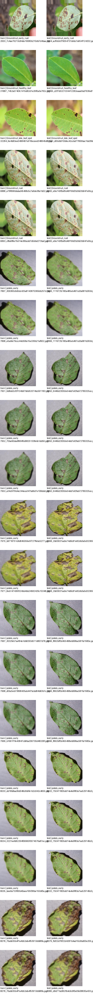

In [56]:

from PIL import Image, ImageOps, ImageDraw
from IPython.display import display

# Inspect the strongest candidates first.
# This uses results_df from your previous cell.
review_df = results_df[results_df["distance"] == 0].head(20)

if review_df.empty:
    print("No distance-0 candidate pairs to inspect.")
else:
    thumbnail_size = (220, 170)
    label_height = 65
    canvas = Image.new(
        "RGB",
        (thumbnail_size[0] * 2, (thumbnail_size[1] + label_height) * len(review_df)),
        "white"
    )
    draw = ImageDraw.Draw(canvas)

    for row_number, (_, row) in enumerate(review_df.iterrows()):
        y = row_number * (thumbnail_size[1] + label_height)

        for column, (path_col, split_col, class_col) in enumerate([
            ("path_a", "split_a", "class_a"),
            ("path_b", "split_b", "class_b")
        ]):
            path = row[path_col]

            with Image.open(path) as img:
                thumb = ImageOps.contain(
                    img.convert("RGB"), thumbnail_size
                )

            x = column * thumbnail_size[0]
            canvas.paste(thumb, (x, y))

            text = (
                f"{row[split_col]} | {row[class_col]}\n"
                f"{row['file_a'] if column == 0 else row['file_b']}"
            )
            draw.text(
                (x + 2, y + thumbnail_size[1] + 3),
                text,
                fill="black"
            )

    display(canvas)


In [57]:

from pathlib import Path
from collections import defaultdict
import hashlib
import pandas as pd

FINAL_DIR = Path(
    r"C:\Intro_TO_AI_Project\Plant_Diseases_Final_Split_v2"
)

hash_groups = defaultdict(list)

for split in ["train", "valid", "test"]:
    for path in (FINAL_DIR / split).rglob("*"):
        if path.is_file():
            digest = hashlib.sha256(path.read_bytes()).hexdigest()
            hash_groups[digest].append({
                "split": split,
                "class": path.parent.name,
                "path": str(path)
            })

rows = []

for digest, files in hash_groups.items():
    if len(files) > 1 and len({f["split"] for f in files}) > 1:
        for file in files:
            rows.append({
                "sha256": digest,
                **file
            })

report = pd.DataFrame(rows)
report_path = FINAL_DIR.parent / "exact_duplicates_across_splits.csv"
report.to_csv(report_path, index=False)

print("Exact duplicate files involved in cross-split groups:", len(report))
print("Exact duplicate groups:", report["sha256"].nunique() if not report.empty else 0)
print("Report saved to:", report_path)

if not report.empty:
    display(report)
else:
    print("No exact duplicate content crosses the splits.")


Exact duplicate files involved in cross-split groups: 0
Exact duplicate groups: 0
Report saved to: C:\Intro_TO_AI_Project\exact_duplicates_across_splits.csv
No exact duplicate content crosses the splits.


In [58]:

from pathlib import Path
import pandas as pd

REPORT = Path(
    r"C:\Intro_TO_AI_Project\Plant_Diseases_Final_Split_v2"
).parent / "final_split_near_duplicate_report.csv"

df = pd.read_csv(REPORT)

print("Candidate pairs:", len(df))
print("\nPairs by distance:")
print(df["distance"].value_counts().sort_index())

print("\nPairs by split combination:")
df["split_pair"] = df.apply(
    lambda r: " - ".join(sorted([r["split_a"], r["split_b"]])),
    axis=1
)
print(df["split_pair"].value_counts())

print("\nPairs with different class labels:")
different_labels = df[df["class_a"] != df["class_b"]]
print("Count:", len(different_labels))
display(
    different_labels[
        ["distance", "split_a", "class_a", "file_a",
         "split_b", "class_b", "file_b"]
    ].head(20)
)


Candidate pairs: 2192

Pairs by distance:
distance
0    1568
2     272
4     352
Name: count, dtype: int64

Pairs by split combination:
split_pair
train - valid    1013
test - train      982
test - valid      197
Name: count, dtype: int64

Pairs with different class labels:
Count: 3


,distance,split_a,class_a,file_a,split_b,class_b,file_b
1974,4,train,Tomato___Leaf_Mold,21102_7fbcbb0792d8402285c54c1c6d234930.jpg,test,Tomato___Tomato_mosaic_virus,28464_7d3850c302b144c2bf9647f84f2b12bc.jpg
2133,4,train,Tomato___healthy,35209_10216b3e651848b2a7669ae266e44e63.jpg,valid,Tomato___Tomato_mosaic_virus,28295_3f67b1f0a3a2425186b7b0c843c2e986.jpg
2136,4,train,Tomato___Late_blight,18374_46ee7c3471f3437c9799c8df1e9a8033.jpg,valid,potato_late,11098_3672a48eedb24bbea8c8e4ddb1a48dba.jpg


Distance: 4
Image A: Tomato___Leaf_Mold | 21102_7fbcbb0792d8402285c54c1c6d234930.jpg
Image B: Tomato___Tomato_mosaic_virus | 28464_7d3850c302b144c2bf9647f84f2b12bc.jpg


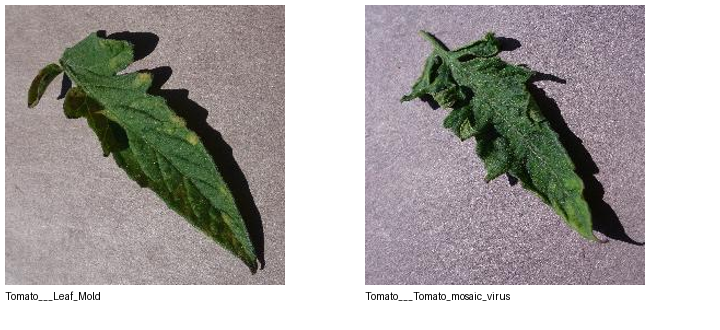

Distance: 4
Image A: Tomato___healthy | 35209_10216b3e651848b2a7669ae266e44e63.jpg
Image B: Tomato___Tomato_mosaic_virus | 28295_3f67b1f0a3a2425186b7b0c843c2e986.jpg


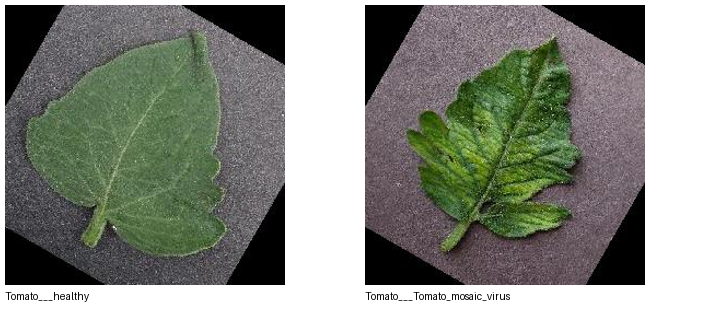

Distance: 4
Image A: Tomato___Late_blight | 18374_46ee7c3471f3437c9799c8df1e9a8033.jpg
Image B: potato_late | 11098_3672a48eedb24bbea8c8e4ddb1a48dba.jpg


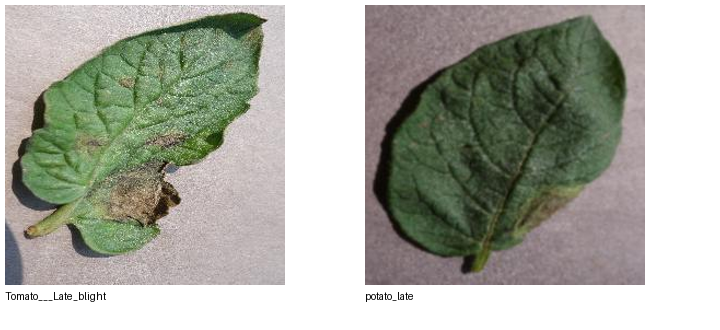

In [59]:

from PIL import Image, ImageOps, ImageDraw
from IPython.display import display
import pandas as pd

REPORT = Path(
    r"C:\Intro_TO_AI_Project\final_split_near_duplicate_report.csv"
)
df = pd.read_csv(REPORT)

different_labels = df[df["class_a"] != df["class_b"]]

for _, row in different_labels.iterrows():
    print(f"Distance: {row['distance']}")
    print(f"Image A: {row['class_a']} | {row['file_a']}")
    print(f"Image B: {row['class_b']} | {row['file_b']}")

    images = []
    for path_col in ["path_a", "path_b"]:
        with Image.open(row[path_col]) as img:
            images.append(
                ImageOps.contain(img.convert("RGB"), (350, 280)).copy()
            )

    canvas = Image.new("RGB", (720, 330), "white")
    canvas.paste(images[0], (5, 5))
    canvas.paste(images[1], (365, 5))

    draw = ImageDraw.Draw(canvas)
    draw.text((5, 290), str(row["class_a"]), fill="black")
    draw.text((365, 290), str(row["class_b"]), fill="black")
    display(canvas)


In [60]:

from pathlib import Path
import pandas as pd
from collections import defaultdict

REPORT = Path(
    r"C:\Intro_TO_AI_Project\final_split_near_duplicate_report.csv"
)
OUTPUT = Path(
    r"C:\Intro_TO_AI_Project\near_duplicate_groups_for_review.csv"
)

df = pd.read_csv(REPORT)
candidates = df[df["distance"] <= 2].copy()

# Build a graph: each image is a node, each candidate pair is an edge.
parent = {}

def find(x):
    parent.setdefault(x, x)
    if parent[x] != x:
        parent[x] = find(parent[x])
    return parent[x]

def union(a, b):
    parent[find(a)] = find(b)

for _, row in candidates.iterrows():
    union(row["path_a"], row["path_b"])

groups = defaultdict(list)

for path in list(parent):
    groups[find(path)].append(path)

# Keep groups containing at least two images.
groups = {
    root: sorted(paths)
    for root, paths in groups.items()
    if len(paths) > 1
}

path_info = {}
for _, row in candidates.iterrows():
    path_info[row["path_a"]] = {
        "split": row["split_a"],
        "class": row["class_a"]
    }
    path_info[row["path_b"]] = {
        "split": row["split_b"],
        "class": row["class_b"]
    }

rows = []

for group_number, paths in enumerate(groups.values(), start=1):
    classes = sorted({path_info[p]["class"] for p in paths})
    splits = sorted({path_info[p]["split"] for p in paths})

    for path in paths:
        rows.append({
            "group_id": group_number,
            "group_size": len(paths),
            "class_labels": " | ".join(classes),
            "splits_present": " | ".join(splits),
            "cross_split": len(splits) > 1,
            "path": path
        })

groups_df = pd.DataFrame(rows)
groups_df.to_csv(OUTPUT, index=False)

print("Candidate pairs examined:", len(candidates))
print("Connected groups found:", len(groups))
print("Images in these groups:", len(groups_df))
print("Groups spanning multiple splits:",
      groups_df.loc[groups_df["cross_split"], "group_id"].nunique())
print("Review report saved to:", OUTPUT)

if not groups_df.empty:
    print("\nLargest groups:")
    display(
        groups_df.drop_duplicates("group_id")
        .sort_values("group_size", ascending=False)
        .head(20)
    )


Candidate pairs examined: 1840
Connected groups found: 413
Images in these groups: 1745
Groups spanning multiple splits: 413
Review report saved to: C:\Intro_TO_AI_Project\near_duplicate_groups_for_review.csv

Largest groups:


,group_id,group_size,class_labels,splits_present,cross_split,path
657,134,6,potato_late,test | train,True,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Sp...
496,102,6,potato_healthy,test | train | valid,True,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Sp...
465,96,6,potato_healthy,test | train,True,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Sp...
444,92,6,potato_healthy,test | train,True,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Sp...
748,152,6,potato_late,test | train | valid,True,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Sp...
1055,216,6,potato_early,train | valid,True,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Sp...
1091,223,6,potato_early,train | valid,True,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Sp...
119,27,5,potato_early,test | train | valid,True,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Sp...
114,26,5,potato_early,test | train,True,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Sp...
109,25,5,potato_early,test | train,True,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Sp...



Group 134 | 6 images | Classes: potato_late


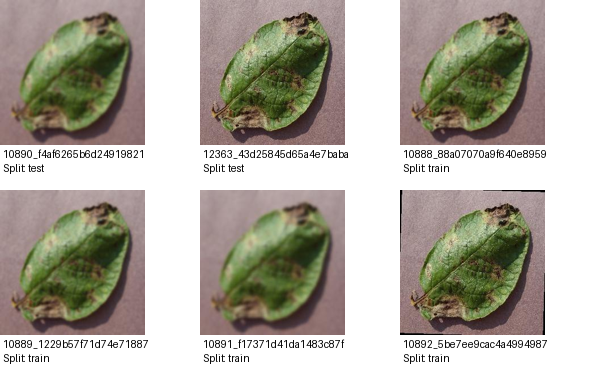


Group 102 | 6 images | Classes: potato_healthy


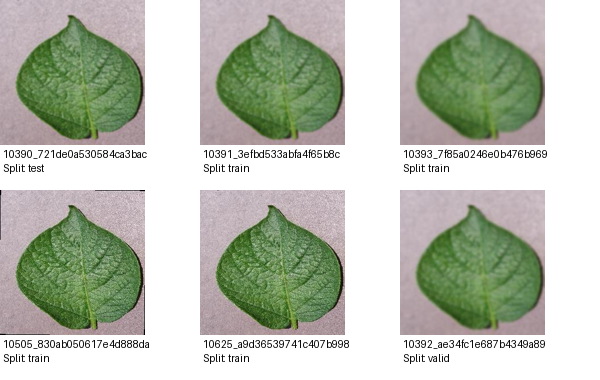


Group 96 | 6 images | Classes: potato_healthy


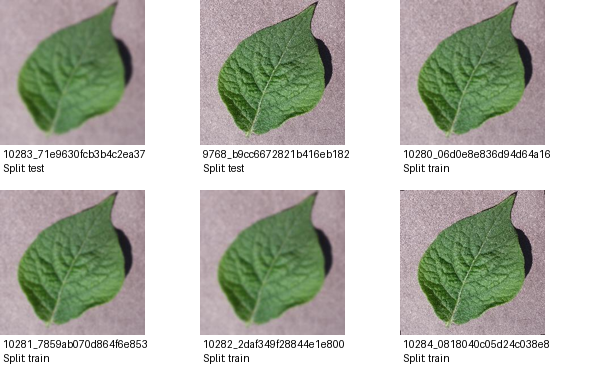


Group 92 | 6 images | Classes: potato_healthy


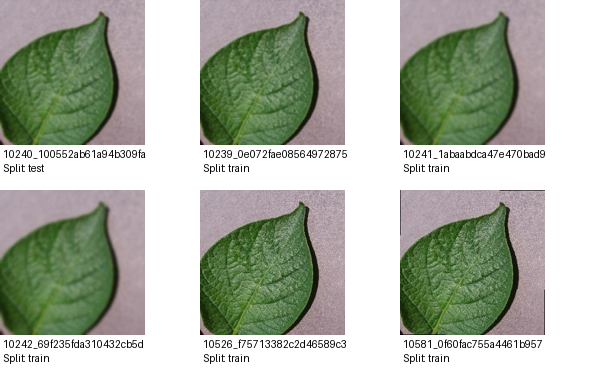


Group 152 | 6 images | Classes: potato_late


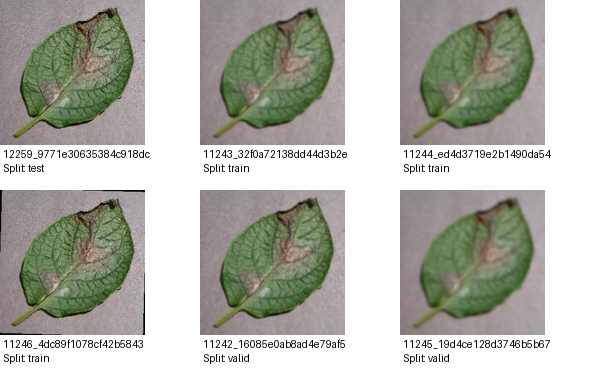

In [61]:

from pathlib import Path
import pandas as pd
from PIL import Image, ImageOps, ImageDraw
from IPython.display import display

GROUP_REPORT = Path(
    r"C:\Intro_TO_AI_Project\near_duplicate_groups_for_review.csv"
)

groups_df = pd.read_csv(GROUP_REPORT)

# Inspect the largest groups first
largest_groups = (
    groups_df.groupby("group_id")["group_size"]
    .first()
    .sort_values(ascending=False)
    .head(5)
    .index
)

for group_id in largest_groups:
    group = groups_df[groups_df["group_id"] == group_id]

    print(
        f"\nGroup {group_id} | "
        f"{len(group)} images | "
        f"Classes: {', '.join(group['class_labels'].unique())}"
    )

    tile_w, tile_h = 200, 190
    columns = 3
    rows = (len(group) + columns - 1) // columns

    canvas = Image.new(
        "RGB", (columns * tile_w, rows * tile_h), "white"
    )
    draw = ImageDraw.Draw(canvas)

    for i, (_, item) in enumerate(group.iterrows()):
        with Image.open(item["path"]) as img:
            thumb = ImageOps.contain(img.convert("RGB"), (190, 145))

        x = (i % columns) * tile_w
        y = (i // columns) * tile_h
        canvas.paste(thumb, (x, y))
        draw.text(
            (x + 3, y + 148),
            f"{item['path'].split(chr(92))[-1][:25]}\n"
            f"Split: {item['path'].split(chr(92))[-3]}",
            fill="black"
        )

    display(canvas)


In [62]:

from pathlib import Path
from collections import defaultdict, Counter
from sklearn.model_selection import GroupShuffleSplit
import pandas as pd
import shutil
import uuid

SOURCE = Path(
    r"C:\Intro_TO_AI_Project\Plant_Diseases_Final_Split_v2"
)
GROUP_REPORT = Path(
    r"C:\Intro_TO_AI_Project\near_duplicate_groups_for_review.csv"
)
OUTPUT = Path(
    r"C:\Intro_TO_AI_Project\Plant_Diseases_Group_Split"
)

# Safety checks: never overwrite an existing output.
if OUTPUT.exists():
    raise FileExistsError(
        f"{OUTPUT} already exists. Choose a new folder name."
    )

if not SOURCE.exists() or not GROUP_REPORT.exists():
    raise FileNotFoundError(
        "The source split or reviewed group report was not found."
    )

# 1. Read the reviewed groups.
group_df = pd.read_csv(GROUP_REPORT)

path_to_group = {}
for _, row in group_df.iterrows():
    path_to_group[str(Path(row["path"]).resolve()).lower()] = int(
        row["group_id"]
    )

# 2. Collect all images from the current split.
records = []

for split in ["train", "valid", "test"]:
    for class_dir in sorted((SOURCE / split).iterdir()):
        if not class_dir.is_dir():
            continue

        for image_path in sorted(class_dir.iterdir()):
            if image_path.is_file():
                key = str(image_path.resolve()).lower()
                records.append({
                    "path": image_path,
                    "label": class_dir.name,
                    "reviewed_group": path_to_group.get(key)
                })

print("Images collected:", len(records))

# 3. Give every ungrouped image its own group.
# Reviewed group members stay together.
for i, record in enumerate(records):
    if record["reviewed_group"] is None:
        record["group_key"] = f"single_{i}"
    else:
        record["group_key"] = f"group_{record['reviewed_group']}"

# 4. Stop if any group contains conflicting labels.
labels_by_group = defaultdict(set)
for record in records:
    labels_by_group[record["group_key"]].add(record["label"])

conflicts = {
    group: labels
    for group, labels in labels_by_group.items()
    if len(labels) > 1
}

if conflicts:
    print("Conflicting-label groups:", len(conflicts))
    print(list(conflicts.items())[:10])
    raise ValueError(
        "Resolve conflicting labels before creating the new split."
    )

# 5. Split groups rather than individual images.
# This targets 15% test, then 15% validation from the remainder.
X = list(range(len(records)))
y = [r["label"] for r in records]
groups = [r["group_key"] for r in records]

test_splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.15, random_state=42
)
train_valid_idx, test_idx = next(
    test_splitter.split(X, y, groups)
)

remaining_groups = [groups[i] for i in train_valid_idx]
remaining_labels = [y[i] for i in train_valid_idx]
remaining_X = list(train_valid_idx)

valid_splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.15 / 0.85, random_state=43
)
train_rel, valid_rel = next(
    valid_splitter.split(
        remaining_X, remaining_labels, remaining_groups
    )
)

train_idx = [remaining_X[i] for i in train_rel]
valid_idx = [remaining_X[i] for i in valid_rel]

split_indices = {
    "train": train_idx,
    "valid": valid_idx,
    "test": list(test_idx)
}

# 6. Copy with unique filenames so files cannot overwrite each other.
for split_name, indices in split_indices.items():
    for index in indices:
        record = records[index]
        destination = OUTPUT / split_name / record["label"]
        destination.mkdir(parents=True, exist_ok=True)

        unique_name = f"{uuid.uuid4().hex}{record['path'].suffix.lower()}"
        shutil.copy2(record["path"], destination / unique_name)

# 7. Verify no reviewed group was divided across splits.
group_splits = defaultdict(set)
for split_name, indices in split_indices.items():
    for index in indices:
        group_splits[records[index]["group_key"]].add(split_name)

leaked_groups = {
    group: splits
    for group, splits in group_splits.items()
    if len(splits) > 1
}

print("\nNew split created:", OUTPUT)
print("Train images:", len(train_idx))
print("Validation images:", len(valid_idx))
print("Test images:", len(test_idx))
print("Total images:", len(train_idx) + len(valid_idx) + len(test_idx))
print("Groups spanning multiple splits:", len(leaked_groups))
print("Classes in source:", len(set(y)))


Images collected: 38794

New split created: C:\Intro_TO_AI_Project\Plant_Diseases_Group_Split
Train images: 27165
Validation images: 5832
Test images: 5797
Total images: 38794
Groups spanning multiple splits: 0
Classes in source: 19


In [63]:

from pathlib import Path
import pandas as pd

REPORT = Path(
    r"C:\Intro_TO_AI_Project\final_split_near_duplicate_report.csv"
)

NEW_SPLIT = Path(
    r"C:\Intro_TO_AI_Project\Plant_Diseases_Group_Split"
)

df = pd.read_csv(REPORT)
df = df[df["distance"] == 4].copy()

def get_current_split(path):
    path = Path(path)
    try:
        relative = path.relative_to(NEW_SPLIT)
        return relative.parts[0]
    except ValueError:
        return "NOT_IN_NEW_SPLIT"

df["current_split_a"] = df["path_a"].apply(get_current_split)
df["current_split_b"] = df["path_b"].apply(get_current_split)

# Keep pairs whose two images exist in the new split
# but are assigned to different splits.
cross_split = df[
    (df["current_split_a"] != "NOT_IN_NEW_SPLIT") &
    (df["current_split_b"] != "NOT_IN_NEW_SPLIT") &
    (df["current_split_a"] != df["current_split_b"])
].copy()

print("Distance-4 candidate pairs in original report:", len(df))
print("Still crossing new splits:", len(cross_split))

display(
    cross_split[
        [
            "class_a", "file_a", "current_split_a",
            "class_b", "file_b", "current_split_b"
        ]
    ].head(30)
)

output_path = REPORT.parent / "distance4_still_crossing_groups.csv"
cross_split.to_csv(output_path, index=False)
print("\nSaved report:", output_path)


Distance-4 candidate pairs in original report: 352
Still crossing new splits: 0


,class_a,file_a,current_split_a,class_b,file_b,current_split_b



Saved report: C:\Intro_TO_AI_Project\distance4_still_crossing_groups.csv


In [64]:

from pathlib import Path
import pandas as pd

FINAL_DIR = Path(
    r"C:\Intro_TO_AI_Project\Plant_Diseases_Group_Split"
)

rows = []

for class_dir in sorted((FINAL_DIR / "train").iterdir()):
    if not class_dir.is_dir():
        continue

    row = {"class": class_dir.name}

    for split in ["train", "valid", "test"]:
        folder = FINAL_DIR / split / class_dir.name
        row[split] = (
            sum(1 for p in folder.iterdir() if p.is_file())
            if folder.exists() else 0
        )

    row["total"] = row["train"] + row["valid"] + row["test"]
    rows.append(row)

class_counts = pd.DataFrame(rows)
display(class_counts)

print("\nClasses:", len(class_counts))
print("Train:", class_counts["train"].sum())
print("Validation:", class_counts["valid"].sum())
print("Test:", class_counts["test"].sum())
print("Total:", class_counts["total"].sum())

for split in ["train", "valid", "test"]:
    missing = class_counts.loc[class_counts[split] == 0, "class"].tolist()
    print(f"Missing classes in {split}:", missing if missing else "None")


,class,train,valid,test,total
0,Groundnut_early_leaf_spot,1236,253,242,1731
1,Groundnut_early_rust,1037,222,214,1473
2,Groundnut_healthy_leaf,1335,241,286,1862
3,Groundnut_late_leaf_spot,1350,275,271,1896
4,Groundnut_nutrition_deficiency,1175,243,239,1657
5,Groundnut_rust,1174,280,270,1724
6,potato_early,1595,321,372,2288
7,potato_healthy,751,164,128,1043
8,potato_late,1572,363,337,2272
9,Tomato___Bacterial_spot,1471,333,323,2127



Classes: 19
Train: 27165
Validation: 5832
Test: 5797
Total: 38794
Missing classes in train: None
Missing classes in valid: None
Missing classes in test: None


In [65]:

from pathlib import Path
from collections import defaultdict
import hashlib

FINAL_DIR = Path(
    r"C:\Intro_TO_AI_Project\Plant_Diseases_Group_Split"
)

hash_locations = defaultdict(list)
total_images = 0

for split in ["train", "valid", "test"]:
    for path in (FINAL_DIR / split).rglob("*"):
        if path.is_file():
            digest = hashlib.sha256(path.read_bytes()).hexdigest()
            hash_locations[digest].append((split, path))
            total_images += 1

cross_split_duplicates = {
    digest: locations
    for digest, locations in hash_locations.items()
    if len({split for split, _ in locations}) > 1
}

print("Images checked:", total_images)
print("Unique file contents:", len(hash_locations))
print("Exact duplicate groups crossing splits:", len(cross_split_duplicates))

if not cross_split_duplicates:
    print("PASS: No exact duplicates cross the splits.")
else:
    print("REVIEW REQUIRED: Exact duplicates cross the splits.")
    for locations in list(cross_split_duplicates.values())[:10]:
        for split, path in locations:
            print(split, path.name)


Images checked: 38794
Unique file contents: 38794
Exact duplicate groups crossing splits: 0
PASS: No exact duplicates cross the splits.


In [66]:

from pathlib import Path
from collections import defaultdict
from itertools import combinations
from PIL import Image
import pandas as pd
import imagehash

FINAL_DIR = Path(
    r"C:\Intro_TO_AI_Project\Plant_Diseases_Group_Split"
)
REPORT_PATH = Path(
    r"C:\Intro_TO_AI_Project\group_split_near_duplicate_report.csv"
)

SPLITS = ["train", "valid", "test"]
MAX_DISTANCE = 4

# 1. Calculate perceptual hashes for all images.
records = []

for split in SPLITS:
    for path in (FINAL_DIR / split).rglob("*"):
        if not path.is_file():
            continue

        try:
            with Image.open(path) as img:
                phash = imagehash.phash(img.convert("RGB"))

            records.append({
                "split": split,
                "class": path.parent.name,
                "filename": path.name,
                "path": str(path),
                "hash_int": int(str(phash), 16)
            })
        except Exception as error:
            print("Could not read:", path, "|", error)

print("Images hashed successfully:", len(records))

# 2. Index hashes in five bands.
# Any pair with Hamming distance <= 4 must share at least
# one of these five bands.
band_index = defaultdict(list)
band_ranges = [(0, 13), (13, 26), (26, 39), (39, 52), (52, 64)]

for i, record in enumerate(records):
    value = record["hash_int"]

    for start, end in band_ranges:
        width = end - start
        band_value = (value >> start) & ((1 << width) - 1)
        band_index[(start, end, band_value)].append(i)

# 3. Generate unique candidate pairs from matching bands.
candidate_pairs = set()

for bucket in band_index.values():
    if len(bucket) < 2:
        continue

    for i, j in combinations(bucket, 2):
        if records[i]["split"] != records[j]["split"]:
            candidate_pairs.add((min(i, j), max(i, j)))

print("Cross-split candidate pairs to compare:", len(candidate_pairs))

# 4. Calculate exact pHash Hamming distances for candidates.
rows = []

for i, j in candidate_pairs:
    a, b = records[i], records[j]
    distance = (a["hash_int"] ^ b["hash_int"]).bit_count()

    if distance <= MAX_DISTANCE:
        rows.append({
            "distance": distance,
            "split_a": a["split"],
            "class_a": a["class"],
            "file_a": a["filename"],
            "path_a": a["path"],
            "split_b": b["split"],
            "class_b": b["class"],
            "file_b": b["filename"],
            "path_b": b["path"]
        })

results = pd.DataFrame(rows)

if not results.empty:
    results = results.sort_values(
        ["distance", "split_a", "split_b"]
    )
    results.to_csv(REPORT_PATH, index=False)

    print("\nPotential near-duplicate pairs:", len(results))
    print("\nPairs by distance:")
    print(results["distance"].value_counts().sort_index())
    print("\nPairs with different class labels:",
          (results["class_a"] != results["class_b"]).sum())
    display(results.head(20))
    print("\nReport saved to:", REPORT_PATH)
else:
    results.to_csv(REPORT_PATH, index=False)
    print("\nNo cross-split candidates within the threshold.")
    print("Empty report saved to:", REPORT_PATH)


Images hashed successfully: 38794
Cross-split candidate pairs to compare: 685644

Potential near-duplicate pairs: 740

Pairs by distance:
distance
0    252
2    114
4    374
Name: count, dtype: int64

Pairs with different class labels: 3


,distance,split_a,class_a,file_a,path_a,split_b,class_b,file_b,path_b
0,0,train,potato_healthy,193d92d27dce4153a9c6e00ca71dcaa2.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Group_Sp...,test,potato_healthy,c6d46a95fc3f45979505412c805ab155.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Group_Sp...
12,0,train,potato_healthy,b3a91e8fa34a4b2684a5a04f856834d9.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Group_Sp...,test,potato_healthy,eec2df2af0f94f5b9834a16df261b97a.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Group_Sp...
15,0,train,potato_late,7c1450b215ae4bd5814b844961250a87.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Group_Sp...,test,potato_late,9fdbd093a60c4fc28081027da5cc1e84.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Group_Sp...
16,0,train,potato_early,02ff39255b724cdfa94bdfec4f035c3b.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Group_Sp...,test,potato_early,610ae6a5d83a4df6b934b76fd7e40a26.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Group_Sp...
28,0,train,potato_late,39ef03865f5b4444a90386416459eec8.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Group_Sp...,test,potato_late,dca7ec96ea464a3680c8640adedc5f5d.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Group_Sp...
29,0,train,potato_late,1b65f77b47bc42e38e45eae6ec61b5f9.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Group_Sp...,test,potato_late,ac800dc464df45688d8e15ea8369c0de.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Group_Sp...
30,0,train,potato_late,40a2a9a057fd407497bf6cba39b28cd7.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Group_Sp...,test,potato_late,62ab9a33a9bc4369ae8e4d080ad50eb7.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Group_Sp...
34,0,train,potato_late,be10e708ace548e09b5356a11ff880d3.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Group_Sp...,test,potato_late,b36d8a23865944a38a5a0239b9c5c860.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Group_Sp...
45,0,train,potato_healthy,87273120a9b44418bc7817cbb75330b0.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Group_Sp...,test,potato_healthy,425ee062bf794cf0ab0a0371369e8b65.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Group_Sp...
47,0,train,potato_late,64809382dd94450d8c31c2c6e1caffa1.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Group_Sp...,test,potato_late,9fdbd093a60c4fc28081027da5cc1e84.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Group_Sp...



Report saved to: C:\Intro_TO_AI_Project\group_split_near_duplicate_report.csv


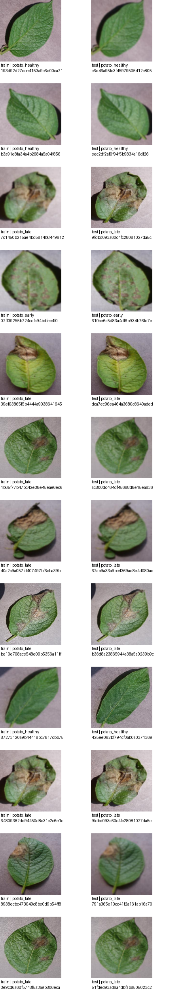

In [68]:
# Visualize the strongest candidates for review
from pathlib import Path
from PIL import Image, ImageOps, ImageDraw
from IPython.display import display
import pandas as pd

REPORT = Path(
    r"C:\Intro_TO_AI_Project\group_split_near_duplicate_report.csv"
)

df = pd.read_csv(REPORT)
review = df[df["distance"] == 0].head(12)

tile_w, tile_h = 230, 210
canvas = Image.new("RGB", (tile_w * 2, tile_h * len(review)), "white")
draw = ImageDraw.Draw(canvas)

for i, (_, row) in enumerate(review.iterrows()):
    y = i * tile_h

    for col, path_col in enumerate(["path_a", "path_b"]):
        with Image.open(row[path_col]) as img:
            thumb = ImageOps.contain(img.convert("RGB"), (220, 155))

        x = col * tile_w
        canvas.paste(thumb, (x, y))

        split = row["split_a"] if col == 0 else row["split_b"]
        label = row["class_a"] if col == 0 else row["class_b"]
        filename = row["file_a"] if col == 0 else row["file_b"]

        draw.text(
            (x + 2, y + 158),
            f"{split} | {label}\n{filename[:27]}",
            fill="black"
        )

display(canvas)


In [69]:
review = df[df["distance"] == 0].iloc[12:24]

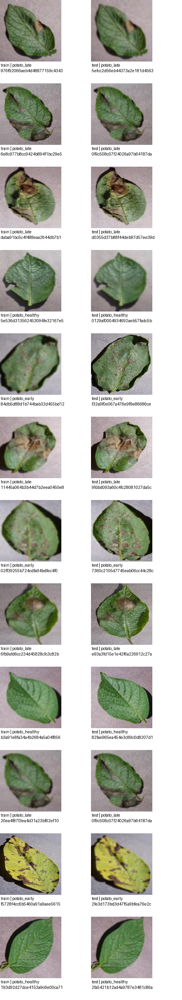

In [70]:

from pathlib import Path
from PIL import Image, ImageOps, ImageDraw
from IPython.display import display
import pandas as pd

REPORT = Path(
    r"C:\Intro_TO_AI_Project\group_split_near_duplicate_report.csv"
)

df = pd.read_csv(REPORT)
review = df[df["distance"] == 0].iloc[12:24]

if review.empty:
    print("No more distance-0 pairs in this range.")
else:
    tile_w, tile_h = 230, 210
    canvas = Image.new(
        "RGB", (tile_w * 2, tile_h * len(review)), "white"
    )
    draw = ImageDraw.Draw(canvas)

    for i, (_, row) in enumerate(review.iterrows()):
        y = i * tile_h

        for col, path_col in enumerate(["path_a", "path_b"]):
            with Image.open(row[path_col]) as img:
                thumb = ImageOps.contain(
                    img.convert("RGB"), (220, 155)
                )

            x = col * tile_w
            canvas.paste(thumb, (x, y))

            split = row["split_a"] if col == 0 else row["split_b"]
            label = row["class_a"] if col == 0 else row["class_b"]
            filename = row["file_a"] if col == 0 else row["file_b"]

            draw.text(
                (x + 2, y + 158),
                f"{split} | {label}\n{filename[:27]}",
                fill="black"
            )

    display(canvas)


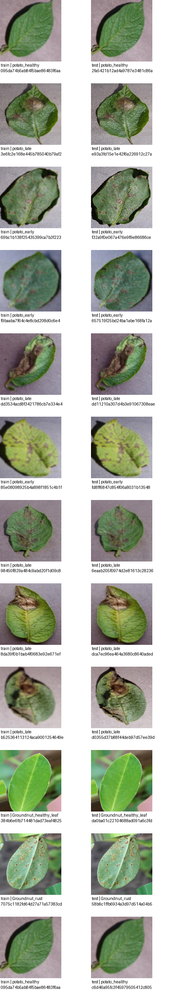

In [71]:

review = df[df["distance"] == 0].iloc[24:36]

if review.empty:
    print("No more pairs in this range.")
else:
    tile_w, tile_h = 230, 210
    canvas = Image.new(
        "RGB", (tile_w * 2, tile_h * len(review)), "white"
    )
    draw = ImageDraw.Draw(canvas)

    for i, (_, row) in enumerate(review.iterrows()):
        y = i * tile_h

        for col, path_col in enumerate(["path_a", "path_b"]):
            with Image.open(row[path_col]) as img:
                thumb = ImageOps.contain(
                    img.convert("RGB"), (220, 155)
                )

            x = col * tile_w
            canvas.paste(thumb, (x, y))

            split = row["split_a"] if col == 0 else row["split_b"]
            label = row["class_a"] if col == 0 else row["class_b"]
            filename = row["file_a"] if col == 0 else row["file_b"]

            draw.text(
                (x + 2, y + 158),
                f"{split} | {label}\n{filename[:27]}",
                fill="black"
            )

    display(canvas)


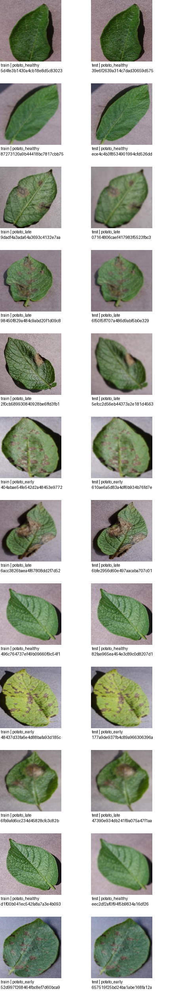

In [72]:

review = df[df["distance"] == 0].iloc[36:48]

if review.empty:
    print("No more pairs in this range.")
else:
    tile_w, tile_h = 230, 210
    canvas = Image.new(
        "RGB", (tile_w * 2, tile_h * len(review)), "white"
    )
    draw = ImageDraw.Draw(canvas)

    for i, (_, row) in enumerate(review.iterrows()):
        y = i * tile_h

        for col, path_col in enumerate(["path_a", "path_b"]):
            with Image.open(row[path_col]) as img:
                thumb = ImageOps.contain(
                    img.convert("RGB"), (220, 155)
                )

            x = col * tile_w
            canvas.paste(thumb, (x, y))

            split = row["split_a"] if col == 0 else row["split_b"]
            label = row["class_a"] if col == 0 else row["class_b"]
            filename = row["file_a"] if col == 0 else row["file_b"]

            draw.text(
                (x + 2, y + 158),
                f"{split} | {label}\n{filename[:27]}",
                fill="black"
            )

    display(canvas)


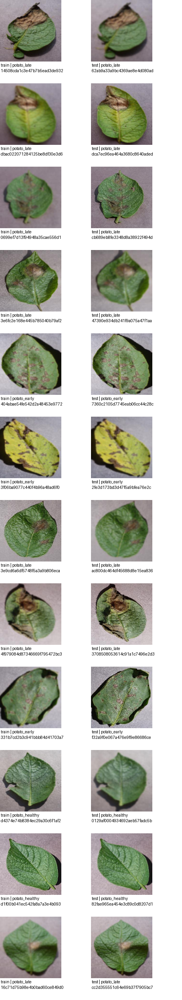

In [73]:

review = df[df["distance"] == 0].iloc[48:60]

if review.empty:
    print("No more pairs in this range.")
else:
    tile_w, tile_h = 230, 210
    canvas = Image.new(
        "RGB", (tile_w * 2, tile_h * len(review)), "white"
    )
    draw = ImageDraw.Draw(canvas)

    for i, (_, row) in enumerate(review.iterrows()):
        y = i * tile_h

        for col, path_col in enumerate(["path_a", "path_b"]):
            with Image.open(row[path_col]) as img:
                thumb = ImageOps.contain(
                    img.convert("RGB"), (220, 155)
                )

            x = col * tile_w
            canvas.paste(thumb, (x, y))

            split = row["split_a"] if col == 0 else row["split_b"]
            label = row["class_a"] if col == 0 else row["class_b"]
            filename = row["file_a"] if col == 0 else row["file_b"]

            draw.text(
                (x + 2, y + 158),
                f"{split} | {label}\n{filename[:27]}",
                fill="black"
            )

    display(canvas)


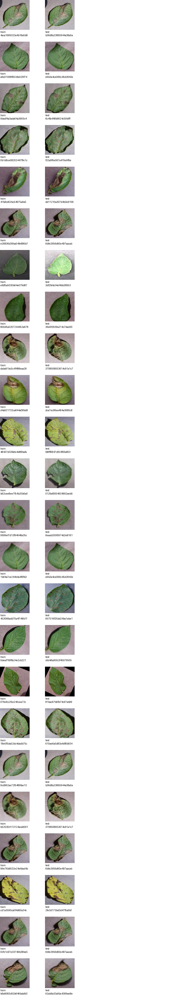

In [74]:

review = df[df["distance"] == 0].iloc[60:84]

if review.empty:
    print("No more pairs in this range.")
else:
    tile_w, tile_h = 190, 175
    columns = 4
    rows = len(review)

    canvas = Image.new(
        "RGB", (tile_w * columns, tile_h * rows), "white"
    )
    draw = ImageDraw.Draw(canvas)

    for i, (_, row) in enumerate(review.iterrows()):
        y = i * tile_h

        for col, path_col in enumerate(["path_a", "path_b"]):
            with Image.open(row[path_col]) as img:
                thumb = ImageOps.contain(
                    img.convert("RGB"), (180, 125)
                )

            x = col * tile_w
            canvas.paste(thumb, (x, y))

            split = row["split_a"] if col == 0 else row["split_b"]
            filename = row["file_a"] if col == 0 else row["file_b"]

            draw.text(
                (x + 2, y + 128),
                f"{split}\n{filename[:20]}",
                fill="black"
            )

    display(canvas)


In [75]:

from pathlib import Path
from collections import defaultdict, Counter
from itertools import combinations
from sklearn.model_selection import GroupShuffleSplit
import pandas as pd
import hashlib
import shutil
import uuid

SOURCE = Path(r"C:\Intro_TO_AI_Project\Plant_Diseases_Group_Split")
REPORT = Path(r"C:\Intro_TO_AI_Project\group_split_near_duplicate_report.csv")
OUTPUT = Path(r"C:\Intro_TO_AI_Project\Plant_Diseases_Final_Neat")

# Safety checks
if OUTPUT.exists():
    raise FileExistsError(
        f"{OUTPUT} already exists. Choose a new output folder."
    )
if not SOURCE.exists() or not REPORT.exists():
    raise FileNotFoundError("Source dataset or near-duplicate report not found.")

# 1. Collect all images.
records = []
for split in ["train", "valid", "test"]:
    for class_dir in sorted((SOURCE / split).iterdir()):
        if not class_dir.is_dir():
            continue
        for path in sorted(class_dir.iterdir()):
            if path.is_file():
                records.append({
                    "path": path,
                    "path_key": str(path.resolve()).lower(),
                    "label": class_dir.name
                })

print("Source images:", len(records))

path_to_index = {r["path_key"]: i for i, r in enumerate(records)}

# 2. Union-find: link images that appear in a pHash candidate pair.
parent = list(range(len(records)))

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra

candidates = pd.read_csv(REPORT)
candidates = candidates[candidates["distance"] <= 4].copy()

used_edges = 0
missing_paths = 0

for _, row in candidates.iterrows():
    a = str(Path(row["path_a"]).resolve()).lower()
    b = str(Path(row["path_b"]).resolve()).lower()

    if a not in path_to_index or b not in path_to_index:
        missing_paths += 1
        continue

    union(path_to_index[a], path_to_index[b])
    used_edges += 1

# Assign one group to each image.
roots = [find(i) for i in range(len(records))]
root_to_group = {}
groups = []

for root in roots:
    if root not in root_to_group:
        root_to_group[root] = len(root_to_group)
    groups.append(root_to_group[root])

print("Candidate pairs read:", len(candidates))
print("Candidate pairs linked:", used_edges)
print("Candidate paths missing:", missing_paths)
print("Connected groups:", len(set(groups)))

# 3. Flag groups with conflicting class labels.
labels_by_group = defaultdict(set)
for record, group_id in zip(records, groups):
    labels_by_group[group_id].add(record["label"])

conflict_rows = []
for record, group_id in zip(records, groups):
    labels = labels_by_group[group_id]
    if len(labels) > 1:
        conflict_rows.append({
            "group_id": group_id,
            "labels_in_group": " | ".join(sorted(labels)),
            "image_path": str(record["path"]),
            "image_label": record["label"]
        })

conflict_report = OUTPUT.parent / "final_neat_label_conflicts.csv"
pd.DataFrame(conflict_rows).to_csv(conflict_report, index=False)

print("Images in mixed-label groups:", len(conflict_rows))
print("Mixed-label report:", conflict_report)

# 4. Split whole groups. No group is divided across splits.
indices = list(range(len(records)))

splitter_test = GroupShuffleSplit(
    n_splits=1, test_size=0.15, random_state=42
)
train_valid_idx, test_idx = next(
    splitter_test.split(indices, groups=groups)
)

remaining_groups = [groups[i] for i in train_valid_idx]
remaining_idx = list(train_valid_idx)

splitter_valid = GroupShuffleSplit(
    n_splits=1, test_size=0.15 / 0.85, random_state=43
)
train_rel, valid_rel = next(
    splitter_valid.split(
        remaining_idx, groups=remaining_groups
    )
)

split_indices = {
    "train": [remaining_idx[i] for i in train_rel],
    "valid": [remaining_idx[i] for i in valid_rel],
    "test": list(test_idx)
}

# 5. Copy images with unique filenames.
for split_name, idxs in split_indices.items():
    for i in idxs:
        record = records[i]
        destination = OUTPUT / split_name / record["label"]
        destination.mkdir(parents=True, exist_ok=True)

        filename = f"{uuid.uuid4().hex}{record['path'].suffix.lower()}"
        shutil.copy2(record["path"], destination / filename)

# 6. Verify group separation and counts.
group_splits = defaultdict(set)
for split_name, idxs in split_indices.items():
    for i in idxs:
        group_splits[groups[i]].add(split_name)

crossing_groups = {
    g: s for g, s in group_splits.items() if len(s) > 1
}

actual_counts = {}
for split_name in ["train", "valid", "test"]:
    actual_counts[split_name] = sum(
        1 for p in (OUTPUT / split_name).rglob("*") if p.is_file()
    )

print("\nFINAL DATASET:", OUTPUT)
print("Train:", actual_counts["train"])
print("Validation:", actual_counts["valid"])
print("Test:", actual_counts["test"])
print("Total:", sum(actual_counts.values()))
print("Groups crossing splits:", len(crossing_groups))
print("All images retained:", sum(actual_counts.values()) == len(records))


Source images: 38794
Candidate pairs read: 740
Candidate pairs linked: 740
Candidate paths missing: 0
Connected groups: 38135
Images in mixed-label groups: 16
Mixed-label report: C:\Intro_TO_AI_Project\final_neat_label_conflicts.csv

FINAL DATASET: C:\Intro_TO_AI_Project\Plant_Diseases_Final_Neat
Train: 27136
Validation: 5813
Test: 5845
Total: 38794
Groups crossing splits: 0
All images retained: True


In [76]:

from pathlib import Path
import pandas as pd

REPORT = Path(
    r"C:\Intro_TO_AI_Project\final_neat_label_conflicts.csv"
)

conflicts = pd.read_csv(REPORT)

print("Images in mixed-label groups:", len(conflicts))
print("Conflicting groups:", conflicts["group_id"].nunique())

display(
    conflicts.sort_values(["group_id", "image_label"])
)

print("\nReport:", REPORT)


Images in mixed-label groups: 16
Conflicting groups: 3


,group_id,labels_in_group,image_path,image_label
12,14561,Tomato___Tomato_mosaic_virus | Tomato___healthy,C:\Intro_TO_AI_Project\Plant_Diseases_Group_Sp...,Tomato___Tomato_mosaic_virus
0,14561,Tomato___Tomato_mosaic_virus | Tomato___healthy,C:\Intro_TO_AI_Project\Plant_Diseases_Group_Sp...,Tomato___healthy
1,14561,Tomato___Tomato_mosaic_virus | Tomato___healthy,C:\Intro_TO_AI_Project\Plant_Diseases_Group_Sp...,Tomato___healthy
2,14561,Tomato___Tomato_mosaic_virus | Tomato___healthy,C:\Intro_TO_AI_Project\Plant_Diseases_Group_Sp...,Tomato___healthy
3,14561,Tomato___Tomato_mosaic_virus | Tomato___healthy,C:\Intro_TO_AI_Project\Plant_Diseases_Group_Sp...,Tomato___healthy
4,14561,Tomato___Tomato_mosaic_virus | Tomato___healthy,C:\Intro_TO_AI_Project\Plant_Diseases_Group_Sp...,Tomato___healthy
5,14561,Tomato___Tomato_mosaic_virus | Tomato___healthy,C:\Intro_TO_AI_Project\Plant_Diseases_Group_Sp...,Tomato___healthy
6,14561,Tomato___Tomato_mosaic_virus | Tomato___healthy,C:\Intro_TO_AI_Project\Plant_Diseases_Group_Sp...,Tomato___healthy
9,14561,Tomato___Tomato_mosaic_virus | Tomato___healthy,C:\Intro_TO_AI_Project\Plant_Diseases_Group_Sp...,Tomato___healthy
10,14561,Tomato___Tomato_mosaic_virus | Tomato___healthy,C:\Intro_TO_AI_Project\Plant_Diseases_Group_Sp...,Tomato___healthy



Report: C:\Intro_TO_AI_Project\final_neat_label_conflicts.csv



Group 14561 — 12 images


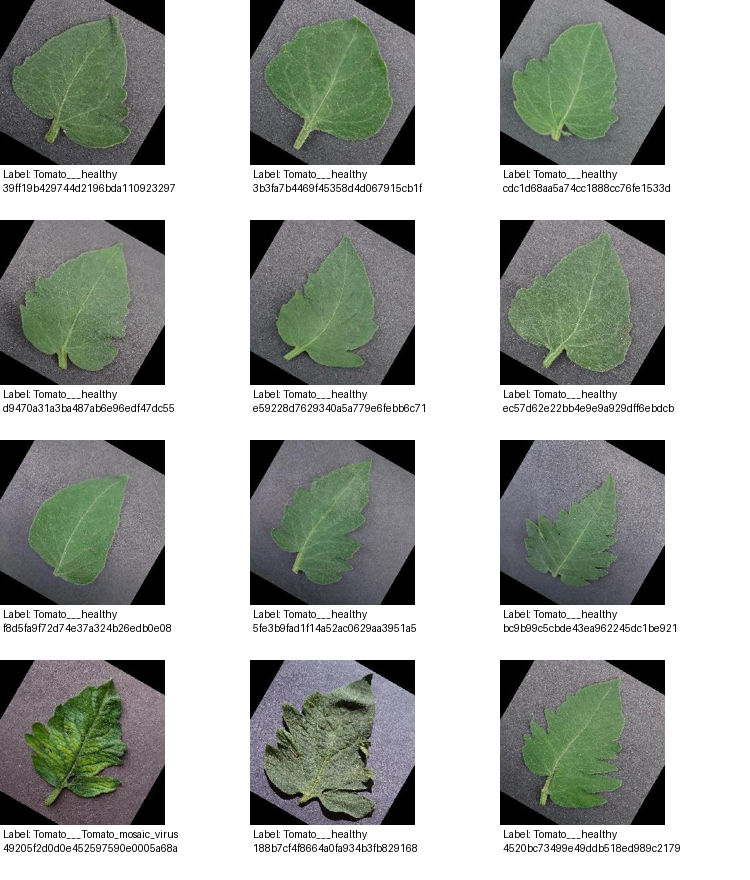


Group 17881 — 2 images


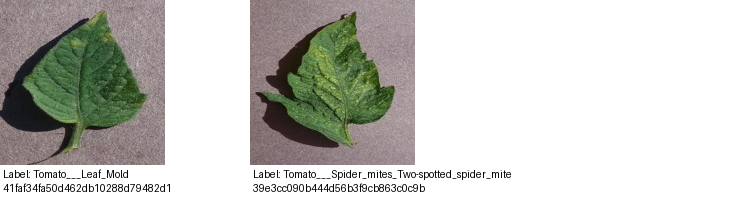


Group 22916 — 2 images


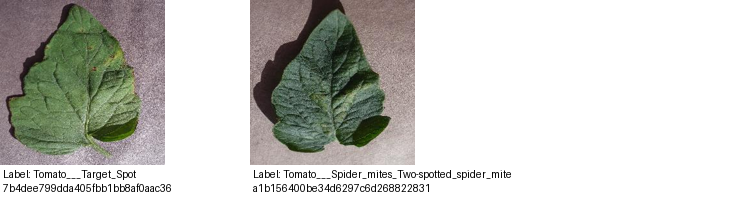

In [77]:

from pathlib import Path
from PIL import Image, ImageOps, ImageDraw
from IPython.display import display
import pandas as pd

REPORT = Path(
    r"C:\Intro_TO_AI_Project\final_neat_label_conflicts.csv"
)

conflicts = pd.read_csv(REPORT)

for group_id, group in conflicts.groupby("group_id"):
    print(f"\nGroup {group_id} — {len(group)} images")

    items = list(group.iterrows())
    tile_w, tile_h = 250, 220
    columns = 3
    rows = (len(items) + columns - 1) // columns

    canvas = Image.new(
        "RGB", (columns * tile_w, rows * tile_h), "white"
    )
    draw = ImageDraw.Draw(canvas)

    for i, (_, item) in enumerate(items):
        path = Path(item["image_path"])

        # The report contains paths from the previous split.
        # Skip paths that no longer exist; we will locate their
        # corresponding files in the final dataset if necessary.
        if not path.exists():
            print("Missing old path:", path.name)
            continue

        with Image.open(path) as img:
            thumb = ImageOps.contain(img.convert("RGB"), (235, 165))

        x = (i % columns) * tile_w
        y = (i // columns) * tile_h
        canvas.paste(thumb, (x, y))

        draw.text(
            (x + 3, y + 168),
            f"Label: {item['image_label']}\n{path.name[:30]}",
            fill="black"
        )

    display(canvas)


In [78]:

from pathlib import Path
from collections import defaultdict
import hashlib
import pandas as pd
import shutil

SOURCE = Path(
    r"C:\Intro_TO_AI_Project\Plant_Diseases_Final_Neat"
)
CONFLICT_REPORT = Path(
    r"C:\Intro_TO_AI_Project\final_neat_label_conflicts.csv"
)
OUTPUT = Path(
    r"C:\Intro_TO_AI_Project\Plant_Diseases_Final_Clean"
)

if OUTPUT.exists():
    raise FileExistsError(
        f"{OUTPUT} already exists. Choose another output folder."
    )

conflicts = pd.read_csv(CONFLICT_REPORT)

# Identify the source images from the three conflicting groups.
conflict_paths = {
    str(Path(p).resolve()).lower()
    for p in conflicts["image_path"].dropna()
}

# The report paths may refer to the previous split, so collect
# hashes from any matching source files that still exist.
conflict_hashes = set()

for path_text in conflict_paths:
    path = Path(path_text)
    if path.exists():
        conflict_hashes.add(
            hashlib.sha256(path.read_bytes()).hexdigest()
        )

# The current final folder contains renamed copies. Locate the
# matching images using the previous source paths when possible.
# If paths are unavailable, stop rather than guessing.
if not conflict_hashes:
    raise RuntimeError(
        "The old conflict paths are unavailable. "
        "We must map the conflict images to the final split "
        "before excluding anything."
    )

excluded = []
copied = 0

for split in ["train", "valid", "test"]:
    for image_path in (SOURCE / split).rglob("*"):
        if not image_path.is_file():
            continue

        digest = hashlib.sha256(image_path.read_bytes()).hexdigest()

        if digest in conflict_hashes:
            excluded.append((split, image_path.name, digest))
            continue

        destination = OUTPUT / split / image_path.parent.name
        destination.mkdir(parents=True, exist_ok=True)
        shutil.copy2(image_path, destination / image_path.name)
        copied += 1

print("Images excluded:", len(excluded))
print("Images copied:", copied)
print("Output folder:", OUTPUT)

if len(excluded) != 16:
    print(
        "WARNING: The number excluded is not 16. "
        "Do not use this output until we investigate."
    )
else:
    print("Confirmed: all 16 conflicting images were excluded.")


Images excluded: 16
Images copied: 38778
Output folder: C:\Intro_TO_AI_Project\Plant_Diseases_Final_Clean
Confirmed: all 16 conflicting images were excluded.


In [79]:

from pathlib import Path
from collections import defaultdict
import hashlib
import pandas as pd

FINAL_DIR = Path(
    r"C:\Intro_TO_AI_Project\Plant_Diseases_Final_Clean"
)

hash_locations = defaultdict(list)
rows = []

for split in ["train", "valid", "test"]:
    split_dir = FINAL_DIR / split

    for class_dir in sorted(split_dir.iterdir()):
        if not class_dir.is_dir():
            continue

        count = 0

        for image_path in class_dir.iterdir():
            if not image_path.is_file():
                continue

            count += 1
            digest = hashlib.sha256(image_path.read_bytes()).hexdigest()
            hash_locations[digest].append(
                (split, class_dir.name, image_path.name)
            )

        rows.append({
            "split": split,
            "class": class_dir.name,
            "images": count
        })

counts_df = pd.DataFrame(rows)
display(
    counts_df.pivot(
        index="class", columns="split", values="images"
    ).fillna(0).astype(int)
)

print("\nTotal images:", counts_df["images"].sum())
print("Classes:", counts_df["class"].nunique())

cross_split_duplicates = {
    digest: locations
    for digest, locations in hash_locations.items()
    if len({item[0] for item in locations}) > 1
}

print(
    "Exact duplicate groups crossing splits:",
    len(cross_split_duplicates)
)

for split in ["train", "valid", "test"]:
    print(
        f"{split} total:",
        counts_df.loc[counts_df["split"] == split, "images"].sum()
    )
    present = set(counts_df.loc[
        (counts_df["split"] == split) &
        (counts_df["images"] > 0), "class"
    ])
    print(f"{split} classes:", len(present))


split,test,train,valid
class,,,
Groundnut_early_leaf_spot,279,1192,260
Groundnut_early_rust,242,1001,230
Groundnut_healthy_leaf,271,1286,305
Groundnut_late_leaf_spot,289,1294,313
Groundnut_nutrition_deficiency,259,1164,234
Groundnut_rust,259,1209,256
Tomato___Bacterial_spot,308,1505,314
Tomato___Early_blight,364,1688,348
Tomato___Late_blight,326,1668,306



Total images: 38778
Classes: 19
Exact duplicate groups crossing splits: 0
train total: 27124
train classes: 19
valid total: 5811
valid classes: 19
test total: 5843
test classes: 19


In [80]:

from pathlib import Path
from collections import defaultdict
from itertools import combinations
import hashlib
import pandas as pd
from PIL import Image
import imagehash

FINAL_DIR = Path(
    r"C:\Intro_TO_AI_Project\Plant_Diseases_Final_Clean"
)
REPORT_DIR = Path(r"C:\Intro_TO_AI_Project")

SPLITS = ["train", "valid", "test"]
MAX_PHASH_DISTANCE = 4

# --------------------------------------------------
# 1. Collect images and calculate exact SHA-256 hashes
# --------------------------------------------------
records = []
exact_hashes = defaultdict(list)

for split in SPLITS:
    split_dir = FINAL_DIR / split

    if not split_dir.exists():
        raise FileNotFoundError(f"Missing split: {split_dir}")

    for path in split_dir.rglob("*"):
        if not path.is_file():
            continue

        sha = hashlib.sha256(path.read_bytes()).hexdigest()

        exact_hashes[sha].append({
            "split": split,
            "class": path.parent.name,
            "path": str(path)
        })

        try:
            with Image.open(path) as img:
                phash = int(str(imagehash.phash(img.convert("RGB"))), 16)
        except Exception as error:
            print("Unreadable image:", path, error)
            continue

        records.append({
            "split": split,
            "class": path.parent.name,
            "filename": path.name,
            "path": str(path),
            "sha256": sha,
            "phash": phash
        })

print("Images successfully checked:", len(records))

# Exact duplicate groups crossing splits
exact_cross = {
    sha: items
    for sha, items in exact_hashes.items()
    if len({item["split"] for item in items}) > 1
}

print("Exact duplicate groups crossing splits:", len(exact_cross))

# Save exact duplicate details if any are found
exact_rows = []
for sha, items in exact_cross.items():
    for item in items:
        exact_rows.append({"sha256": sha, **item})

pd.DataFrame(exact_rows).to_csv(
    REPORT_DIR / "final_clean_exact_leakage.csv", index=False
)

# --------------------------------------------------
# 2. Index pHashes in five bands to find candidates
# --------------------------------------------------
band_ranges = [(0, 13), (13, 26), (26, 39), (39, 52), (52, 64)]
band_index = defaultdict(list)

for i, rec in enumerate(records):
    value = rec["phash"]

    for start, end in band_ranges:
        width = end - start
        band_value = (value >> start) & ((1 << width) - 1)
        band_index[(start, end, band_value)].append(i)

candidate_pairs = set()

for bucket in band_index.values():
    if len(bucket) < 2:
        continue

    for i, j in combinations(bucket, 2):
        if records[i]["split"] != records[j]["split"]:
            candidate_pairs.add((min(i, j), max(i, j)))

# --------------------------------------------------
# 3. Measure cross-split perceptual-hash distances
# --------------------------------------------------
near_rows = []

for i, j in candidate_pairs:
    a, b = records[i], records[j]
    distance = (a["phash"] ^ b["phash"]).bit_count()

    if distance <= MAX_PHASH_DISTANCE:
        near_rows.append({
            "distance": distance,
            "split_a": a["split"],
            "class_a": a["class"],
            "file_a": a["filename"],
            "path_a": a["path"],
            "split_b": b["split"],
            "class_b": b["class"],
            "file_b": b["filename"],
            "path_b": b["path"],
            "same_class": a["class"] == b["class"],
            "same_sha256": a["sha256"] == b["sha256"]
        })

near_df = pd.DataFrame(near_rows)
near_path = REPORT_DIR / "final_clean_near_leakage.csv"
near_df.to_csv(near_path, index=False)

print("\nPotential cross-split near-duplicate pairs:", len(near_df))

if not near_df.empty:
    print("\nPairs by pHash distance:")
    print(near_df["distance"].value_counts().sort_index())

    print("\nPairs with different class labels:",
          (~near_df["same_class"]).sum())

    print("\nDistance-0 pairs:",
          (near_df["distance"] == 0).sum())

    print("\nReport saved to:", near_path)
    display(near_df.head(25))
else:
    print("No candidates within the selected pHash threshold.")

print("\nAudit completed. No files were changed.")


Images successfully checked: 38778
Exact duplicate groups crossing splits: 0

Potential cross-split near-duplicate pairs: 1725

Pairs by pHash distance:
distance
0    1332
2     212
4     181
Name: count, dtype: int64

Pairs with different class labels: 4

Distance-0 pairs: 1332

Report saved to: C:\Intro_TO_AI_Project\final_clean_near_leakage.csv


,distance,split_a,class_a,file_a,path_a,split_b,class_b,file_b,path_b,same_class,same_sha256
0,2,train,Groundnut_early_leaf_spot,b065f4e10e6f4531ac520bb4bd7f75cf.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Cl...,valid,Groundnut_early_leaf_spot,ae23e3ae322c4ba38bd42859f4b95388.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Cl...,True,False
1,0,train,potato_healthy,c7e1515ebafc4a248a6e58340568095c.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Cl...,valid,potato_healthy,a551a520d8a84d6786af9b8028bf4aa1.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Cl...,True,False
2,0,train,Groundnut_healthy_leaf,c4f9951837d14234b51e5be407dc8821.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Cl...,valid,Groundnut_healthy_leaf,69bfbe7e1ce04656b49e65fac0d841ef.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Cl...,True,False
3,2,train,potato_late,7898e26ac8a745269b0bd5ba2bd0b717.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Cl...,test,potato_late,89cf060de88040b99479a023e917f2cd.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Cl...,True,False
4,2,train,potato_healthy,f41c388661d84215b54463b5ee50654a.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Cl...,valid,potato_healthy,896104c2c78346c2b668c4052932ee8b.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Cl...,True,False
5,0,train,potato_late,8ff0ebdb0b814c7c90bf2ea354847be0.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Cl...,test,potato_late,5934332c0a4b40d68964c608faaef15f.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Cl...,True,False
6,0,train,potato_early,c9cbc0c36b694b2fbe08c960cac80406.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Cl...,test,potato_early,74429e0c6032496d837bc1284eb1d4f3.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Cl...,True,False
7,0,train,potato_late,586fafa364ad428091000bf9194c8f89.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Cl...,test,potato_late,bb3cb93dac1545328e5e53a2e2bcc3fc.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Cl...,True,False
8,4,valid,Tomato___Spider_mites_Two-spotted_spider_mite,9009d1c0be084a6b8b15b79242aa9e94.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Cl...,test,Tomato___Septoria_leaf_spot,bce7c9368fb04c16971ec6ab4dd3ddfc.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Cl...,False,False
9,0,train,potato_early,edd7a76ef2f7478d82643c1cdb5b94be.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Cl...,valid,potato_early,ad31abebd4cb401b8a14e447b6230428.jpg,C:\Intro_TO_AI_Project\Plant_Diseases_Final_Cl...,True,False



Audit completed. No files were changed.


In [81]:

from pathlib import Path
from collections import defaultdict
import shutil
import pandas as pd
from PIL import Image
from sklearn.model_selection import GroupShuffleSplit

# --------------------------------------------------
# 1. PATHS
# --------------------------------------------------
BASE = Path(r"C:\Intro_TO_AI_Project")
SOURCE = BASE / "Plant_Diseases_Final_Clean"
REPORT = BASE / "final_clean_near_leakage.csv"
OUTPUT = BASE / "Plant_Diseases_Final_Deduplicated"

REMOVALS_CSV = BASE / "final_deduplication_removals.csv"
AMBIGUOUS_CSV = BASE / "final_deduplication_different_labels.csv"
SUMMARY_CSV = BASE / "final_deduplicated_class_counts.csv"

if not SOURCE.exists():
    raise FileNotFoundError(f"Source dataset not found: {SOURCE}")

if not REPORT.exists():
    raise FileNotFoundError(f"Near-duplicate report not found: {REPORT}")

if OUTPUT.exists():
    raise FileExistsError(
        f"Output already exists: {OUTPUT}\n"
        "Rename or remove that output folder before running again."
    )

# --------------------------------------------------
# 2. LOAD ALL SOURCE IMAGES
# --------------------------------------------------
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
records = []

for split_dir in SOURCE.iterdir():
    if not split_dir.is_dir():
        continue

    split_name = split_dir.name.lower()
    if split_name not in {"train", "valid", "validation", "test"}:
        continue

    for class_dir in split_dir.iterdir():
        if not class_dir.is_dir():
            continue

        for path in class_dir.rglob("*"):
            if path.is_file() and path.suffix.lower() in image_extensions:
                # Check that the image can be opened
                try:
                    with Image.open(path) as im:
                        width, height = im.size
                        im.verify()

                    records.append({
                        "path": str(path.resolve()),
                        "class": class_dir.name,
                        "source_split": split_name,
                        "pixels": width * height,
                        "bytes": path.stat().st_size
                    })
                except Exception as e:
                    print(f"Skipping unreadable image: {path} | {e}")

df = pd.DataFrame(records)

if df.empty:
    raise RuntimeError("No readable images found in the source dataset.")

if df["path"].duplicated().any():
    raise RuntimeError("Duplicate file paths were found. Stop and inspect the source.")

print("Readable source images:", len(df))
print("Classes:", df["class"].nunique())
print(df.groupby("source_split").size())

# --------------------------------------------------
# 3. LOAD NEAR-DUPLICATE CANDIDATES
#    Join only same-class candidates at distance <= 4.
#    Different-label pairs are preserved and reported.
# --------------------------------------------------
pairs = pd.read_csv(REPORT)

required_columns = {
    "distance", "path_a", "path_b", "class_a", "class_b"
}
missing = required_columns - set(pairs.columns)
if missing:
    raise ValueError(f"Report is missing columns: {missing}")

def norm_path(p):
    return str(Path(str(p)).resolve()).casefold()

path_to_index = {
    norm_path(row.path): i
    for i, row in df.iterrows()
}

# Union-find for connected near-duplicate groups
parent = list(range(len(df)))
rank = [0] * len(df)

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def union(a, b):
    ra, rb = find(a), find(b)
    if ra == rb:
        return
    if rank[ra] < rank[rb]:
        ra, rb = rb, ra
    parent[rb] = ra
    if rank[ra] == rank[rb]:
        rank[ra] += 1

ambiguous_rows = []
used_edges = 0
missing_pairs = 0

for _, pair in pairs.iterrows():
    distance = int(pair["distance"])
    if distance > 4:
        continue

    pa = norm_path(pair["path_a"])
    pb = norm_path(pair["path_b"])

    if pa not in path_to_index or pb not in path_to_index:
        missing_pairs += 1
        continue

    ia, ib = path_to_index[pa], path_to_index[pb]

    # Do not automatically merge different classes
    if df.iloc[ia]["class"] != df.iloc[ib]["class"]:
        ambiguous_rows.append({
            "distance": distance,
            "class_a": df.iloc[ia]["class"],
            "path_a": df.iloc[ia]["path"],
            "class_b": df.iloc[ib]["class"],
            "path_b": df.iloc[ib]["path"],
            "action": "Both retained; different labels"
        })
        continue

    union(ia, ib)
    used_edges += 1

print("Same-class candidate links used:", used_edges)
print("Candidate pairs with missing paths:", missing_pairs)

pd.DataFrame(
    ambiguous_rows,
    columns=["distance", "class_a", "path_a", "class_b", "path_b", "action"]
).to_csv(AMBIGUOUS_CSV, index=False)

# --------------------------------------------------
# 4. KEEP ONE BEST IMAGE PER CONNECTED GROUP
#    Highest pixel count, then largest file size.
# --------------------------------------------------
df["group_id"] = [find(i) for i in range(len(df))]

keep_indices = []
removal_rows = []

for group_id, group in df.groupby("group_id"):
    group = group.sort_values(
        ["pixels", "bytes", "path"],
        ascending=[False, False, True]
    )
    winner = group.iloc[0]
    keep_indices.append(winner.name)

    for idx, row in group.iloc[1:].iterrows():
        removal_rows.append({
            "removed_path": row["path"],
            "class": row["class"],
            "kept_path": winner["path"],
            "group_id": group_id,
            "reason": "Same-class perceptual-hash connected group"
        })

kept = df.loc[keep_indices].copy().reset_index(drop=True)
pd.DataFrame(removal_rows).to_csv(REMOVALS_CSV, index=False)

print("Images before deduplication:", len(df))
print("Images retained:", len(kept))
print("Images removed:", len(df) - len(kept))
print("Different-label candidate pairs preserved:", len(ambiguous_rows))

# --------------------------------------------------
# 5. SPLIT BY GROUP, NOT BY INDIVIDUAL IMAGE
#    Approximate 70% train, 15% validation, 15% test.
# --------------------------------------------------
groups = kept["group_id"].to_numpy()
indices = list(range(len(kept)))

first_split = GroupShuffleSplit(
    n_splits=1, test_size=0.15, random_state=42
)
train_valid_idx, test_idx = next(
    first_split.split(indices, groups=groups)
)

train_valid = kept.iloc[train_valid_idx].copy()
test = kept.iloc[test_idx].copy()

# 15% of the full dataset / 85% remaining = validation fraction
valid_fraction = 0.15 / 0.85
second_split = GroupShuffleSplit(
    n_splits=1, test_size=valid_fraction, random_state=43
)
train_idx, valid_idx = next(
    second_split.split(
        train_valid,
        groups=train_valid["group_id"].to_numpy()
    )
)

train = train_valid.iloc[train_idx].copy()
valid = train_valid.iloc[valid_idx].copy()

# Check that all classes occur in all three splits
all_classes = set(kept["class"])
for split_name, split_df in [
    ("train", train), ("valid", valid), ("test", test)
]:
    missing_classes = all_classes - set(split_df["class"])
    if missing_classes:
        raise RuntimeError(
            f"{split_name} is missing classes: {sorted(missing_classes)}. "
            "No dataset was copied; adjust the split strategy."
        )

# Confirm no detected group crosses splits
split_group_sets = {
    "train": set(train["group_id"]),
    "valid": set(valid["group_id"]),
    "test": set(test["group_id"])
}
assert not (split_group_sets["train"] & split_group_sets["valid"])
assert not (split_group_sets["train"] & split_group_sets["test"])
assert not (split_group_sets["valid"] & split_group_sets["test"])

# --------------------------------------------------
# 6. COPY TO NEW FOLDER WITH UNIQUE FILENAMES
# --------------------------------------------------
for split_name, split_df in [
    ("train", train), ("valid", valid), ("test", test)
]:
    for class_name, class_df in split_df.groupby("class"):
        destination_dir = OUTPUT / split_name / class_name
        destination_dir.mkdir(parents=True, exist_ok=True)

        for number, (_, row) in enumerate(
            class_df.sort_values("path").iterrows(), start=1
        ):
            source_path = Path(row["path"])
            destination_path = (
                destination_dir /
                f"{number:06d}_{source_path.stem}{source_path.suffix.lower()}"
            )
            shutil.copy2(source_path, destination_path)

# --------------------------------------------------
# 7. SAVE CLASS COUNTS AND SUMMARY
# --------------------------------------------------
summary = pd.DataFrame({
    "train": train["class"].value_counts(),
    "valid": valid["class"].value_counts(),
    "test": test["class"].value_counts()
}).fillna(0).astype(int).sort_index()

summary["total"] = summary.sum(axis=1)
summary.to_csv(SUMMARY_CSV, index_label="class")

print("\nFINAL DATASET CREATED")
print("Folder:", OUTPUT)
print("Train:", len(train))
print("Validation:", len(valid))
print("Test:", len(test))
print("Total retained:", len(kept))
print("Classes:", kept["class"].nunique())
print("\nClass counts:")
print(summary)
print("\nReports:")
print("Removed images:", REMOVALS_CSV)
print("Different-label candidates:", AMBIGUOUS_CSV)
print("Class counts:", SUMMARY_CSV)


Readable source images: 38778
Classes: 19
source_split
test      5843
train    27124
valid     5811
dtype: int64
Same-class candidate links used: 1721
Candidate pairs with missing paths: 0
Images before deduplication: 38778
Images retained: 37501
Images removed: 1277
Different-label candidate pairs preserved: 4

FINAL DATASET CREATED
Folder: C:\Intro_TO_AI_Project\Plant_Diseases_Final_Deduplicated
Train: 26250
Validation: 5625
Test: 5626
Total retained: 37501
Classes: 19

Class counts:
                                               train  valid  test  total
class                                                                   
Groundnut_early_leaf_spot                       1202    242   267   1711
Groundnut_early_rust                             992    225   212   1429
Groundnut_healthy_leaf                          1265    282   297   1844
Groundnut_late_leaf_spot                        1295    306   259   1860
Groundnut_nutrition_deficiency                  1140    244   231   161

In [83]:

from pathlib import Path
from collections import defaultdict
import hashlib
import pandas as pd

ROOT = Path(r"C:\Intro_TO_AI_Project\Plant_Diseases_Final_Deduplicated")
SPLITS = ["train", "valid", "test"]
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

hash_locations = defaultdict(list)
class_counts = []
total_images = 0

for split in SPLITS:
    split_dir = ROOT / split

    if not split_dir.exists():
        raise FileNotFoundError(f"Missing split folder: {split_dir}")

    for class_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        files = [
            p for p in class_dir.rglob("*")
            if p.is_file() and p.suffix.lower() in EXTENSIONS
        ]

        class_counts.append({
            "split": split,
            "class": class_dir.name,
            "images": len(files)
        })

        for path in files:
            digest = hashlib.sha256(path.read_bytes()).hexdigest()
            hash_locations[digest].append({
                "split": split,
                "class": class_dir.name,
                "path": str(path)
            })
            total_images += 1

cross_split_duplicates = []

for digest, locations in hash_locations.items():
    splits_found = {item["split"] for item in locations}

    if len(splits_found) > 1:
        for item in locations:
            cross_split_duplicates.append({
                "sha256": digest,
                **item
            })

counts_df = pd.DataFrame(class_counts)
duplicates_df = pd.DataFrame(
    cross_split_duplicates,
    columns=["sha256", "split", "class", "path"]
)

counts_df.to_csv(ROOT / "class_counts_audit.csv", index=False)
duplicates_df.to_csv(ROOT / "exact_cross_split_duplicates.csv", index=False)

print("Total images:", total_images)
print("Classes:", counts_df["class"].nunique())
print("\nImages per split:")
print(counts_df.groupby("split")["images"].sum())
print("\nClasses missing from any split:")
print(
    counts_df[counts_df["images"] == 0][["split", "class"]]
    .to_string(index=False)
    if (counts_df["images"] == 0).any()
    else "None"
)
print("\nExact duplicate files crossing splits:", len(duplicates_df))
print("Audit report:", ROOT / "exact_cross_split_duplicates.csv")


Total images: 37501
Classes: 19

Images per split:
split
test      5626
train    26250
valid     5625
Name: images, dtype: int64

Classes missing from any split:
None

Exact duplicate files crossing splits: 0
Audit report: C:\Intro_TO_AI_Project\Plant_Diseases_Final_Deduplicated\exact_cross_split_duplicates.csv


In [85]:

# DEEP VISUAL LEAKAGE AUDIT
# Does not delete or modify any dataset images.

from pathlib import Path
from collections import defaultdict
import hashlib
import pandas as pd
import numpy as np
from PIL import Image, ImageOps, ImageDraw
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.preprocessing import normalize

ROOT = Path(r"C:\Intro_TO_AI_Project\Plant_Diseases_Final_Deduplicated")
AUDIT_DIR = ROOT / "deep_embedding_audit"
AUDIT_DIR.mkdir(exist_ok=True)

SPLITS = ["train", "valid", "test"]
EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

# 1. Collect the dataset manifest
records = []
for split in SPLITS:
    for class_dir in sorted((ROOT / split).iterdir()):
        if not class_dir.is_dir():
            continue
        for p in class_dir.rglob("*"):
            if p.is_file() and p.suffix.lower() in EXTS:
                records.append({
                    "path": str(p.resolve()),
                    "split": split,
                    "class": class_dir.name
                })

manifest = pd.DataFrame(records)
if manifest.empty:
    raise RuntimeError(f"No images found under {ROOT}")

print("Images to analyse:", len(manifest))
print("Device:", "CUDA GPU" if torch.cuda.is_available() else "CPU")

# 2. Extract deep visual features using pretrained ResNet18
weights = ResNet18_Weights.DEFAULT
transform = weights.transforms()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = resnet18(weights=weights)
model.fc = torch.nn.Identity()
model = model.to(device).eval()

class LeafImages(Dataset):
    def __init__(self, frame):
        self.frame = frame.reset_index(drop=True)

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, i):
        row = self.frame.iloc[i]
        try:
            with Image.open(row["path"]) as im:
                image = ImageOps.exif_transpose(im).convert("RGB")
            return transform(image), i
        except Exception as e:
            print("Unreadable image:", row["path"], str(e))
            return torch.zeros(3, 224, 224), i

loader = DataLoader(
    LeafImages(manifest),
    batch_size=64,
    shuffle=False,
    num_workers=0
)

features = []
with torch.inference_mode():
    for batch_num, (images, _) in enumerate(loader, start=1):
        images = images.to(device)
        vectors = model(images)
        vectors = torch.nn.functional.normalize(vectors, p=2, dim=1)
        features.append(vectors.cpu().numpy())

        if batch_num % 50 == 0:
            print("Batches processed:", batch_num, "/", len(loader))

features = np.concatenate(features).astype("float32")
print("Feature matrix:", features.shape)

# 3. Compare every image against images in OTHER splits.
# Use chunking to avoid allocating one huge similarity matrix.
# Top 5 neighbours are kept for each cross-split comparison.
all_candidates = []

split_indices = {
    s: np.flatnonzero(manifest["split"].to_numpy() == s)
    for s in SPLITS
}

for split_a, split_b in [
    ("train", "valid"),
    ("train", "test"),
    ("valid", "test")
]:
    idx_a = split_indices[split_a]
    idx_b = split_indices[split_b]

    print(f"Comparing {split_a} vs {split_b}:",
          len(idx_a), "x", len(idx_b))

    # Search both directions so each image can contribute its nearest matches.
    for query_idx, target_idx in [(idx_a, idx_b), (idx_b, idx_a)]:
        for start in range(0, len(query_idx), 256):
            q_idx = query_idx[start:start + 256]
            sims = features[q_idx] @ features[target_idx].T

            k = min(5, len(target_idx))
            top_positions = np.argpartition(
                -sims, kth=k-1, axis=1
            )[:, :k]

            for row_num, positions in enumerate(top_positions):
                # Sort the selected neighbours by descending similarity
                positions = sorted(
                    positions,
                    key=lambda pos: sims[row_num, pos],
                    reverse=True
                )

                qi = int(q_idx[row_num])
                qrow = manifest.iloc[qi]

                for pos in positions:
                    score = float(sims[row_num, pos])
                    ti = int(target_idx[pos])
                    trow = manifest.iloc[ti]

                    # Exploratory threshold: keep reasonably similar matches.
                    if score < 0.90:
                        continue

                    # Canonical pair key prevents duplicate pair rows.
                    pair_key = tuple(sorted((qi, ti)))
                    all_candidates.append({
                        "pair_key": pair_key,
                        "cosine_similarity": score,
                        "split_a": qrow["split"],
                        "class_a": qrow["class"],
                        "path_a": qrow["path"],
                        "split_b": trow["split"],
                        "class_b": trow["class"],
                        "path_b": trow["path"]
                    })

# Deduplicate pairs; keep the highest score if repeated.
if all_candidates:
    candidates = pd.DataFrame(all_candidates)
    candidates = (
        candidates.sort_values("cosine_similarity", ascending=False)
        .drop_duplicates("pair_key")
        .drop(columns="pair_key")
        .reset_index(drop=True)
    )
else:
    candidates = pd.DataFrame(columns=[
        "cosine_similarity", "split_a", "class_a", "path_a",
        "split_b", "class_b", "path_b"
    ])

candidate_path = AUDIT_DIR / "deep_embedding_leakage_candidates.csv"
candidates.to_csv(candidate_path, index=False)

high = candidates[
    candidates["cosine_similarity"] >= 0.97
].copy()

high_path = AUDIT_DIR / "deep_embedding_high_similarity.csv"
high.to_csv(high_path, index=False)

print("\n--- DEEP AUDIT RESULTS ---")
print("Cross-split candidate pairs >= 0.90:", len(candidates))
print("High-similarity pairs >= 0.97:", len(high))
print("Same-label high-similarity pairs:",
      int((high["class_a"] == high["class_b"]).sum()) if len(high) else 0)
print("Different-label high-similarity pairs:",
      int((high["class_a"] != high["class_b"]).sum()) if len(high) else 0)
print("\nCandidate report:", candidate_path)
print("High-similarity report:", high_path)

# 4. Create contact sheets for visual inspection of the strongest matches.
# These are review sheets, not automatic duplicate verdicts.
SHEET_DIR = AUDIT_DIR / "deep_audit_contact_sheets"
SHEET_DIR.mkdir(exist_ok=True)

def make_contact_sheet(frame, sheet_number, per_sheet=20):
    subset = frame.iloc[
        sheet_number * per_sheet:(sheet_number + 1) * per_sheet
    ]

    if subset.empty:
        return

    thumb_w, thumb_h = 220, 180
    label_h = 62
    pair_h = thumb_h + label_h
    sheet = Image.new(
        "RGB", (thumb_w * 2, pair_h * len(subset)), "white"
    )
    draw = ImageDraw.Draw(sheet)

    for n, (_, row) in enumerate(subset.iterrows()):
        y = n * pair_h

        for col, path_col in enumerate(["path_a", "path_b"]):
            x = col * thumb_w
            try:
                with Image.open(row[path_col]) as im:
                    im = ImageOps.exif_transpose(im).convert("RGB")
                    im.thumbnail((thumb_w - 8, thumb_h - 8))
                    sheet.paste(im, (x + 4, y + 4))
            except Exception:
                draw.text((x + 5, y + 5), "Image unavailable", fill="red")

        draw.text(
            (4, y + thumb_h + 2),
            f"SIM={row['cosine_similarity']:.4f} | "
            f"A: {row['split_a']} / {row['class_a'][:22]}",
            fill="black"
        )
        draw.text(
            (thumb_w + 4, y + thumb_h + 2),
            f"B: {row['split_b']} / {row['class_b'][:22]}",
            fill="black"
        )

    output = SHEET_DIR / f"contact_sheet_{sheet_number + 1:03d}.jpg"
    sheet.save(output, quality=90)
    print("Saved:", output)

# Top 100 high-similarity pairs, if available
review = high.head(100).reset_index(drop=True)
for sheet_number in range((len(review) + 19) // 20):
    make_contact_sheet(review, sheet_number)

print("\nContact sheets folder:", SHEET_DIR)


Images to analyse: 37501
Device: CPU
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\KEERTHAN REDDY/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


Batches processed: 50 / 586
Batches processed: 100 / 586
Batches processed: 150 / 586
Batches processed: 200 / 586
Batches processed: 250 / 586
Batches processed: 300 / 586
Batches processed: 350 / 586
Batches processed: 400 / 586
Batches processed: 450 / 586
Batches processed: 500 / 586
Batches processed: 550 / 586
Feature matrix: (37501, 512)
Comparing train vs valid: 26250 x 5625
Comparing train vs test: 26250 x 5626
Comparing valid vs test: 5625 x 5626

--- DEEP AUDIT RESULTS ---
Cross-split candidate pairs >= 0.90: 132370
High-similarity pairs >= 0.97: 3136
Same-label high-similarity pairs: 3131
Different-label high-similarity pairs: 5

Candidate report: C:\Intro_TO_AI_Project\Plant_Diseases_Final_Deduplicated\deep_embedding_audit\deep_embedding_leakage_candidates.csv
High-similarity report: C:\Intro_TO_AI_Project\Plant_Diseases_Final_Deduplicated\deep_embedding_audit\deep_embedding_high_similarity.csv
Saved: C:\Intro_TO_AI_Project\Plant_Diseases_Final_Deduplicated\deep_embedding_

In [86]:

from pathlib import Path
import pandas as pd

ROOT = Path(r"C:\Intro_TO_AI_Project\Plant_Diseases_Final_Deduplicated")
REPORT = ROOT / "deep_embedding_audit" / "deep_embedding_high_similarity.csv"

df = pd.read_csv(REPORT)

df["different_label"] = df["class_a"] != df["class_b"]

print("Total high-similarity pairs:", len(df))
print("\nPairs by similarity band:")
print(pd.cut(
    df["cosine_similarity"],
    bins=[0.97, 0.98, 0.99, 1.000001],
    right=False
).value_counts().sort_index())

print("\nDifferent-label pairs:")
print(
    df.loc[
        df["different_label"],
        ["cosine_similarity", "split_a", "class_a", "path_a",
         "split_b", "class_b", "path_b"]
    ].sort_values("cosine_similarity", ascending=False).to_string(index=False)
)

print("\nTop 30 strongest matches:")
print(
    df.sort_values("cosine_similarity", ascending=False)
      .head(30)[
          ["cosine_similarity", "split_a", "class_a", "path_a",
           "split_b", "class_b", "path_b"]
      ].to_string(index=False)
)

print("\nPair counts by split combination:")
print(df.groupby(["split_a", "split_b"]).size())


Total high-similarity pairs: 3136

Pairs by similarity band:
cosine_similarity
[0.97, 0.98)    2331
[0.98, 0.99)     760
[0.99, 1.0)       45
Name: count, dtype: int64

Different-label pairs:
 cosine_similarity split_a                   class_a                                                                                                                               path_a split_b                   class_b                                                                                                                               path_b
          0.981735    test Groundnut_early_leaf_spot  C:\Intro_TO_AI_Project\Plant_Diseases_Final_Deduplicated\test\Groundnut_early_leaf_spot\000141_8f7d8e5f987a4d379642e8b20373c440.jpg   valid  Groundnut_late_leaf_spot  C:\Intro_TO_AI_Project\Plant_Diseases_Final_Deduplicated\valid\Groundnut_late_leaf_spot\000156_922c46f375064299ae927d3864217ad5.jpg
          0.979919   train Groundnut_early_leaf_spot C:\Intro_TO_AI_Project\Plant_Diseases_Final_Dedup

In [87]:

from pathlib import Path
import pandas as pd

ROOT = Path(r"C:\Intro_TO_AI_Project\Plant_Diseases_Final_Deduplicated")
REPORT = ROOT / "deep_embedding_audit" / "deep_embedding_high_similarity.csv"

df = pd.read_csv(REPORT)
THRESHOLD = 0.97

pairs = df[df["cosine_similarity"] >= THRESHOLD].copy()

# Count all images in the dataset, including images absent from the report
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
image_paths = [
    str(p.resolve()).casefold()
    for split in ["train", "valid", "test"]
    for p in (ROOT / split).rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
]
all_images = set(image_paths)

def estimate_remaining(pair_df, same_class_only=False):
    parent = {p: p for p in all_images}

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    def union(a, b):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[rb] = ra

    for _, r in pair_df.iterrows():
        a = str(Path(r["path_a"]).resolve()).casefold()
        b = str(Path(r["path_b"]).resolve()).casefold()

        if a not in parent or b not in parent:
            continue

        if same_class_only and r["class_a"] != r["class_b"]:
            continue

        union(a, b)

    groups = {}
    for p in all_images:
        groups.setdefault(find(p), []).append(p)

    removed = sum(len(g) - 1 for g in groups.values())
    remaining = len(all_images) - removed
    return remaining, removed, sum(len(g) > 1 for g in groups.values())

print("Starting images:", len(all_images))
print("High-similarity pairs:", len(pairs))

for label, same_only in [
    ("All candidate links", False),
    ("Same-class links only", True)
]:
    remaining, removed, groups = estimate_remaining(pairs, same_only)
    print(f"\n{label}:")
    print("Estimated remaining:", remaining)
    print("Estimated removed:", removed)
    print("Connected groups with multiple images:", groups)

print("\nNo images have been deleted.")


Starting images: 37501
High-similarity pairs: 3136

All candidate links:
Estimated remaining: 35184
Estimated removed: 2317
Connected groups with multiple images: 833

Same-class links only:
Estimated remaining: 35188
Estimated removed: 2313
Connected groups with multiple images: 832

No images have been deleted.


In [88]:

from pathlib import Path
from collections import defaultdict
import shutil
import pandas as pd
from PIL import Image, ImageOps
from sklearn.model_selection import GroupShuffleSplit

# --------------------------------------------------
# CONFIGURATION
# --------------------------------------------------
ROOT = Path(r"C:\Intro_TO_AI_Project\Plant_Diseases_Final_Deduplicated")
REPORT = ROOT / "deep_embedding_audit" / "deep_embedding_high_similarity.csv"

OUTPUT = Path(r"C:\Intro_TO_AI_Project\Plant_Diseases_Leakage_Reduced")
REMOVALS_REPORT = OUTPUT.parent / "final_removed_images.csv"
AUDIT_REPORT = OUTPUT.parent / "final_different_label_candidates.csv"
COUNTS_REPORT = OUTPUT.parent / "final_dataset_class_counts.csv"

EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
THRESHOLD = 0.97

if not ROOT.exists():
    raise FileNotFoundError(f"Dataset not found: {ROOT}")
if not REPORT.exists():
    raise FileNotFoundError(f"Similarity report not found: {REPORT}")
if OUTPUT.exists():
    raise FileExistsError(
        f"{OUTPUT} already exists. Rename it before running this cell."
    )

# --------------------------------------------------
# 1. BUILD IMAGE MANIFEST
# --------------------------------------------------
rows = []

for split in ["train", "valid", "test"]:
    split_dir = ROOT / split
    for class_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        for path in class_dir.rglob("*"):
            if path.is_file() and path.suffix.lower() in EXTS:
                with Image.open(path) as im:
                    im = ImageOps.exif_transpose(im)
                    width, height = im.size
                    im.verify()

                rows.append({
                    "path": str(path.resolve()),
                    "class": class_dir.name,
                    "pixels": width * height,
                    "bytes": path.stat().st_size
                })

images = pd.DataFrame(rows).reset_index(drop=True)
if images.empty:
    raise RuntimeError("No images found.")

def norm(p):
    return str(Path(p).resolve()).casefold()

path_index = {norm(p): i for i, p in enumerate(images["path"])}
if len(path_index) != len(images):
    raise RuntimeError("Repeated image paths found; stopping.")

# --------------------------------------------------
# 2. GROUP DETECTED SAME-CLASS MATCHES
# --------------------------------------------------
pairs = pd.read_csv(REPORT)

parent = list(range(len(images)))
rank = [0] * len(images)

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def union(a, b):
    ra, rb = find(a), find(b)
    if ra == rb:
        return
    if rank[ra] < rank[rb]:
        ra, rb = rb, ra
    parent[rb] = ra
    if rank[ra] == rank[rb]:
        rank[ra] += 1

different_label = []

for _, r in pairs.iterrows():
    if float(r["cosine_similarity"]) < THRESHOLD:
        continue

    pa, pb = norm(r["path_a"]), norm(r["path_b"])
    if pa not in path_index or pb not in path_index:
        continue

    a, b = path_index[pa], path_index[pb]
    class_a = images.iloc[a]["class"]
    class_b = images.iloc[b]["class"]

    if class_a != class_b:
        different_label.append({
            "similarity": r["cosine_similarity"],
            "class_a": class_a,
            "path_a": images.iloc[a]["path"],
            "class_b": class_b,
            "path_b": images.iloc[b]["path"],
            "action": "Both retained; labels differ"
        })
    else:
        union(a, b)

# Save ambiguous pairs; do not silently discard differently labelled images.
pd.DataFrame(different_label).to_csv(AUDIT_REPORT, index=False)

images["group_id"] = [find(i) for i in range(len(images))]

# Keep the largest-resolution representative in each group.
kept_indices = []
removed_rows = []

for group_id, group in images.groupby("group_id"):
    group = group.sort_values(
        ["pixels", "bytes", "path"],
        ascending=[False, False, True]
    )
    winner = group.iloc[0]
    kept_indices.append(winner.name)

    for _, row in group.iloc[1:].iterrows():
        removed_rows.append({
            "removed_path": row["path"],
            "class": row["class"],
            "kept_path": winner["path"],
            "group_id": group_id
        })

kept = images.loc[kept_indices].copy().reset_index(drop=True)
pd.DataFrame(removed_rows).to_csv(REMOVALS_REPORT, index=False)

print("Original images:", len(images))
print("Images retained:", len(kept))
print("Images removed:", len(images) - len(kept))
print("Different-label candidate pairs retained:", len(different_label))

# --------------------------------------------------
# 3. GROUP-AWARE 70/15/15 SPLIT
# --------------------------------------------------
all_classes = set(kept["class"])
indices = list(range(len(kept)))
groups = kept["group_id"].to_numpy()

splitter1 = GroupShuffleSplit(
    n_splits=1, test_size=0.15, random_state=42
)
train_valid_idx, test_idx = next(
    splitter1.split(indices, groups=groups)
)

train_valid = kept.iloc[train_valid_idx].copy()
test = kept.iloc[test_idx].copy()

splitter2 = GroupShuffleSplit(
    n_splits=1, test_size=0.15 / 0.85, random_state=43
)
train_idx, valid_idx = next(
    splitter2.split(
        train_valid,
        groups=train_valid["group_id"].to_numpy()
    )
)

train = train_valid.iloc[train_idx].copy()
valid = train_valid.iloc[valid_idx].copy()

for name, part in [("train", train), ("valid", valid), ("test", test)]:
    missing = all_classes - set(part["class"])
    if missing:
        raise RuntimeError(
            f"{name} is missing classes: {sorted(missing)}. "
            "No output has been copied."
        )

# Ensure detected groups do not cross splits.
group_sets = {
    "train": set(train["group_id"]),
    "valid": set(valid["group_id"]),
    "test": set(test["group_id"])
}
assert not group_sets["train"] & group_sets["valid"]
assert not group_sets["train"] & group_sets["test"]
assert not group_sets["valid"] & group_sets["test"]

# --------------------------------------------------
# 4. COPY INTO A NEW DATASET
# --------------------------------------------------
for split_name, part in [
    ("train", train), ("valid", valid), ("test", test)
]:
    for class_name, class_part in part.groupby("class"):
        dest_dir = OUTPUT / split_name / class_name
        dest_dir.mkdir(parents=True, exist_ok=True)

        for number, (_, row) in enumerate(
            class_part.sort_values("path").iterrows(), start=1
        ):
            source = Path(row["path"])
            dest = dest_dir / (
                f"{number:06d}_{source.stem}{source.suffix.lower()}"
            )
            shutil.copy2(source, dest)

# --------------------------------------------------
# 5. COUNTS AND FINAL SUMMARY
# --------------------------------------------------
counts = pd.DataFrame({
    "train": train["class"].value_counts(),
    "valid": valid["class"].value_counts(),
    "test": test["class"].value_counts()
}).fillna(0).astype(int).sort_index()

counts["total"] = counts.sum(axis=1)
counts.to_csv(COUNTS_REPORT, index_label="class")

print("\nFINAL DATASET CREATED")
print("Folder:", OUTPUT)
print("Train:", len(train))
print("Validation:", len(valid))
print("Test:", len(test))
print("Total:", len(kept))
print("Classes:", kept["class"].nunique())
print("\nClass counts:")
print(counts)
print("\nRemoved-image report:", REMOVALS_REPORT)
print("Different-label report:", AUDIT_REPORT)
print("Class-count report:", COUNTS_REPORT)


Original images: 37501
Images retained: 35188
Images removed: 2313
Different-label candidate pairs retained: 5

FINAL DATASET CREATED
Folder: C:\Intro_TO_AI_Project\Plant_Diseases_Leakage_Reduced
Train: 24630
Validation: 5279
Test: 5279
Total: 35188
Classes: 19

Class counts:
                                               train  valid  test  total
class                                                                   
Groundnut_early_leaf_spot                        909    185   168   1262
Groundnut_early_rust                             742    145   179   1066
Groundnut_healthy_leaf                          1091    260   205   1556
Groundnut_late_leaf_spot                        1009    236   236   1481
Groundnut_nutrition_deficiency                   924    211   198   1333
Groundnut_rust                                   985    191   218   1394
Tomato___Bacterial_spot                         1464    346   314   2124
Tomato___Early_blight                           1670    363   367 

In [89]:

from pathlib import Path
from collections import defaultdict
import hashlib

ROOT = Path(r"C:\Intro_TO_AI_Project\Plant_Diseases_Leakage_Reduced")
SPLITS = ["train", "valid", "test"]
EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

hash_to_files = defaultdict(list)
total = 0
class_sets = {}

for split in SPLITS:
    split_dir = ROOT / split
    if not split_dir.exists():
        raise FileNotFoundError(split_dir)

    class_sets[split] = set()

    for class_dir in split_dir.iterdir():
        if not class_dir.is_dir():
            continue

        files = [
            p for p in class_dir.rglob("*")
            if p.is_file() and p.suffix.lower() in EXTS
        ]

        if files:
            class_sets[split].add(class_dir.name)

        for path in files:
            digest = hashlib.sha256(path.read_bytes()).hexdigest()
            hash_to_files[digest].append((split, str(path)))
            total += 1

cross_split = {
    digest: locations
    for digest, locations in hash_to_files.items()
    if len({split for split, _ in locations}) > 1
}

print("Total images:", total)
print("Train classes:", len(class_sets["train"]))
print("Validation classes:", len(class_sets["valid"]))
print("Test classes:", len(class_sets["test"]))
print("Exact duplicate hashes crossing splits:", len(cross_split))

if cross_split:
    print("\nExamples of cross-split exact duplicates:")
    for digest, locations in list(cross_split.items())[:10]:
        print(digest, locations)
else:
    print("PASS: No exact duplicate hashes found across splits.")


Total images: 35188
Train classes: 19
Validation classes: 19
Test classes: 19
Exact duplicate hashes crossing splits: 0
PASS: No exact duplicate hashes found across splits.


In [90]:

from pathlib import Path
from collections import Counter, defaultdict
from PIL import Image, UnidentifiedImageError
import hashlib
import pandas as pd

# Latest candidate dataset — read-only audit
ROOT = Path(r"C:\Intro_TO_AI_Project\Plant_Diseases_Leakage_Reduced")
SPLITS = ["train", "valid", "test"]

if not ROOT.exists():
    raise FileNotFoundError(f"Dataset folder not found: {ROOT}")

records = []
errors = []
hash_locations = defaultdict(list)
split_class_counts = {}

for split in SPLITS:
    split_path = ROOT / split

    if not split_path.is_dir():
        print(f"WARNING: Missing split folder: {split_path}")
        continue

    class_dirs = sorted(p for p in split_path.iterdir() if p.is_dir())
    split_class_counts[split] = {}

    for class_dir in class_dirs:
        files = [
            p for p in class_dir.rglob("*")
            if p.is_file() and not p.name.startswith(".")
        ]

        split_class_counts[split][class_dir.name] = len(files)

        for path in files:
            try:
                # Verify that the image can be decoded
                with Image.open(path) as img:
                    img.verify()

                # Reopen to collect dimensions and format
                with Image.open(path) as img:
                    width, height = img.size
                    image_format = img.format

                # SHA-256 exact duplicate check
                digest = hashlib.sha256()
                with path.open("rb") as f:
                    for chunk in iter(lambda: f.read(1024 * 1024), b""):
                        digest.update(chunk)

                sha = digest.hexdigest()
                hash_locations[sha].append({
                    "split": split,
                    "class": class_dir.name,
                    "path": str(path)
                })

                records.append({
                    "split": split,
                    "class": class_dir.name,
                    "path": str(path),
                    "width": width,
                    "height": height,
                    "format": image_format,
                    "sha256": sha
                })

            except (OSError, ValueError, UnidentifiedImageError) as e:
                errors.append({
                    "split": split,
                    "class": class_dir.name,
                    "path": str(path),
                    "error": str(e)
                })

df = pd.DataFrame(records)

print("========== DATASET INTEGRITY AUDIT ==========")
print("Dataset:", ROOT)
print("Readable images:", len(df))
print("Unreadable/corrupt images:", len(errors))

if not df.empty:
    print("\nImages per split:")
    print(df.groupby("split").size().reindex(SPLITS, fill_value=0))

    print("\nClasses per split:")
    for split in SPLITS:
        print(split, len(split_class_counts.get(split, {})))

    print("\nClass counts:")
    class_table = pd.crosstab(df["class"], df["split"])
    print(class_table.to_string())

    print("\nImage dimensions:")
    print(df.groupby(["width", "height"]).size()
            .sort_values(ascending=False).head(20).to_string())

    print("\nImage formats:")
    print(df["format"].value_counts(dropna=False).to_string())

    duplicate_groups = [
        locations for locations in hash_locations.values()
        if len(locations) > 1
    ]

    cross_split_groups = [
        group for group in duplicate_groups
        if len({item["split"] for item in group}) > 1
    ]

    print("\nExact duplicate groups anywhere:", len(duplicate_groups))
    print("Exact duplicate groups crossing splits:", len(cross_split_groups))

    if cross_split_groups:
        print("\nFirst 10 cross-split duplicate groups:")
        for group in cross_split_groups[:10]:
            print("\n", group)

if errors:
    pd.DataFrame(errors).to_csv(
        ROOT / "audit_unreadable_images.csv", index=False
    )

if not df.empty:
    df.to_csv(ROOT / "audit_image_inventory.csv", index=False)
    print("\nInventory saved to:", ROOT / "audit_image_inventory.csv")

print("\nAudit complete. No images were changed.")


========== DATASET INTEGRITY AUDIT ==========
Dataset: C:\Intro_TO_AI_Project\Plant_Diseases_Leakage_Reduced
Readable images: 35188
Unreadable/corrupt images: 0

Images per split:
split
train    24630
valid     5279
test      5279
dtype: int64

Classes per split:
train 19
valid 19
test 19

Class counts:
split                                          test  train  valid
class                                                            
Groundnut_early_leaf_spot                       168    909    185
Groundnut_early_rust                            179    742    145
Groundnut_healthy_leaf                          205   1091    260
Groundnut_late_leaf_spot                        236   1009    236
Groundnut_nutrition_deficiency                  198    924    211
Groundnut_rust                                  218    985    191
Tomato___Bacterial_spot                         314   1464    346
Tomato___Early_blight                           367   1670    363
Tomato___Late_blight               

In [91]:

from pathlib import Path
import pandas as pd

ROOT = Path(r"C:\Intro_TO_AI_Project\Plant_Diseases_Leakage_Reduced")

# Check whether the earlier deep-audit reports exist
report_paths = {
    "Removed-image report": Path(
        r"C:\Intro_TO_AI_Project\final_removed_images.csv"
    ),
    "Different-label candidate report": Path(
        r"C:\Intro_TO_AI_Project\final_different_label_candidates.csv"
    ),
    "Previous embedding candidates": ROOT / "deep_embedding_audit"
        / "deep_embedding_leakage_candidates.csv",
    "Previous high-similarity pairs": ROOT / "deep_embedding_audit"
        / "deep_embedding_high_similarity.csv",
}

print("========== DEEP AUDIT REPORT CHECK ==========")

for name, path in report_paths.items():
    print(f"\n{name}:")
    print("Path:", path)
    print("Exists:", path.exists())

    if path.exists() and path.suffix.lower() == ".csv":
        try:
            report = pd.read_csv(path)
            print("Rows:", len(report))
            print("Columns:", report.columns.tolist())
            print(report.head(3).to_string(index=False))
        except Exception as e:
            print("Could not read report:", e)

print("\n========== INVENTORY SUMMARY ==========")
inventory_path = ROOT / "audit_image_inventory.csv"

if inventory_path.exists():
    inventory = pd.read_csv(inventory_path)
    print("Inventory rows:", len(inventory))
    print("Columns:", inventory.columns.tolist())

    if "sha256" in inventory.columns:
        print("Unique SHA-256 hashes:", inventory["sha256"].nunique())
        print("Exact duplicate file excess:",
              len(inventory) - inventory["sha256"].nunique())

    if {"split", "sha256"}.issubset(inventory.columns):
        hash_splits = inventory.groupby("sha256")["split"].nunique()
        print("Exact duplicate hashes crossing splits:",
              int((hash_splits > 1).sum()))
else:
    print("Inventory CSV not found.")


========== DEEP AUDIT REPORT CHECK ==========

Removed-image report:
Path: C:\Intro_TO_AI_Project\final_removed_images.csv
Exists: True
Rows: 2313
Columns: ['removed_path', 'class', 'kept_path', 'group_id']
                                                                                                                        removed_path                     class                                                                                                                            kept_path  group_id
C:\Intro_TO_AI_Project\Plant_Diseases_Final_Deduplicated\valid\Groundnut_early_leaf_spot\000093_5384d24e8aa44385a59603ec1dfbe6ac.jpg Groundnut_early_leaf_spot C:\Intro_TO_AI_Project\Plant_Diseases_Final_Deduplicated\train\Groundnut_early_leaf_spot\000004_0cb0380bb2d0454e9f5bcfc6166c145e.jpg         3
C:\Intro_TO_AI_Project\Plant_Diseases_Final_Deduplicated\valid\Groundnut_early_leaf_spot\000128_8bda3a4585cb49c09cd3832f6ea94444.jpg Groundnut_early_leaf_spot  C:\Intro_TO_AI_Project\Plant_

In [92]:

from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.neighbors import NearestNeighbors

ROOT = Path(r"C:\Intro_TO_AI_Project\Plant_Diseases_Leakage_Reduced")
OUT = ROOT / "fresh_deep_embedding_audit"
OUT.mkdir(exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
BATCH_SIZE = 64 if DEVICE == "cuda" else 32

print("Device:", DEVICE)
print("Batch size:", BATCH_SIZE)

# Read the existing inventory
inventory = pd.read_csv(ROOT / "audit_image_inventory.csv")
inventory = inventory[inventory["split"].isin(["train", "valid", "test"])].copy()
inventory = inventory.reset_index(drop=True)

class ImageDataset(Dataset):
    def __init__(self, frame):
        self.frame = frame
        self.transform = transforms.Compose([
            transforms.Resize(256),
            transforms.CenterCrop(224),
            transforms.ToTensor(),
            transforms.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]
            )
        ])

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        with Image.open(row["path"]) as im:
            image = im.convert("RGB")
            image = self.transform(image)
        return image, idx

# Load pretrained ResNet18 and use its 512-dimensional representation
try:
    weights = models.ResNet18_Weights.DEFAULT
    model = models.resnet18(weights=weights)
except Exception as e:
    raise RuntimeError(
        "Could not load pretrained ResNet18 weights. "
        "Check your internet connection or local PyTorch weight cache."
    ) from e

model.fc = nn.Identity()
model = model.to(DEVICE).eval()

loader = DataLoader(
    ImageDataset(inventory),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE == "cuda")
)

features = np.zeros((len(inventory), 512), dtype=np.float32)

with torch.inference_mode():
    for batch_num, (images, indices) in enumerate(loader, start=1):
        images = images.to(DEVICE)
        output = model(images)
        output = nn.functional.normalize(output, p=2, dim=1)
        features[indices.numpy()] = output.cpu().numpy()

        if batch_num % 100 == 0:
            print(f"Processed {min(batch_num * BATCH_SIZE, len(inventory)):,}"
                  f" / {len(inventory):,} images")

np.save(OUT / "resnet18_features.npy", features)
inventory.to_csv(OUT / "inventory_used.csv", index=False)

print("Feature extraction complete:", features.shape)

# Compare each split against the other two splits.
# Keep the top 5 nearest images per query image.
candidate_rows = []

for query_split, reference_split in [
    ("valid", "train"),
    ("test", "train"),
    ("test", "valid")
]:
    query_idx = np.flatnonzero(
        inventory["split"].to_numpy() == query_split
    )
    ref_idx = np.flatnonzero(
        inventory["split"].to_numpy() == reference_split
    )

    nn_model = NearestNeighbors(
        n_neighbors=min(5, len(ref_idx)),
        metric="cosine",
        algorithm="brute",
        n_jobs=-1
    )
    nn_model.fit(features[ref_idx])
    distances, neighbours = nn_model.kneighbors(features[query_idx])

    for i, query_position in enumerate(query_idx):
        q = inventory.iloc[query_position]

        for rank, (distance, local_ref_position) in enumerate(
            zip(distances[i], neighbours[i]), start=1
        ):
            similarity = 1.0 - float(distance)
            ref_position = ref_idx[local_ref_position]
            r = inventory.iloc[ref_position]

            candidate_rows.append({
                "query_split": query_split,
                "reference_split": reference_split,
                "similarity": similarity,
                "rank": rank,
                "class_a": q["class"],
                "path_a": q["path"],
                "class_b": r["class"],
                "path_b": r["path"],
                "same_label": q["class"] == r["class"]
            })

candidates = pd.DataFrame(candidate_rows)
candidates.to_csv(
    OUT / "cross_split_top5_candidates.csv", index=False
)

for threshold in [0.90, 0.95, 0.97, 0.99]:
    selected = candidates[candidates["similarity"] >= threshold]
    print(f"\nSimilarity >= {threshold}: {len(selected):,} pairs")
    if len(selected):
        print("Different-label pairs:",
              int((~selected["same_label"]).sum()))
        print("Pairs by split comparison:")
        print(selected.groupby(
            ["query_split", "reference_split"]
        ).size().to_string())

high = candidates[candidates["similarity"] >= 0.97].copy()
high.to_csv(OUT / "high_similarity_097.csv", index=False)

different = high[~high["same_label"]]
different.to_csv(OUT / "different_label_097.csv", index=False)

print("\nSaved reports in:", OUT)
print("Top-5 candidate rows:", len(candidates))
print("Pairs >= 0.97:", len(high))
print("Different-label pairs >= 0.97:", len(different))


Device: cpu
Batch size: 32
Processed 3,200 / 35,188 images
Processed 6,400 / 35,188 images
Processed 9,600 / 35,188 images
Processed 12,800 / 35,188 images
Processed 16,000 / 35,188 images
Processed 19,200 / 35,188 images
Processed 22,400 / 35,188 images
Processed 25,600 / 35,188 images
Processed 28,800 / 35,188 images
Processed 32,000 / 35,188 images
Processed 35,188 / 35,188 images
Feature extraction complete: (35188, 512)

Similarity >= 0.9: 46,715 pairs
Different-label pairs: 4477
Pairs by split comparison:
query_split  reference_split
test         train              18125
             valid              10137
valid        train              18453

Similarity >= 0.95: 5,707 pairs
Different-label pairs: 33
Pairs by split comparison:
query_split  reference_split
test         train              2595
             valid               544
valid        train              2568

Similarity >= 0.97: 614 pairs
Different-label pairs: 1
Pairs by split comparison:
query_split  reference_split
te

In [93]:

from pathlib import Path
import pandas as pd
from PIL import Image, ImageOps, ImageDraw
import math

ROOT = Path(r"C:\Intro_TO_AI_Project\Plant_Diseases_Leakage_Reduced")
AUDIT = ROOT / "fresh_deep_embedding_audit"

pairs = pd.read_csv(AUDIT / "cross_split_top5_candidates.csv")
pairs = pairs[pairs["similarity"] >= 0.99].copy()
pairs = pairs.sort_values("similarity", ascending=False)
pairs = pairs.drop_duplicates(
    subset=["path_a", "path_b"]
).reset_index(drop=True)

print("Unique high-similarity pairs:", len(pairs))
print(pairs[
    ["similarity", "class_a", "class_b", "path_a", "path_b"]
].to_string(index=False))

pairs.to_csv(AUDIT / "manual_review_pairs_099.csv", index=False)

# Build a side-by-side contact sheet
thumb_w, thumb_h = 240, 220
label_h = 55
cols = 2
rows = max(1, len(pairs))
sheet = Image.new(
    "RGB",
    (cols * thumb_w, rows * (thumb_h + label_h)),
    "white"
)
draw = ImageDraw.Draw(sheet)

for i, row in pairs.iterrows():
    y = i * (thumb_h + label_h)

    for j, path_col in enumerate(["path_a", "path_b"]):
        path = Path(row[path_col])
        x = j * thumb_w

        with Image.open(path) as im:
            im = im.convert("RGB")
            im.thumbnail((thumb_w - 12, thumb_h - 12))
            sheet.paste(im, (x + 6, y + 6))

        label = (
            f"Pair {i + 1} | {row['similarity']:.5f}\n"
            f"{row['class_a'] if j == 0 else row['class_b']}"
        )
        draw.text((x + 6, y + thumb_h), label, fill="black")

sheet_path = AUDIT / "manual_review_contact_sheet_099.jpg"
sheet.save(sheet_path, quality=95)

print("\nContact sheet saved to:", sheet_path)
print("Pair report saved to:", AUDIT / "manual_review_pairs_099.csv")


Unique high-similarity pairs: 7
 similarity                        class_a                        class_b                                                                                                                                       path_a                                                                                                                                        path_b
   0.992923                 potato_healthy                 potato_healthy                C:\Intro_TO_AI_Project\Plant_Diseases_Leakage_Reduced\valid\potato_healthy\000033_000120_1b1a5117586c44e29bcab5bd64281d05.jpg                 C:\Intro_TO_AI_Project\Plant_Diseases_Leakage_Reduced\train\potato_healthy\000167_000148_2c8b6d67fb4e4872b6d7076483e06c2f.jpg
   0.991453      Groundnut_early_leaf_spot      Groundnut_early_leaf_spot      C:\Intro_TO_AI_Project\Plant_Diseases_Leakage_Reduced\test\Groundnut_early_leaf_spot\000108_000824_be41b64bd91449579c21ed7bd4cabbe2.jpg      C:\Intro_TO_AI_Project\Plant_Disea

In [94]:

from pathlib import Path
import pandas as pd
from PIL import Image
import imagehash

ROOT = Path(r"C:\Intro_TO_AI_Project\Plant_Diseases_Leakage_Reduced")
AUDIT = ROOT / "fresh_deep_embedding_audit"

pairs = pd.read_csv(AUDIT / "manual_review_pairs_099.csv")
results = []

for _, row in pairs.iterrows():
    path_a = Path(row["path_a"])
    path_b = Path(row["path_b"])

    with Image.open(path_a) as im:
        hash_a = imagehash.phash(im.convert("RGB"))

    with Image.open(path_b) as im:
        hash_b = imagehash.phash(im.convert("RGB"))

    distance = hash_a - hash_b

    results.append({
        "similarity": row["similarity"],
        "class_a": row["class_a"],
        "class_b": row["class_b"],
        "phash_distance": distance,
        "path_a": str(path_a),
        "path_b": str(path_b)
    })

result_df = pd.DataFrame(results)
result_df.to_csv(AUDIT / "seven_pairs_phash_check.csv", index=False)

print(result_df[
    ["similarity", "class_a", "phash_distance"]
].to_string(index=False))

print("\nSaved:", AUDIT / "seven_pairs_phash_check.csv")


 similarity                        class_a  phash_distance
   0.992923                 potato_healthy               2
   0.991453      Groundnut_early_leaf_spot               4
   0.991098      Groundnut_early_leaf_spot               2
   0.990779                    potato_late               0
   0.990574                   potato_early               0
   0.990456 Groundnut_nutrition_deficiency               8
   0.990236                 Groundnut_rust               2

Saved: C:\Intro_TO_AI_Project\Plant_Diseases_Leakage_Reduced\fresh_deep_embedding_audit\seven_pairs_phash_check.csv


In [95]:

from pathlib import Path
import pandas as pd
import numpy as np
from PIL import Image, ImageChops

ROOT = Path(r"C:\Intro_TO_AI_Project\Plant_Diseases_Leakage_Reduced")
AUDIT = ROOT / "fresh_deep_embedding_audit"

pairs = pd.read_csv(AUDIT / "manual_review_pairs_099.csv")
results = []

for i, row in pairs.iterrows():
    path_a = Path(row["path_a"])
    path_b = Path(row["path_b"])

    with Image.open(path_a) as im:
        a = im.convert("RGB")
        size_a = a.size
        a_small = a.resize((256, 256))

    with Image.open(path_b) as im:
        b = im.convert("RGB")
        size_b = b.size
        b_small = b.resize((256, 256))

    arr_a = np.asarray(a_small, dtype=np.int16)
    arr_b = np.asarray(b_small, dtype=np.int16)

    mae = float(np.abs(arr_a - arr_b).mean())
    exact_resized_match = np.array_equal(arr_a, arr_b)

    results.append({
        "pair": i + 1,
        "class": row["class_a"],
        "resnet_similarity": row["similarity"],
        "size_a": str(size_a),
        "size_b": str(size_b),
        "exact_after_resize": exact_resized_match,
        "pixel_MAE_0_to_255": round(mae, 3),
        "path_a": str(path_a),
        "path_b": str(path_b)
    })

comparison = pd.DataFrame(results)
comparison.to_csv(AUDIT / "seven_pairs_pixel_check.csv", index=False)

print(comparison[
    ["pair", "class", "size_a", "size_b",
     "exact_after_resize", "pixel_MAE_0_to_255"]
].to_string(index=False))

print("\nReport saved to:", AUDIT / "seven_pairs_pixel_check.csv")


 pair                          class     size_a     size_b  exact_after_resize  pixel_MAE_0_to_255
    1                 potato_healthy (256, 256) (256, 256)               False               2.309
    2      Groundnut_early_leaf_spot (256, 256) (256, 256)               False               5.612
    3      Groundnut_early_leaf_spot (256, 256) (256, 256)               False               6.318
    4                    potato_late (256, 256) (256, 256)               False               1.408
    5                   potato_early (256, 256) (256, 256)               False               2.413
    6 Groundnut_nutrition_deficiency (256, 256) (256, 256)               False              13.796
    7                 Groundnut_rust (256, 256) (256, 256)               False               6.280

Report saved to: C:\Intro_TO_AI_Project\Plant_Diseases_Leakage_Reduced\fresh_deep_embedding_audit\seven_pairs_pixel_check.csv


In [96]:

from pathlib import Path
import pandas as pd
import shutil

ROOT = Path(r"C:\Intro_TO_AI_Project\Plant_Diseases_Leakage_Reduced")
AUDIT = ROOT / "fresh_deep_embedding_audit"

pairs = pd.read_csv(AUDIT / "manual_review_pairs_099.csv")

# Keep training images where possible:
# remove the validation or test copy from each cross-split pair.
to_remove = []

for _, row in pairs.iterrows():
    path_a = Path(row["path_a"])
    path_b = Path(row["path_b"])

    split_a = path_a.relative_to(ROOT).parts[0]
    split_b = path_b.relative_to(ROOT).parts[0]

    if split_a == "train" and split_b != "train":
        remove_path = path_b
    elif split_b == "train" and split_a != "train":
        remove_path = path_a
    elif split_a == "test" or split_b == "test":
        remove_path = path_a if split_a == "test" else path_b
    else:
        remove_path = path_b

    to_remove.append({
        "class": row["class_a"],
        "removed_path": str(remove_path),
        "similarity": row["similarity"]
    })

# Check all paths before moving anything
for item in to_remove:
    path = Path(item["removed_path"])
    if not path.exists():
        raise FileNotFoundError(f"Image not found: {path}")

if len(set(item["removed_path"] for item in to_remove)) != len(to_remove):
    raise RuntimeError("Repeated paths detected. Nothing was moved.")

# Move selected images out of the dataset splits
QUARANTINE = ROOT / "quarantined_suspicious_pairs"
QUARANTINE.mkdir(exist_ok=True)

for i, item in enumerate(to_remove, start=1):
    source = Path(item["removed_path"])
    destination = QUARANTINE / f"pair_{i}_{source.name}"

    shutil.move(str(source), str(destination))
    item["quarantine_path"] = str(destination)

report = pd.DataFrame(to_remove)
report_path = AUDIT / "removed_seven_pair_candidates.csv"
report.to_csv(report_path, index=False)

print("Images moved:", len(to_remove))
print("Quarantine folder:", QUARANTINE)
print("Removal report:", report_path)
print("\nUpdated image counts:")

for split in ["train", "valid", "test"]:
    folder = ROOT / split
    count = sum(
        1 for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in
        {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    )
    print(f"{split}: {count}")

print("\nDone. Images were moved, not permanently deleted.")


Images moved: 7
Quarantine folder: C:\Intro_TO_AI_Project\Plant_Diseases_Leakage_Reduced\quarantined_suspicious_pairs
Removal report: C:\Intro_TO_AI_Project\Plant_Diseases_Leakage_Reduced\fresh_deep_embedding_audit\removed_seven_pair_candidates.csv

Updated image counts:
train: 24630
valid: 5278
test: 5273

Done. Images were moved, not permanently deleted.


In [97]:

from pathlib import Path
from collections import defaultdict
import hashlib

ROOT = Path(r"C:\Intro_TO_AI_Project\Plant_Diseases_Leakage_Reduced")
SPLITS = ["train", "valid", "test"]
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

hash_splits = defaultdict(set)
total = 0

for split in SPLITS:
    split_dir = ROOT / split
    classes = sorted(p.name for p in split_dir.iterdir() if p.is_dir())
    count = 0

    for class_name in classes:
        for path in (split_dir / class_name).rglob("*"):
            if not path.is_file() or path.suffix.lower() not in EXTENSIONS:
                continue

            count += 1
            digest = hashlib.sha256(path.read_bytes()).hexdigest()
            hash_splits[digest].add(split)

    total += count
    print(f"{split}: {count} images | {len(classes)} classes")

cross_split_duplicates = sum(
    1 for splits in hash_splits.values() if len(splits) > 1
)

print("\nTotal images:", total)
print("Unique SHA-256 hashes:", len(hash_splits))
print("Exact duplicate hashes crossing splits:", cross_split_duplicates)

assert total == 35181, "Unexpected image count"
assert all(
    len([p for p in (ROOT / split).iterdir() if p.is_dir()]) == 19
    for split in SPLITS
), "A split does not contain 19 classes"
assert cross_split_duplicates == 0, "Exact duplicate leakage detected"

print("\nPASS: Dataset count, classes, and exact-hash separation verified.")


train: 24630 images | 19 classes
valid: 5278 images | 19 classes
test: 5273 images | 19 classes

Total images: 35181
Unique SHA-256 hashes: 35181
Exact duplicate hashes crossing splits: 0

PASS: Dataset count, classes, and exact-hash separation verified.
